In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

In [ ]:

import os

folder_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

files = os.listdir(folder_path)

for file in files:
    print(file)


application_train.csv
bureau.csv
installments_payments.csv
credit_card_balance.csv
bureau_balance.csv
previous_application.csv
POS_CASH_balance.csv
installments_payments.csv_reduced.xlsx
previous_application_features.csv


In [ ]:

import os
import pandas as pd

folder_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

csv_files = [
    "application_train.csv",
    "bureau.csv",
    "bureau_balance.csv",
    "installments_payments.csv",
    "credit_card_balance.csv",
    "previous_application.csv",
    "POS_CASH_balance.csv"
]

audit_results = []

for filename in csv_files:
    path = os.path.join(folder_path, filename)
    file_size_mb = os.path.getsize(path) / (1024 ** 2)

    sample = pd.read_csv(path, nrows=1000, low_memory=False)

    row_count = sum(
        len(chunk)
        for chunk in pd.read_csv(
            path,
            usecols=[sample.columns[0]],
            chunksize=200_000
        )
    )

    audit_results.append({
        "File": filename,
        "Size (MB)": round(file_size_mb, 2),
        "Rows": row_count,
        "Columns": len(sample.columns),
        "Missing Values in Sample": int(sample.isna().sum().sum()),
        "Sample Memory (MB)": round(
            sample.memory_usage(deep=True).sum() / (1024 ** 2), 2
        )
    })

audit_df = pd.DataFrame(audit_results)
display(audit_df)


,File,Size (MB),Rows,Columns,Missing Values in Sample,Sample Memory (MB)
0,application_train.csv,158.44,307511,122,29396,1.65
1,bureau.csv,162.14,1716428,17,2395,0.28
2,bureau_balance.csv,358.19,27299925,3,0,0.06
3,installments_payments.csv,689.62,13605401,8,0,0.06
4,credit_card_balance.csv,404.91,3840312,23,961,0.22
5,previous_application.csv,386.21,1670214,37,6170,1.02
6,POS_CASH_balance.csv,374.51,10001358,8,4,0.11


TARGET
0    282686
1     24825
Name: count, dtype: int64

Target proportions:
TARGET
0    0.9193
1    0.0807
Name: count, dtype: float64


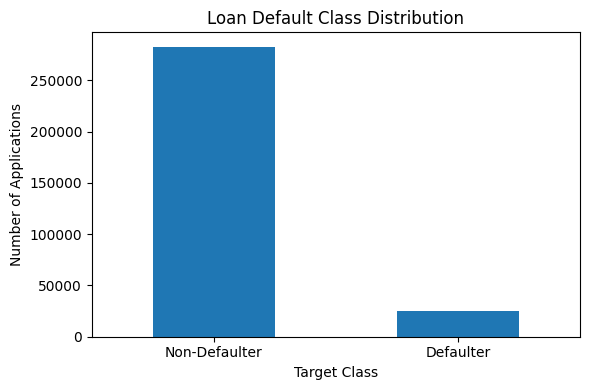

In [ ]:

application_path = os.path.join(folder_path, "application_train.csv")

target_counts = pd.read_csv(
    application_path,
    usecols=["TARGET"]
)["TARGET"].value_counts().sort_index()

print(target_counts)

print("\nTarget proportions:")
print((target_counts / target_counts.sum()).round(4))

target_counts.rename({
    0: "Non-Defaulter",
    1: "Defaulter"
}).plot(kind="bar", figsize=(6, 4), rot=0,
        title="Loan Default Class Distribution")

import matplotlib.pyplot as plt
plt.xlabel("Target Class")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import os

data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

df = pd.read_csv(
    os.path.join(data_path, "application_train.csv"),
    nrows=5
)

print("Dataset preview:")
display(df)

print("\nDataset shape information:")
print("Columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

Dataset preview:


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0



Dataset shape information:
Columns: 122

Column names:
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPL

In [ ]:
import pandas as pd
import os

data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"
file_path = os.path.join(data_path, "application_train.csv")

df = pd.read_csv(file_path)

print("Dataset dimensions:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values (top 20 columns):")
missing = df.isnull().sum().sort_values(ascending=False)
display(missing.head(20).to_frame(name="Missing Count"))

Dataset dimensions: (307511, 122)

First 5 rows:


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB

Missing values (top 20 columns):


,Missing Count
COMMONAREA_AVG,214865
COMMONAREA_MODE,214865
COMMONAREA_MEDI,214865
NONLIVINGAPARTMENTS_MEDI,213514
NONLIVINGAPARTMENTS_MODE,213514
NONLIVINGAPARTMENTS_AVG,213514
FONDKAPREMONT_MODE,210295
LIVINGAPARTMENTS_AVG,210199
LIVINGAPARTMENTS_MEDI,210199
LIVINGAPARTMENTS_MODE,210199


In [ ]:
target_counts = df["TARGET"].value_counts().sort_index()

print("Target counts:")
display(target_counts)

print("\nTarget percentages:")
display((df["TARGET"].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nMissing values in TARGET:", df["TARGET"].isnull().sum())

Target counts:


,count
TARGET,
0,282686
1,24825



Target percentages:


,proportion
TARGET,
0,91.93
1,8.07



Missing values in TARGET: 0


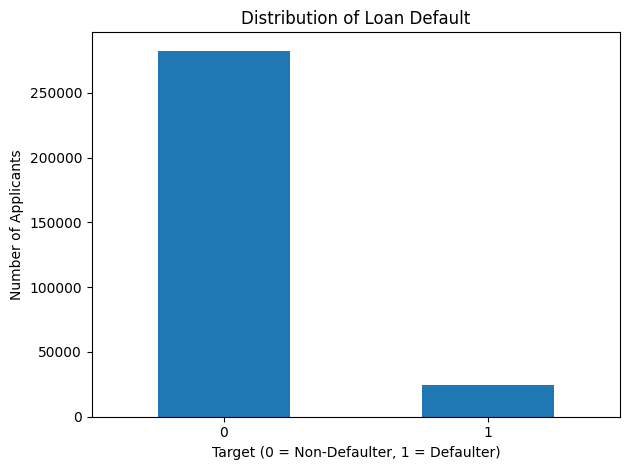

In [ ]:
import matplotlib.pyplot as plt

target_counts.plot(kind="bar")

plt.title("Distribution of Loan Default")
plt.xlabel("Target (0 = Non-Defaulter, 1 = Defaulter)")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary[missing_summary["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_MEDI,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
...,...,...
EXT_SOURCE_2,660,0.21
AMT_GOODS_PRICE,278,0.09
AMT_ANNUITY,12,0.00
CNT_FAM_MEMBERS,2,0.00


In [ ]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

pd.set_option("display.max_rows", None)

display(missing_summary)

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_AVG,214865,69.87
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


In [ ]:
missingness_analysis = []

for col in df.columns:
    if df[col].isnull().any():
        missing_mask = df[col].isnull()

        missing_default_rate = (
            df.loc[missing_mask, "TARGET"].mean() * 100
            if missing_mask.sum() > 0 else None
        )

        present_default_rate = (
            df.loc[~missing_mask, "TARGET"].mean() * 100
            if (~missing_mask).sum() > 0 else None
        )

        missingness_analysis.append({
            "Column": col,
            "Missing_Percentage": missing_mask.mean() * 100,
            "Default_Rate_When_Missing": missing_default_rate,
            "Default_Rate_When_Present": present_default_rate,
            "Difference_Percentage_Points": (
                missing_default_rate - present_default_rate
            )
        })

missingness_df = pd.DataFrame(missingness_analysis)

missingness_df["Missing_Percentage"] = (
    missingness_df["Missing_Percentage"].round(2)
)

missingness_df["Default_Rate_When_Missing"] = (
    missingness_df["Default_Rate_When_Missing"].round(2)
)

missingness_df["Default_Rate_When_Present"] = (
    missingness_df["Default_Rate_When_Present"].round(2)
)

missingness_df["Difference_Percentage_Points"] = (
    missingness_df["Difference_Percentage_Points"].round(2)
)

display(
    missingness_df.sort_values(
        "Difference_Percentage_Points",
        key=lambda s: s.abs(),
        ascending=False
    ).head(20)
)

,Column,Missing_Percentage,Default_Rate_When_Missing,Default_Rate_When_Present,Difference_Percentage_Points
0,AMT_ANNUITY,0.00,0.00,8.07,-8.07
60,DAYS_LAST_PHONE_CHANGE,0.00,0.00,8.07,-8.07
5,CNT_FAM_MEMBERS,0.00,0.00,8.07,-8.07
56,OBS_30_CNT_SOCIAL_CIRCLE,0.33,3.53,8.09,-4.56
59,DEF_60_CNT_SOCIAL_CIRCLE,0.33,3.53,8.09,-4.56
58,OBS_60_CNT_SOCIAL_CIRCLE,0.33,3.53,8.09,-4.56
57,DEF_30_CNT_SOCIAL_CIRCLE,0.33,3.53,8.09,-4.56
2,NAME_TYPE_SUITE,0.42,5.42,8.08,-2.67
62,AMT_REQ_CREDIT_BUREAU_DAY,13.50,10.34,7.72,2.62
63,AMT_REQ_CREDIT_BUREAU_WEEK,13.50,10.34,7.72,2.62


In [ ]:
check_cols = [
    "AMT_ANNUITY",
    "DAYS_LAST_PHONE_CHANGE",
    "CNT_FAM_MEMBERS",
    "OBS_30_CNT_SOCIAL_CIRCLE",
    "NAME_TYPE_SUITE",
    "AMT_REQ_CREDIT_BUREAU_YEAR",
    "OCCUPATION_TYPE"
]

for col in check_cols:
    missing_mask = df[col].isna()

    print(f"\nColumn: {col}")
    print("Missing count:", int(missing_mask.sum()))
    print("Present count:", int((~missing_mask).sum()))

    if missing_mask.sum() > 0:
        print(
            "Default rate when missing:",
            round(df.loc[missing_mask, "TARGET"].mean() * 100, 4), "%"
        )

    print(
        "Default rate when present:",
        round(df.loc[~missing_mask, "TARGET"].mean() * 100, 4), "%"
    )


Column: AMT_ANNUITY
Missing count: 12
Present count: 307499
Default rate when missing: 0.0 %
Default rate when present: 8.0732 %

Column: DAYS_LAST_PHONE_CHANGE
Missing count: 1
Present count: 307510
Default rate when missing: 0.0 %
Default rate when present: 8.0729 %

Column: CNT_FAM_MEMBERS
Missing count: 2
Present count: 307509
Default rate when missing: 0.0 %
Default rate when present: 8.0729 %

Column: OBS_30_CNT_SOCIAL_CIRCLE
Missing count: 1021
Present count: 306490
Default rate when missing: 3.526 %
Default rate when present: 8.088 %

Column: NAME_TYPE_SUITE
Missing count: 1292
Present count: 306219
Default rate when missing: 5.418 %
Default rate when present: 8.0841 %

Column: AMT_REQ_CREDIT_BUREAU_YEAR
Missing count: 41519
Present count: 265992
Default rate when missing: 10.3374 %
Default rate when present: 7.7194 %

Column: OCCUPATION_TYPE
Missing count: 96391
Present count: 211120
Default rate when missing: 6.5131 %
Default rate when present: 8.7851 %


Question 1
What do the applicants in this dataset look like in terms of age, income, employment and loan amount?

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "DAYS_BIRTH"
]

display(df[numeric_cols].describe().T)

df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25

display(df["AGE_YEARS"].describe().to_frame())

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,16524.0,24903.0,34596.0,258025.5
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.0,-19682.0,-15750.0,-12413.0,-7489.0


,AGE_YEARS
count,307511.000000
mean,43.906900
std,11.947950
min,20.503765
25%,33.984942
50%,43.121150
75%,53.886379
max,69.073238


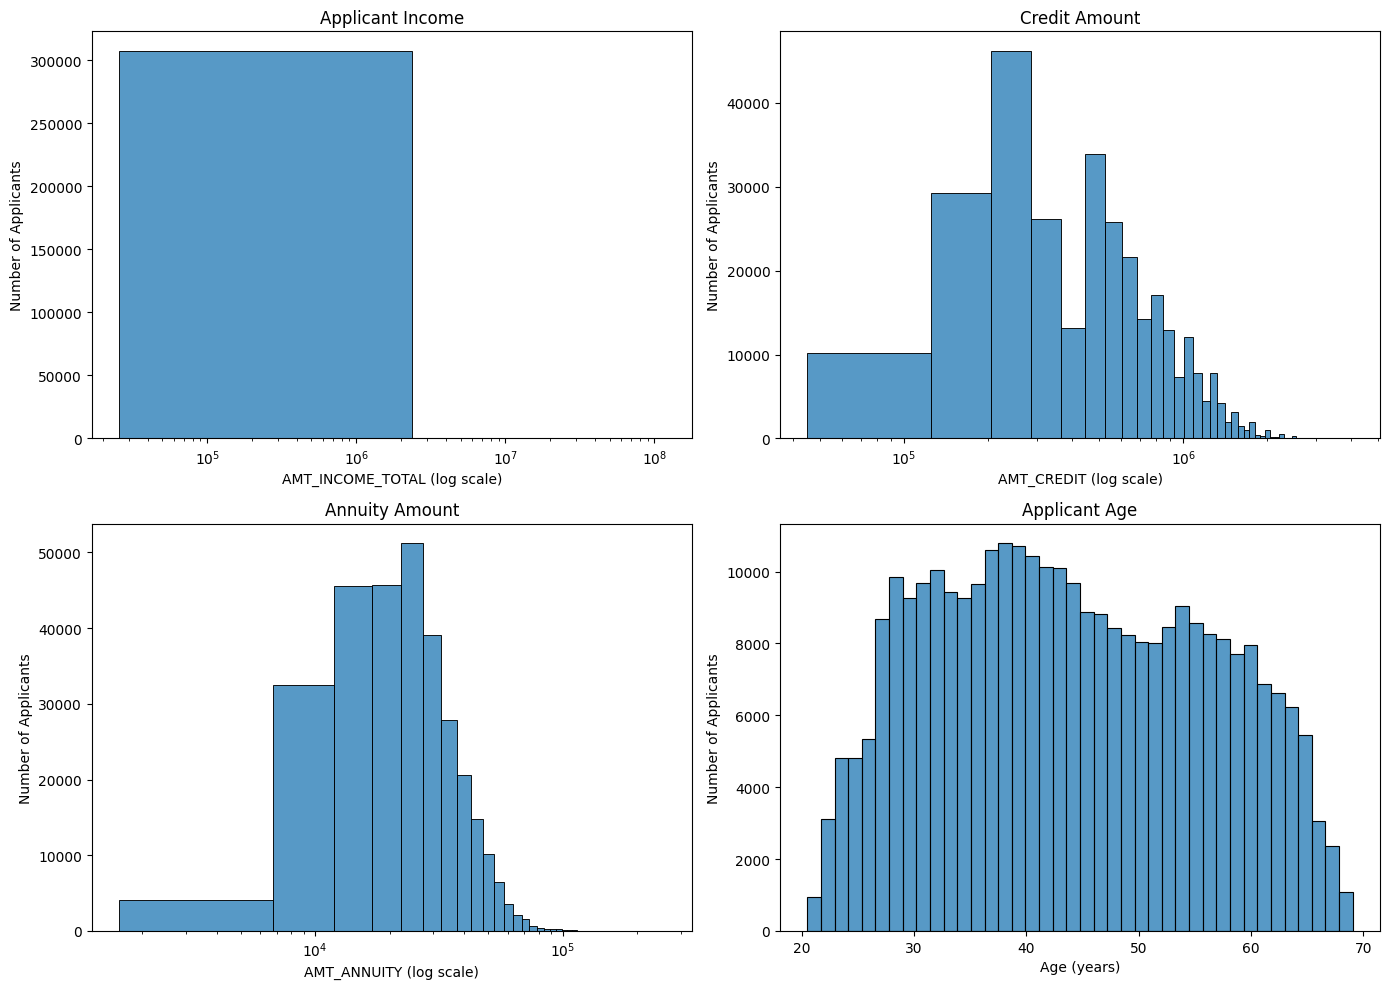

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    ("AMT_INCOME_TOTAL", "Applicant Income"),
    ("AMT_CREDIT", "Credit Amount"),
    ("AMT_ANNUITY", "Annuity Amount"),
    ("AGE_YEARS", "Applicant Age")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (col, title) in zip(axes.flatten(), features):
    values = df[col].dropna()

    if col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]:
        values = values[values > 0]
        sns.histplot(values, bins=50, ax=ax)
        ax.set_xscale("log")
        ax.set_xlabel(f"{col} (log scale)")
    else:
        sns.histplot(values, bins=40, ax=ax)
        ax.set_xlabel("Age (years)")

    ax.set_title(title)
    ax.set_ylabel("Number of Applicants")

plt.tight_layout()
plt.show()

Minimum income: 25650.0
99th percentile income: 472500.0
Maximum income: 117000000.0
Applicants above the 99th percentile: 3014


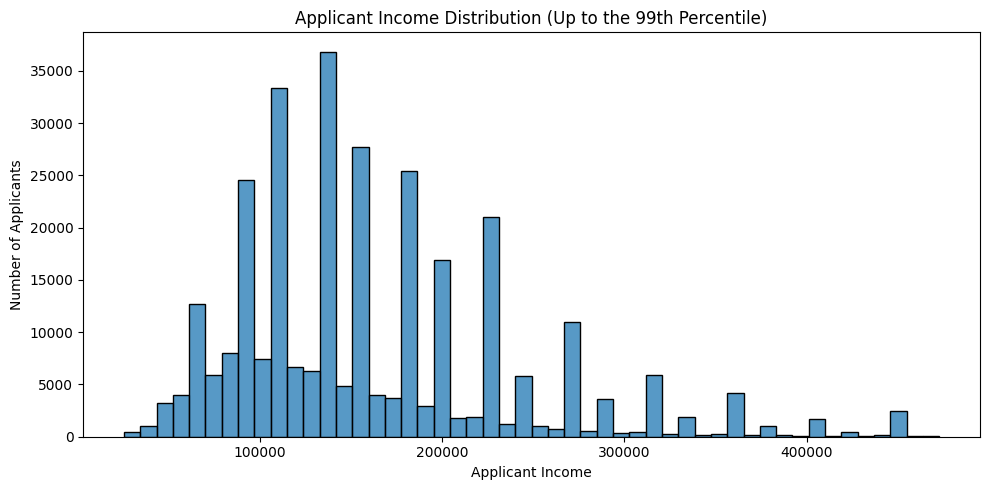

In [ ]:
income = df["AMT_INCOME_TOTAL"].dropna()

lower = income.quantile(0.01)
upper = income.quantile(0.99)

print("Minimum income:", income.min())
print("99th percentile income:", upper)
print("Maximum income:", income.max())
print("Applicants above the 99th percentile:", (income > upper).sum())

plt.figure(figsize=(10, 5))

sns.histplot(
    income[income <= upper],
    bins=50
)

plt.title("Applicant Income Distribution (Up to the 99th Percentile)")
plt.xlabel("Applicant Income")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

Conclusion
What the plot tells us
1. Income is concentrated at certain values. There are pronounced peaks around ₹100,000–₹150,000 and at several higher amounts. This may reflect common reported income levels or the way income was recorded.
2. The distribution is right-skewed. Most applicants fall toward the lower end of the displayed range, while fewer applicants have higher incomes.
3. The distribution is not smooth. The distinct spikes suggest that income values may cluster at particular amounts rather than being spread continuously.
4. The plot excludes the top 1% only for visualization. Those applicants remain in df. We have not established that their incomes are erroneous.

Question 2

Do applicants in different income groups have different observed default rates?

In [ ]:
df["INCOME_GROUP"] = pd.qcut(
    df["AMT_INCOME_TOTAL"],
    q=5,
    duplicates="drop"
)

income_default = (
    df.groupby("INCOME_GROUP", observed=True)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean"),
        Median_Income=("AMT_INCOME_TOTAL", "median")
    )
    .reset_index()
)

income_default["Default_Rate"] = (
    income_default["Default_Rate"] * 100
).round(2)

display(income_default)

,INCOME_GROUP,Applicants,Defaulters,Default_Rate,Median_Income
0,"(25649.999, 99000.0]",63671,5225,8.21,81000.0
1,"(99000.0, 135000.0]",85756,7365,8.59,121500.0
2,"(135000.0, 162000.0]",35453,3079,8.68,157500.0
3,"(162000.0, 225000.0]",75513,6084,8.06,202500.0
4,"(225000.0, 117000000.0]",47118,3072,6.52,292500.0


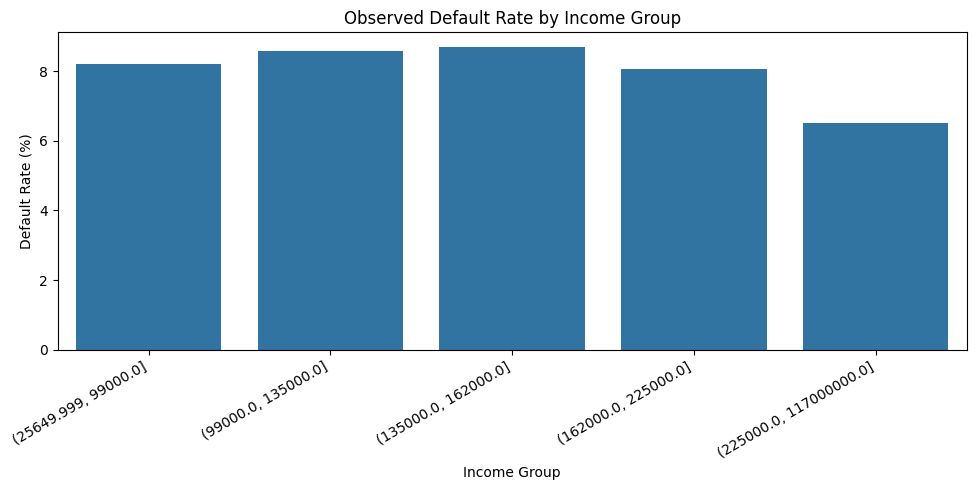

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=income_default,
    x="INCOME_GROUP",
    y="Default_Rate"
)

plt.title("Observed Default Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
df["AGE_GROUP"] = pd.cut(
    df["AGE_YEARS"],
    bins=[20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70],
    right=False
)

age_default = (
    df.groupby("AGE_GROUP", observed=True)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean"),
        Median_Age=("AGE_YEARS", "median")
    )
    .reset_index()
)

age_default["Default_Rate"] = (
    age_default["Default_Rate"] * 100
).round(2)

age_default["Median_Age"] = age_default["Median_Age"].round(1)

display(age_default)

,AGE_GROUP,Applicants,Defaulters,Default_Rate,Median_Age
0,"[20, 25)",12233,1504,12.29,23.4
1,"[25, 30)",32953,3667,11.13,27.9
2,"[30, 35)",39476,4054,10.27,32.4
3,"[35, 40)",42855,3843,8.97,37.6
4,"[40, 45)",41406,3242,7.83,42.4
5,"[45, 50)",35193,2611,7.42,47.4
6,"[50, 55)",34997,2335,6.67,52.7
7,"[55, 60)",33097,1833,5.54,57.5
8,"[60, 65)",27425,1448,5.28,62.4
9,"[65, 70)",7876,288,3.66,66.4


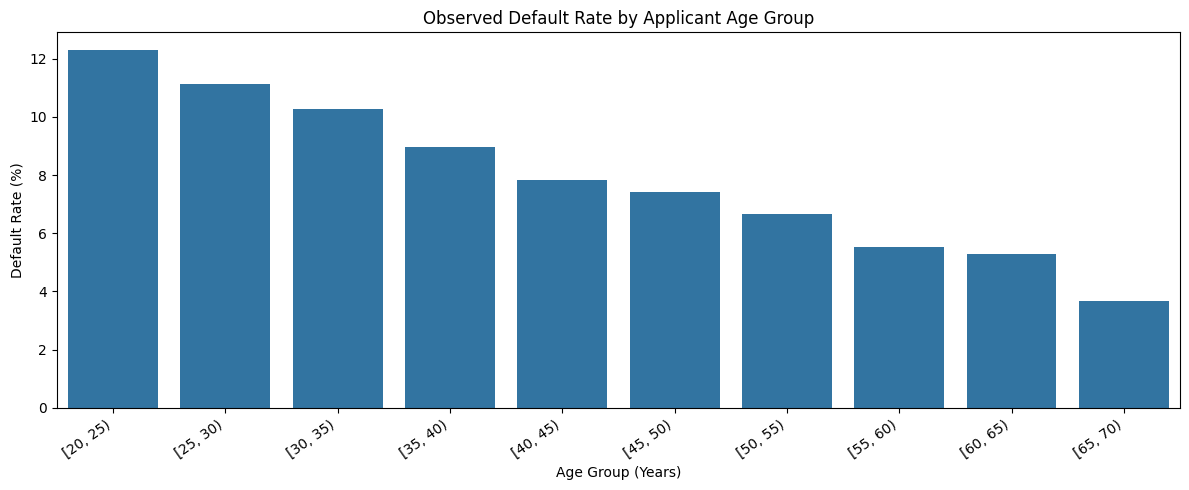

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=age_default,
    x="AGE_GROUP",
    y="Default_Rate"
)

plt.title("Observed Default Rate by Applicant Age Group")
plt.xlabel("Age Group (Years)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Conclusion

Age is a promising predictive feature. The pattern is consistent across the age groups shown.



The relationship appears nonlinear. The default rate does not decrease by the same amount in every five-year interval.



Age alone is not sufficient. Income, credit amount, employment, repayment history and other characteristics may also affect predictions.



This is an association, not causation. We cannot conclude that increasing age itself causes default risk to fall.

Income appears to be associated with default outcomes in this dataset.



Applicants in the highest income group have a lower observed default rate than applicants in the other groups.



Income alone does not explain default: other financial and demographic characteristics may contribute to the pattern.



These are descriptive findings, not evidence that changing income causes a change in default risk.

Question 3

Do applicants with larger credit amounts have different observed default rates?

In [ ]:
df["CREDIT_GROUP"] = pd.qcut(
    df["AMT_CREDIT"],
    q=5,
    duplicates="drop"
)

credit_default = (
    df.groupby("CREDIT_GROUP", observed=True)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean"),
        Median_Credit=("AMT_CREDIT", "median")
    )
    .reset_index()
)

credit_default["Default_Rate"] = (
    credit_default["Default_Rate"] * 100
).round(2)

display(credit_default)

,CREDIT_GROUP,Applicants,Defaulters,Default_Rate,Median_Credit
0,"(44999.999, 254700.0]",64925,4699,7.24,180000.0
1,"(254700.0, 432000.0]",58098,5329,9.17,312840.0
2,"(432000.0, 604152.0]",61552,6189,10.05,513531.0
3,"(604152.0, 900000.0]",64024,5029,7.85,755190.0
4,"(900000.0, 4050000.0]",58912,3579,6.08,1168452.0


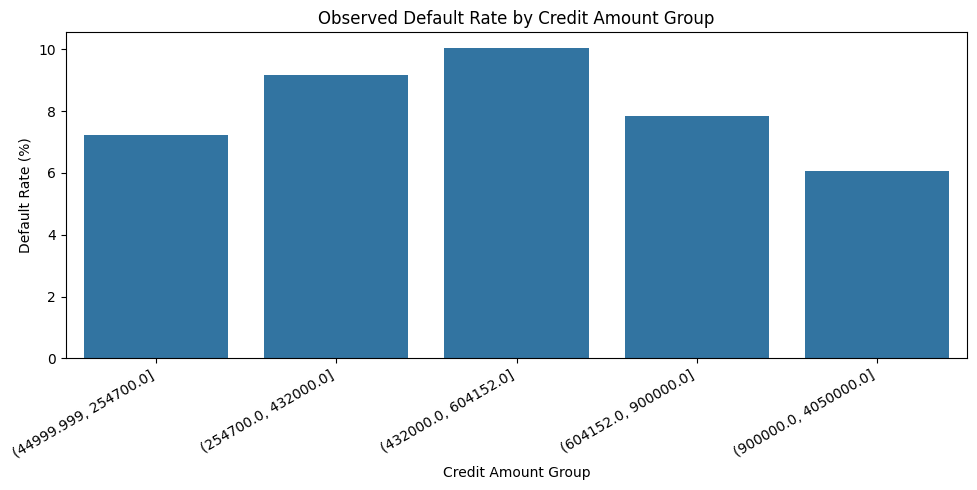

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=credit_default,
    x="CREDIT_GROUP",
    y="Default_Rate"
)

plt.title("Observed Default Rate by Credit Amount Group")
plt.xlabel("Credit Amount Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
income_type_default = (
    df.groupby("NAME_INCOME_TYPE", dropna=False)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

income_type_default["Default_Rate"] = (
    income_type_default["Default_Rate"] * 100
).round(2)

display(
    income_type_default.sort_values(
        "Default_Rate",
        ascending=False
    )
)

,NAME_INCOME_TYPE,Applicants,Defaulters,Default_Rate
2,Maternity leave,5,2,40.00
6,Unemployed,22,8,36.36
7,Working,158774,15224,9.59
1,Commercial associate,71617,5360,7.48
4,State servant,21703,1249,5.75
3,Pensioner,55362,2982,5.39
0,Businessman,10,0,0.00
5,Student,18,0,0.00


In [ ]:
occupation_default = (
    df.groupby("OCCUPATION_TYPE", dropna=False)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

occupation_default["Default_Rate"] = (
    occupation_default["Default_Rate"] * 100
).round(2)

display(
    occupation_default.sort_values(
        "Default_Rate",
        ascending=False
    )
)

,OCCUPATION_TYPE,Applicants,Defaulters,Default_Rate
9,Low-skill Laborers,2093,359,17.15
4,Drivers,18603,2107,11.33
17,Waiters/barmen staff,1348,152,11.28
16,Security staff,6721,722,10.74
8,Laborers,55186,5838,10.58
2,Cooking staff,5946,621,10.44
14,Sales staff,32102,3092,9.63
1,Cleaning staff,4653,447,9.61
13,Realty agents,751,59,7.86
15,Secretaries,1305,92,7.05


,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AGE_YEARS,TARGET
AMT_INCOME_TOTAL,1.000,0.157,0.192,-0.027,-0.004
AMT_CREDIT,0.157,1.000,0.770,0.055,-0.030
AMT_ANNUITY,0.192,0.770,1.000,-0.009,-0.013
AGE_YEARS,-0.027,0.055,-0.009,1.000,-0.078
TARGET,-0.004,-0.030,-0.013,-0.078,1.000


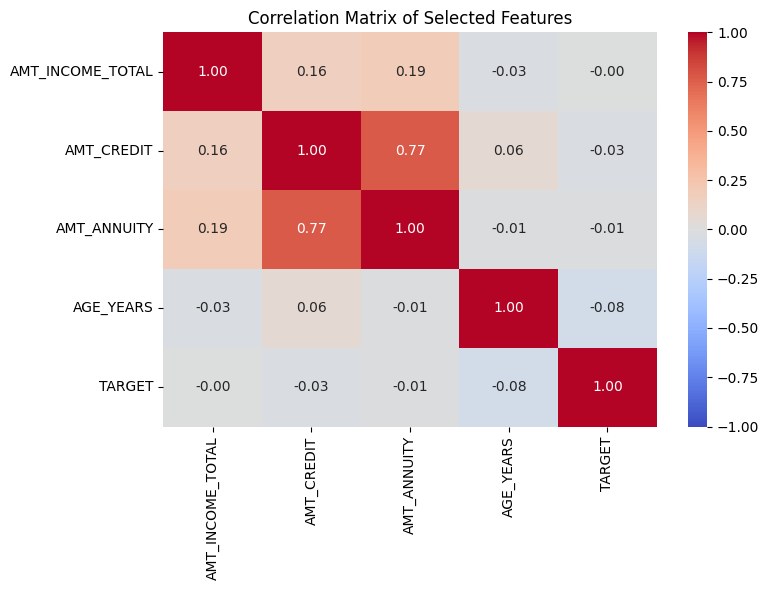

In [ ]:
correlation_cols = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AGE_YEARS",
    "TARGET"
]

correlation_matrix = df[correlation_cols].corr()

display(correlation_matrix.round(3))

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Selected Features")
plt.tight_layout()
plt.show()

In [ ]:
contract_default = (
    df.groupby("NAME_CONTRACT_TYPE")
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

contract_default["Default_Rate"] = (
    contract_default["Default_Rate"] * 100
).round(2)

display(contract_default)

,NAME_CONTRACT_TYPE,Applicants,Defaulters,Default_Rate
0,Cash loans,278232,23221,8.35
1,Revolving loans,29279,1604,5.48


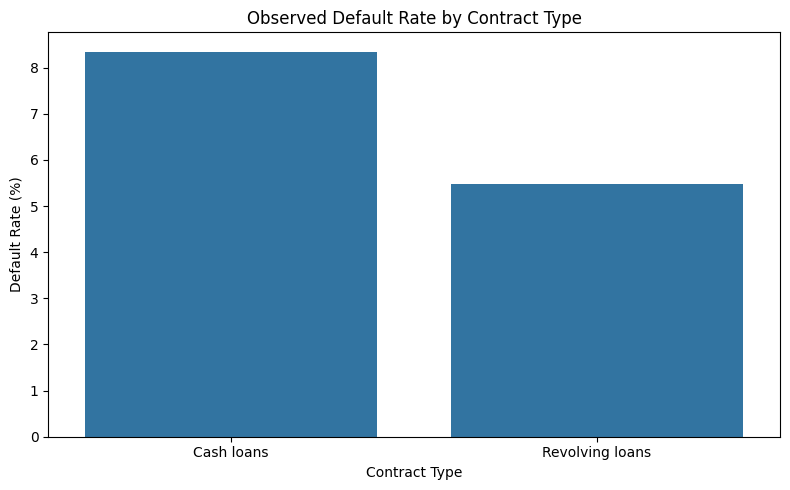

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=contract_default,
    x="NAME_CONTRACT_TYPE",
    y="Default_Rate"
)

plt.title("Observed Default Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()

In [ ]:
education_default = (
    df.groupby("NAME_EDUCATION_TYPE", dropna=False)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

education_default["Default_Rate"] = (
    education_default["Default_Rate"] * 100
).round(2)

display(
    education_default.sort_values(
        "Default_Rate",
        ascending=False
    )
)

,NAME_EDUCATION_TYPE,Applicants,Defaulters,Default_Rate
3,Lower secondary,3816,417,10.93
4,Secondary / secondary special,218391,19524,8.94
2,Incomplete higher,10277,872,8.48
1,Higher education,74863,4009,5.36
0,Academic degree,164,3,1.83


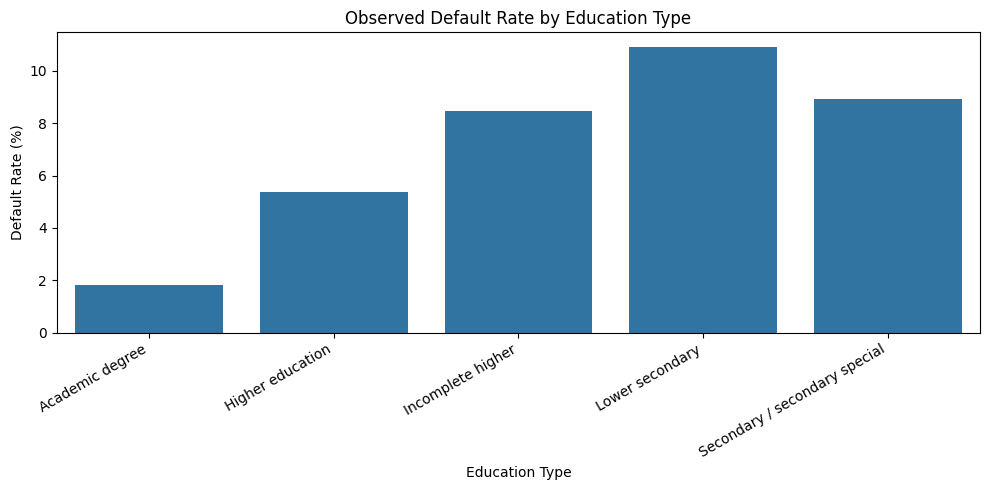

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=education_default,
    x="NAME_EDUCATION_TYPE",
    y="Default_Rate"
)

plt.title("Observed Default Rate by Education Type")
plt.xlabel("Education Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
family_default = (
    df.groupby("NAME_FAMILY_STATUS", dropna=False)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

family_default["Default_Rate"] = (
    family_default["Default_Rate"] * 100
).round(2)

display(
    family_default.sort_values(
        "Default_Rate",
        ascending=False
    )
)

housing_default = (
    df.groupby("NAME_HOUSING_TYPE", dropna=False)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

housing_default["Default_Rate"] = (
    housing_default["Default_Rate"] * 100
).round(2)

display(
    housing_default.sort_values(
        "Default_Rate",
        ascending=False
    )
)


,NAME_FAMILY_STATUS,Applicants,Defaulters,Default_Rate
0,Civil marriage,29775,2961,9.94
3,Single / not married,45444,4457,9.81
2,Separated,19770,1620,8.19
1,Married,196432,14850,7.56
5,Widow,16088,937,5.82
4,Unknown,2,0,0.00


,NAME_HOUSING_TYPE,Applicants,Defaulters,Default_Rate
4,Rented apartment,4881,601,12.31
5,With parents,14840,1736,11.70
2,Municipal apartment,11183,955,8.54
0,Co-op apartment,1122,89,7.93
1,House / apartment,272868,21272,7.80
3,Office apartment,2617,172,6.57


In [ ]:
print("Total rows:", len(df))

print("Duplicate rows across all columns:", df.duplicated().sum())

print("Duplicate applicant IDs:", df["SK_ID_CURR"].duplicated().sum())

print("Unique applicant IDs:", df["SK_ID_CURR"].nunique())

Total rows: 307511
Duplicate rows across all columns: 0
Duplicate applicant IDs: 0
Unique applicant IDs: 307511


In [ ]:
# 1. Numerical columns with negative values
numeric_df = df.select_dtypes(include="number")

negative_counts = (numeric_df < 0).sum()
negative_counts = negative_counts[negative_counts > 0]

print("Numerical columns containing negative values:")
display(negative_counts.to_frame("Negative_Value_Count"))

Numerical columns containing negative values:


,Negative_Value_Count
DAYS_BIRTH,307511
DAYS_EMPLOYED,252135
DAYS_REGISTRATION,307431
DAYS_ID_PUBLISH,307495
DAYS_LAST_PHONE_CHANGE,269838


In [ ]:
# 2. Unique values in selected categorical columns
categorical_cols = [
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "OCCUPATION_TYPE"
]

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


NAME_CONTRACT_TYPE
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

CODE_GENDER
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

NAME_EDUCATION_TYPE
NAME_EDUCATION_TYPE
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64

NAME_FAMILY_STATUS
NAME_FAMILY_STATUS
Married                 196432
Single / not married     45444
Civil marriage           29775
Separated                19770
Widow                    16088
Unknown             

In [ ]:
gender_default = (
    df.groupby("CODE_GENDER", dropna=False)
    .agg(
        Applicants=("TARGET", "size"),
        Defaulters=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

gender_default["Default_Rate"] = (
    gender_default["Default_Rate"] * 100
).round(2)

display(gender_default)

,CODE_GENDER,Applicants,Defaulters,Default_Rate
0,F,202448,14170,7.00
1,M,105059,10655,10.14
2,XNA,4,0,0.00


In [ ]:
bureau_path = os.path.join(data_path, "bureau.csv")

bureau_sample = pd.read_csv(bureau_path, nrows=5)

print("Bureau sample:")
display(bureau_sample)

print("\nColumns:")
print(bureau_sample.columns.tolist())

Bureau sample:


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN



Columns:
['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']


In [ ]:
bureau_path = os.path.join(data_path, "bureau.csv")

bureau_sample = pd.read_csv(bureau_path, nrows=5)

print("Bureau sample:")
display(bureau_sample)

print("\nColumns:")
print(bureau_sample.columns.tolist())

Bureau sample:


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN



Columns:
['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']


In [ ]:

# Step 30C: Basic data quality checks for bureau.csv

bureau_path = os.path.join(data_path, "bureau.csv")
bureau = pd.read_csv(bureau_path)

print("Dataset shape:", bureau.shape)

print("\nNumber of unique applicants:")
print(bureau["SK_ID_CURR"].nunique())

print("\nNumber of unique bureau records:")
print(bureau["SK_ID_BUREAU"].nunique())

print("\nDuplicate bureau record IDs:")
print(bureau["SK_ID_BUREAU"].duplicated().sum())

print("\nMissing values in each column:")
missing = bureau.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
display(missing.to_frame(name="Missing_Count"))

print("\nPercentage of missing values:")
missing_percent = (
    bureau.isnull().mean().mul(100)
    .sort_values(ascending=False)
)
display(missing_percent[missing_percent > 0].to_frame(
    name="Missing_Percentage"
))


Dataset shape: (1716428, 17)

Number of unique applicants:
305811

Number of unique bureau records:
1716428

Duplicate bureau record IDs:
0

Missing values in each column:


,Missing_Count
AMT_ANNUITY,1226791
AMT_CREDIT_MAX_OVERDUE,1124488
DAYS_ENDDATE_FACT,633653
AMT_CREDIT_SUM_LIMIT,591780
AMT_CREDIT_SUM_DEBT,257669
DAYS_CREDIT_ENDDATE,105553
AMT_CREDIT_SUM,13



Percentage of missing values:


,Missing_Percentage
AMT_ANNUITY,71.473490
AMT_CREDIT_MAX_OVERDUE,65.513264
DAYS_ENDDATE_FACT,36.916958
AMT_CREDIT_SUM_LIMIT,34.477415
AMT_CREDIT_SUM_DEBT,15.011932
DAYS_CREDIT_ENDDATE,6.149573
AMT_CREDIT_SUM,0.000757


In [ ]:

# Step 31.1: Distribution of credit account status

print("Credit account status counts:")
display(bureau["CREDIT_ACTIVE"].value_counts(dropna=False))

print("\nCredit account status percentages:")
display(
    bureau["CREDIT_ACTIVE"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)


Credit account status counts:


,count
CREDIT_ACTIVE,
Closed,1079273
Active,630607
Sold,6527
Bad debt,21



Credit account status percentages:


,proportion
CREDIT_ACTIVE,
Closed,62.88
Active,36.74
Sold,0.38
Bad debt,0.00


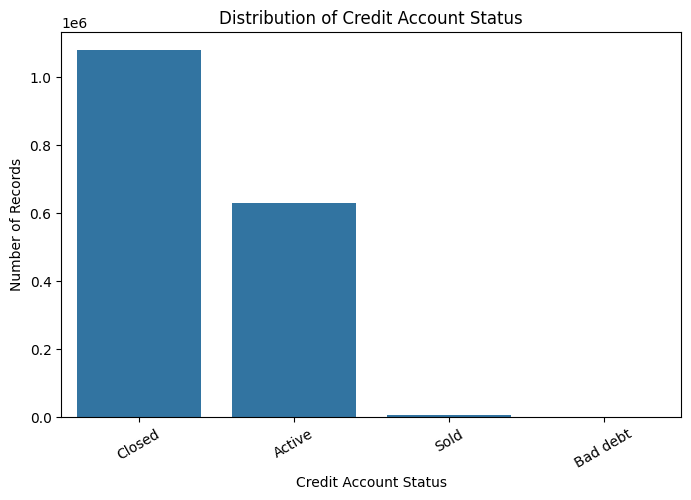

In [ ]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=bureau,
    x="CREDIT_ACTIVE",
    order=bureau["CREDIT_ACTIVE"].value_counts().index
)

plt.title("Distribution of Credit Account Status")
plt.xlabel("Credit Account Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.show()


In [ ]:

# Step 31.3: Merge target information into bureau records

bureau_target = bureau.merge(
    df[["SK_ID_CURR", "TARGET"]],
    on="SK_ID_CURR",
    how="left"
)

status_default = (
    bureau_target.groupby("CREDIT_ACTIVE")
    .agg(
        Total_Records=("SK_ID_BUREAU", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

status_default["Default_Rate"] = (
    status_default["Default_Rate"] * 100
).round(2)

display(status_default)


,CREDIT_ACTIVE,Total_Records,Defaulter_Records,Default_Rate
0,Active,630607,50336.0,9.29
1,Bad debt,21,4.0,20.00
2,Closed,1079273,63609.0,6.93
3,Sold,6527,571.0,10.10


In [ ]:

status_check = (
    bureau_target.groupby("CREDIT_ACTIVE")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum")
    )
    .reset_index()
)

status_check["Calculated_Default_Rate"] = (
    status_check["Defaulter_Records"]
    / status_check["Total_Records"] * 100
).round(2)

display(status_check)


,CREDIT_ACTIVE,Total_Records,Defaulter_Records,Calculated_Default_Rate
0,Active,541919,50336.0,9.29
1,Bad debt,20,4.0,20.00
2,Closed,917733,63609.0,6.93
3,Sold,5653,571.0,10.10


In [ ]:

# Step 32: Distribution of credit types

print("Credit type counts:")
display(bureau["CREDIT_TYPE"].value_counts(dropna=False))

print("\nCredit type percentages:")
display(
    (bureau["CREDIT_TYPE"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)


Credit type counts:


,count
CREDIT_TYPE,
Consumer credit,1251615
Credit card,402195
Car loan,27690
Mortgage,18391
Microloan,12413
Loan for business development,1975
Another type of loan,1017
Unknown type of loan,555
Loan for working capital replenishment,469



Credit type percentages:


,proportion
CREDIT_TYPE,
Consumer credit,72.92
Credit card,23.43
Car loan,1.61
Mortgage,1.07
Microloan,0.72
Loan for business development,0.12
Another type of loan,0.06
Unknown type of loan,0.03
Loan for working capital replenishment,0.03


In [ ]:

# Analyse previous credit types against current loan default

credit_type_analysis = (
    bureau_target.groupby("CREDIT_TYPE")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

credit_type_analysis["Default_Rate"] = (
    credit_type_analysis["Default_Rate"] * 100
).round(2)

credit_type_analysis = credit_type_analysis.sort_values(
    by="Default_Rate",
    ascending=False
)

display(credit_type_analysis)


,CREDIT_TYPE,Total_Records,Defaulter_Records,Default_Rate
8,Loan for the purchase of equipment,17,4.0,23.53
10,Microloan,9005,1859.0,20.64
9,Loan for working capital replenishment,377,48.0,12.73
4,Credit card,343853,30262.0,8.80
3,Consumer credit,1069610,80046.0,7.48
0,Another type of loan,854,61.0,7.14
6,Loan for business development,1721,106.0,6.16
14,Unknown type of loan,472,29.0,6.14
1,Car loan,23757,1324.0,5.57
12,Mortgage,15607,780.0,5.00


In [ ]:

# Step 33.1: Statistical summary of DAYS_CREDIT

print("DAYS_CREDIT summary:")
display(bureau["DAYS_CREDIT"].describe())

print("\nMissing values:")
print(bureau["DAYS_CREDIT"].isnull().sum())


DAYS_CREDIT summary:


,DAYS_CREDIT
count,1.716428e+06
mean,-1.142108e+03
std,7.951649e+02
min,-2.922000e+03
25%,-1.666000e+03
50%,-9.870000e+02
75%,-4.740000e+02
max,0.000000e+00



Missing values:
0


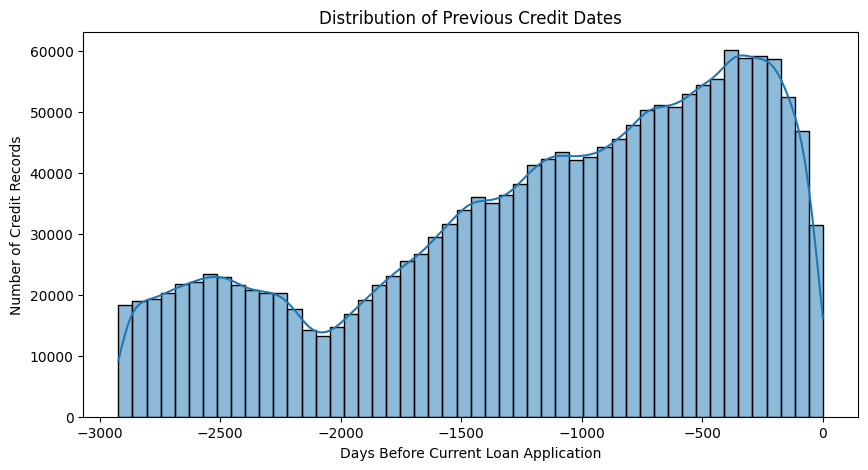

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=bureau,
    x="DAYS_CREDIT",
    bins=50,
    kde=True
)

plt.title("Distribution of Previous Credit Dates")
plt.xlabel("Days Before Current Loan Application")
plt.ylabel("Number of Credit Records")
plt.show()


In [ ]:

# Convert DAYS_CREDIT into years before current application

bureau_target["CREDIT_AGE_YEARS"] = (
    -bureau_target["DAYS_CREDIT"] / 365.25
)

# Create credit age groups
bins = [0, 1, 2, 3, 5, 9]
labels = [
    "0-1 year",
    "1-2 years",
    "2-3 years",
    "3-5 years",
    "5-9 years"
]

bureau_target["CREDIT_AGE_GROUP"] = pd.cut(
    bureau_target["CREDIT_AGE_YEARS"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Compare credit age groups with TARGET
credit_age_analysis = (
    bureau_target.groupby("CREDIT_AGE_GROUP", observed=False)
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

credit_age_analysis["Default_Rate"] = (
    credit_age_analysis["Default_Rate"] * 100
).round(2)

display(credit_age_analysis)


,CREDIT_AGE_GROUP,Total_Records,Defaulter_Records,Default_Rate
0,0-1 year,279132,30340.0,10.87
1,1-2 years,284172,25001.0,8.80
2,2-3 years,237589,17594.0,7.41
3,3-5 years,350924,23427.0,6.68
4,5-9 years,313508,18158.0,5.79


In [ ]:

# Step 34.1: Statistical summary of CREDIT_DAY_OVERDUE

print("CREDIT_DAY_OVERDUE summary:")
display(bureau["CREDIT_DAY_OVERDUE"].describe())

print("\nMissing values:")
print(bureau["CREDIT_DAY_OVERDUE"].isnull().sum())

print("\nNumber of records with overdue days:")
print((bureau["CREDIT_DAY_OVERDUE"] > 0).sum())


CREDIT_DAY_OVERDUE summary:


,CREDIT_DAY_OVERDUE
count,1.716428e+06
mean,8.181666e-01
std,3.654443e+01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,2.792000e+03



Missing values:
0

Number of records with overdue days:
4217


In [ ]:

# Create overdue status categories

bureau_target["OVERDUE_STATUS"] = np.where(
    bureau_target["CREDIT_DAY_OVERDUE"] > 0,
    "Overdue",
    "Not Overdue"
)

# Compare with current loan default

overdue_analysis = (
    bureau_target.groupby("OVERDUE_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

overdue_analysis["Default_Rate"] = (
    overdue_analysis["Default_Rate"] * 100
).round(2)

display(overdue_analysis)




,OVERDUE_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Not Overdue,1461619,113845.0,7.79
1,Overdue,3706,675.0,18.21


In [ ]:

# Step 35.1: Statistical summary of AMT_CREDIT_SUM

print("AMT_CREDIT_SUM summary:")
display(bureau["AMT_CREDIT_SUM"].describe())

print("\nMissing values:")
print(bureau["AMT_CREDIT_SUM"].isnull().sum())


AMT_CREDIT_SUM summary:


,AMT_CREDIT_SUM
count,1.716415e+06
mean,3.549946e+05
std,1.149811e+06
min,0.000000e+00
25%,5.130000e+04
50%,1.255185e+05
75%,3.150000e+05
max,5.850000e+08



Missing values:
13


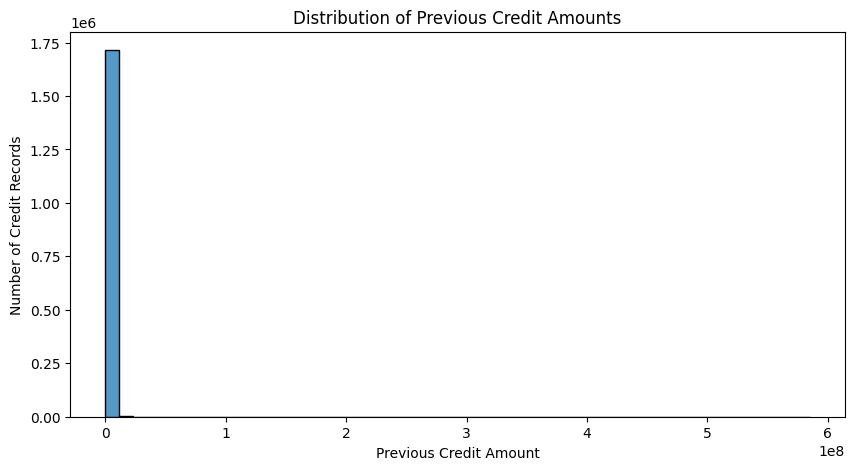

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=bureau,
    x="AMT_CREDIT_SUM",
    bins=50
)

plt.title("Distribution of Previous Credit Amounts")
plt.xlabel("Previous Credit Amount")
plt.ylabel("Number of Credit Records")
plt.show()


In [ ]:

# Examine extreme values in AMT_CREDIT_SUM

print("Selected percentiles:")

percentiles = bureau["AMT_CREDIT_SUM"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

display(percentiles.to_frame(name="Credit_Amount"))

print("\nLargest 10 credit amounts:")

display(
    bureau["AMT_CREDIT_SUM"]
    .nlargest(10)
    .to_frame(name="AMT_CREDIT_SUM")
)


Selected percentiles:


,Credit_Amount
0.900,7.787547e+05
0.950,1.350000e+06
0.990,3.700916e+06
0.995,5.796000e+06
0.999,1.102100e+07



Largest 10 credit amounts:


,AMT_CREDIT_SUM
1515147,585000000.0
907821,396000000.0
489961,170100000.0
488411,164032200.0
1681052,146958507.0
1190163,142290000.0
488416,135000000.0
800744,135000000.0
1239127,135000000.0
716827,132750000.0


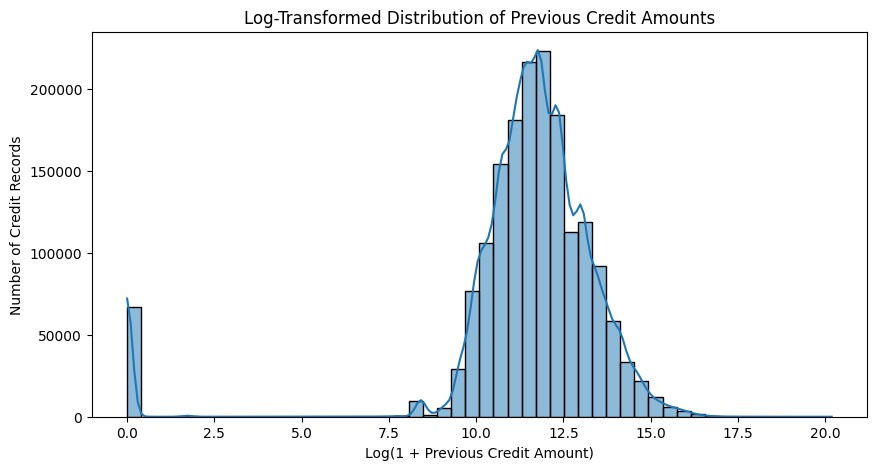

In [ ]:

# Logarithmic visualisation of credit amounts

plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(bureau["AMT_CREDIT_SUM"].dropna()),
    bins=50,
    kde=True
)

plt.title("Log-Transformed Distribution of Previous Credit Amounts")
plt.xlabel("Log(1 + Previous Credit Amount)")
plt.ylabel("Number of Credit Records")

plt.show()


In [ ]:

# Inspect the 10 largest previous credit records

extreme_credit_records = (
    bureau.nlargest(10, "AMT_CREDIT_SUM")
    [[
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "CREDIT_ACTIVE",
        "CREDIT_TYPE",
        "AMT_CREDIT_SUM",
        "AMT_CREDIT_SUM_DEBT",
        "AMT_CREDIT_SUM_OVERDUE",
        "DAYS_CREDIT"
    ]]
)

display(extreme_credit_records)


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_TYPE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_OVERDUE,DAYS_CREDIT
1515147,386819,6706880,Closed,Consumer credit,585000000.0,NaN,0.0,-2683
907821,325979,5671169,Closed,Consumer credit,396000000.0,0.0,0.0,-2867
489961,363076,5090928,Active,Consumer credit,170100000.0,170100000.0,0.0,-1006
488411,363076,5089138,Active,Consumer credit,164032200.0,164032200.0,0.0,-1127
1681052,333770,6657413,Closed,Loan for business development,146958507.0,NaN,0.0,-2824
1190163,134457,5292521,Closed,Mortgage,142290000.0,0.0,0.0,-2350
488416,363076,5089144,Closed,Consumer credit,135000000.0,0.0,0.0,-1287
800744,395290,6508419,Active,Consumer credit,135000000.0,0.0,0.0,-671
1239127,395290,5918655,Active,Consumer credit,135000000.0,0.0,0.0,-671
716827,442645,6489006,Closed,Consumer credit,132750000.0,0.0,0.0,-2910


In [ ]:

# Step 35.4: Previous credit amount vs loan default

# Keep records with known credit amounts and TARGET
credit_amount_data = bureau_target[
    bureau_target["AMT_CREDIT_SUM"].notna()
    & bureau_target["TARGET"].notna()
].copy()

# Divide credit amounts into five quantile groups
credit_amount_data["CREDIT_AMOUNT_GROUP"] = pd.qcut(
    credit_amount_data["AMT_CREDIT_SUM"],
    q=5,
    duplicates="drop"
)

# Calculate default rates
credit_amount_analysis = (
    credit_amount_data.groupby(
        "CREDIT_AMOUNT_GROUP",
        observed=False
    )
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean"),
        Median_Credit_Amount=("AMT_CREDIT_SUM", "median")
    )
    .reset_index()
)

credit_amount_analysis["Default_Rate"] = (
    credit_amount_analysis["Default_Rate"] * 100
).round(2)

display(credit_amount_analysis)


,CREDIT_AMOUNT_GROUP,Total_Records,Defaulter_Records,Default_Rate,Median_Credit_Amount
0,"(-0.001, 42750.0]",293415,25233.0,8.60,22500.0
1,"(42750.0, 90000.0]",311485,23753.0,7.63,66960.0
2,"(90000.0, 170640.0]",274348,20561.0,7.49,128250.0
3,"(170640.0, 413221.5]",293010,22472.0,7.67,237150.0
4,"(413221.5, 396000000.0]",293064,22501.0,7.68,765000.0


In [ ]:

# Step 36.1: Statistical summary of outstanding debt

print("AMT_CREDIT_SUM_DEBT summary:")
display(bureau["AMT_CREDIT_SUM_DEBT"].describe())

print("\nMissing values:")
print(bureau["AMT_CREDIT_SUM_DEBT"].isnull().sum())

print("\nZero debt records:")
print((bureau["AMT_CREDIT_SUM_DEBT"] == 0).sum())

print("\nPositive debt records:")
print((bureau["AMT_CREDIT_SUM_DEBT"] > 0).sum())


AMT_CREDIT_SUM_DEBT summary:


,AMT_CREDIT_SUM_DEBT
count,1.458759e+06
mean,1.370851e+05
std,6.774011e+05
min,-4.705600e+06
25%,0.000000e+00
50%,0.000000e+00
75%,4.015350e+04
max,1.701000e+08



Missing values:
257669

Zero debt records:
1016434

Positive debt records:
433907


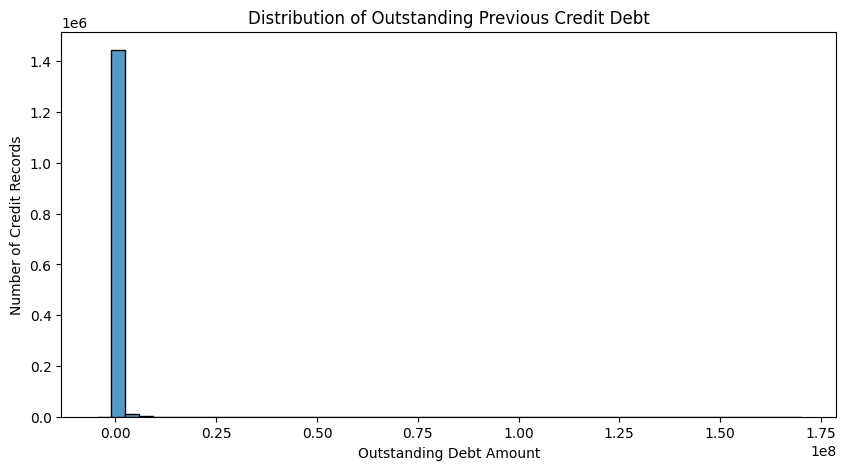

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    bureau["AMT_CREDIT_SUM_DEBT"].dropna(),
    bins=50
)

plt.title("Distribution of Outstanding Previous Credit Debt")
plt.xlabel("Outstanding Debt Amount")
plt.ylabel("Number of Credit Records")
plt.show()


In [ ]:

# Step 36.1: Investigate outstanding debt values

debt = bureau["AMT_CREDIT_SUM_DEBT"]

print("Missing values:", debt.isna().sum())

print("Zero debt records:", (debt == 0).sum())

print("Negative debt records:", (debt < 0).sum())

print("Positive debt records:", (debt > 0).sum())

print("\nPercentage distribution:")

print("Zero:", round((debt == 0).mean() * 100, 2), "%")
print("Negative:", round((debt < 0).mean() * 100, 2), "%")
print("Positive:", round((debt > 0).mean() * 100, 2), "%")
print("Missing:", round(debt.isna().mean() * 100, 2), "%")


Missing values: 257669
Zero debt records: 1016434
Negative debt records: 8418
Positive debt records: 433907

Percentage distribution:
Zero: 59.22 %
Negative: 0.49 %
Positive: 25.28 %
Missing: 15.01 %


In [ ]:

print("Debt percentiles:")

display(
    debt.quantile([0.90, 0.95, 0.99, 0.995, 0.999])
    .to_frame(name="Outstanding_Debt")
)

print("\n10 lowest debt values:")
display(debt.nsmallest(10).to_frame())

print("\n10 highest debt values:")
display(debt.nlargest(10).to_frame())


Debt percentiles:


,Outstanding_Debt
0.900,2.954565e+05
0.950,6.289024e+05
0.990,2.259728e+06
0.995,3.785977e+06
0.999,8.841942e+06



10 lowest debt values:


,AMT_CREDIT_SUM_DEBT
82859,-4705600.320
518329,-3109510.980
775308,-2796723.720
82858,-2273021.730
720176,-2167229.340
1441920,-2089184.310
1438415,-2014753.455
720516,-1764858.060
67992,-1354875.615
163134,-1093553.235



10 highest debt values:


,AMT_CREDIT_SUM_DEBT
489961,170100000.0
488411,164032200.0
1653626,65441403.0
1609469,64570243.5
1701166,62218953.0
628833,59637690.0
1653624,51750000.0
824842,51365155.5
116227,47406861.0
1063507,44968383.0


In [ ]:

# Inspect the 10 most negative debt records

negative_debt_records = (
    bureau.nsmallest(10, "AMT_CREDIT_SUM_DEBT")
    [[
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "CREDIT_ACTIVE",
        "CREDIT_TYPE",
        "AMT_CREDIT_SUM",
        "AMT_CREDIT_SUM_DEBT",
        "AMT_CREDIT_SUM_OVERDUE",
        "DAYS_CREDIT"
    ]]
)

display(negative_debt_records)


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_TYPE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_OVERDUE,DAYS_CREDIT
82859,316058,5262220,Active,Credit card,0.0,-4705600.320,0.0,-774
518329,187109,6461787,Active,Credit card,0.0,-3109510.980,0.0,-880
775308,268156,5406590,Active,Credit card,4500.0,-2796723.720,0.0,-1193
82858,316058,5262219,Active,Credit card,0.0,-2273021.730,0.0,-924
720176,146988,6493134,Active,Credit card,675000.0,-2167229.340,0.0,-1160
1441920,237440,6696988,Active,Credit card,0.0,-2089184.310,0.0,-702
1438415,160759,5400833,Active,Credit card,0.0,-2014753.455,0.0,-823
720516,198204,6493578,Active,Credit card,4500.0,-1764858.060,0.0,-1498
67992,453726,5007734,Active,Credit card,4500.0,-1354875.615,0.0,-1476
163134,367088,6252187,Active,Credit card,675000.0,-1093553.235,0.0,-1188


In [ ]:

# Inspect the 10 largest positive debt records

positive_debt_records = (
    bureau.nlargest(10, "AMT_CREDIT_SUM_DEBT")
    [[
        "SK_ID_CURR",
        "SK_ID_BUREAU",
        "CREDIT_ACTIVE",
        "CREDIT_TYPE",
        "AMT_CREDIT_SUM",
        "AMT_CREDIT_SUM_DEBT",
        "AMT_CREDIT_SUM_OVERDUE",
        "DAYS_CREDIT"
    ]]
)

display(positive_debt_records)


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_TYPE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_OVERDUE,DAYS_CREDIT
489961,363076,5090928,Active,Consumer credit,170100000.0,170100000.0,0.0,-1006
488411,363076,5089138,Active,Consumer credit,164032200.0,164032200.0,0.0,-1127
1653626,186170,6005836,Active,Mortgage,25813359.0,65441403.0,0.0,-855
1609469,138790,6685960,Active,Mortgage,25695000.0,64570243.5,0.0,-253
1701166,446029,6838475,Active,Mortgage,62203050.0,62218953.0,0.0,-120
628833,206063,5694934,Active,Mortgage,22500000.0,59637690.0,0.0,-363
1653624,121383,6005834,Closed,Consumer credit,51750000.0,51750000.0,0.0,-751
824842,161114,6799966,Active,Mortgage,54000000.0,51365155.5,0.0,-394
116227,395696,5011049,Active,Mortgage,49050000.0,47406861.0,0.0,-828
1063507,405435,6478886,Active,Mortgage,24099462.0,44968383.0,0.0,-1333


In [ ]:

# Step 37: Outstanding debt versus current loan default

debt_data = bureau_target[
    bureau_target["AMT_CREDIT_SUM_DEBT"].notna()
    & bureau_target["TARGET"].notna()
].copy()

# Divide debt into five quantile groups
debt_data["DEBT_GROUP"] = pd.qcut(
    debt_data["AMT_CREDIT_SUM_DEBT"],
    q=5,
    duplicates="drop"
)

# Calculate default statistics
debt_analysis = (
    debt_data.groupby("DEBT_GROUP", observed=False)
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean"),
        Median_Debt=("AMT_CREDIT_SUM_DEBT", "median")
    )
    .reset_index()
)

debt_analysis["Default_Rate"] = (
    debt_analysis["Default_Rate"] * 100
).round(2)

display(debt_analysis)


,DEBT_GROUP,Total_Records,Defaulter_Records,Default_Rate,Median_Debt
0,"(-4705600.321, 0.0]",873068,61777.0,7.08,0.000
1,"(0.0, 89752.5]",120718,12018.0,9.96,40870.935
2,"(89752.5, 170100000.0]",248445,24050.0,9.68,291231.000


In [ ]:

# Separate outstanding debt into three categories

debt_data["DEBT_STATUS"] = np.select(
    [
        debt_data["AMT_CREDIT_SUM_DEBT"] < 0,
        debt_data["AMT_CREDIT_SUM_DEBT"] == 0,
        debt_data["AMT_CREDIT_SUM_DEBT"] > 0
    ],
    [
        "Negative Debt",
        "Zero Debt",
        "Positive Debt"
    ],
    default="Unknown"
)

debt_status_analysis = (
    debt_data.groupby("DEBT_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

debt_status_analysis["Default_Rate"] = (
    debt_status_analysis["Default_Rate"] * 100
).round(2)

display(debt_status_analysis)


,DEBT_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Negative Debt,8418,655.0,7.78
1,Positive Debt,369163,36068.0,9.77
2,Zero Debt,864650,61122.0,7.07


In [ ]:

# Step 38.1: Statistical summary of credit limits

print("AMT_CREDIT_SUM_LIMIT summary:")
display(bureau["AMT_CREDIT_SUM_LIMIT"].describe())

print("\nMissing values:")
print(bureau["AMT_CREDIT_SUM_LIMIT"].isnull().sum())

print("\nZero credit limits:")
print((bureau["AMT_CREDIT_SUM_LIMIT"] == 0).sum())

print("\nNegative credit limits:")
print((bureau["AMT_CREDIT_SUM_LIMIT"] < 0).sum())

print("\nPositive credit limits:")
print((bureau["AMT_CREDIT_SUM_LIMIT"] > 0).sum())


AMT_CREDIT_SUM_LIMIT summary:


,AMT_CREDIT_SUM_LIMIT
count,1.124648e+06
mean,6.229515e+03
std,4.503203e+04
min,-5.864061e+05
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,4.705600e+06



Missing values:
591780

Zero credit limits:
1050142

Negative credit limits:
351

Positive credit limits:
74155


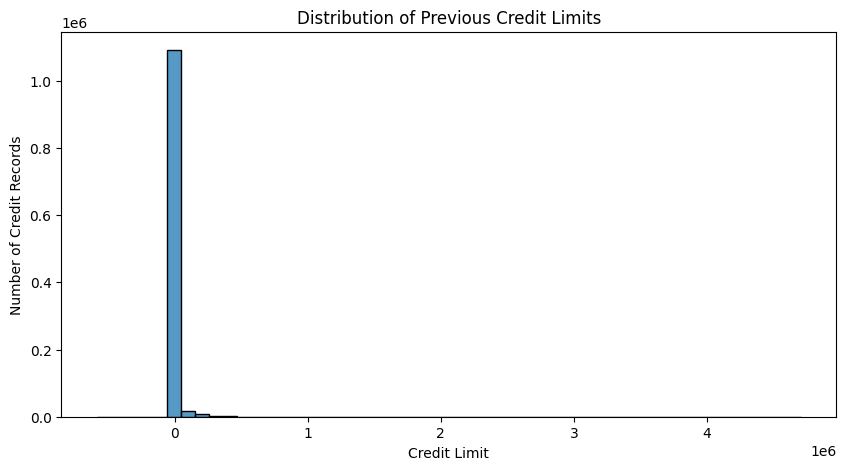

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    bureau["AMT_CREDIT_SUM_LIMIT"].dropna(),
    bins=50
)

plt.title("Distribution of Previous Credit Limits")
plt.xlabel("Credit Limit")
plt.ylabel("Number of Credit Records")
plt.show()


In [ ]:

# Step 38: Basic analysis of previous credit limits

credit_limit = bureau["AMT_CREDIT_SUM_LIMIT"]

print("Statistical Summary:")
display(credit_limit.describe())

print("\nMissing values:", credit_limit.isna().sum())
print("Zero values:", (credit_limit == 0).sum())
print("Negative values:", (credit_limit < 0).sum())
print("Positive values:", (credit_limit > 0).sum())


Statistical Summary:


,AMT_CREDIT_SUM_LIMIT
count,1.124648e+06
mean,6.229515e+03
std,4.503203e+04
min,-5.864061e+05
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,4.705600e+06



Missing values: 591780
Zero values: 1050142
Negative values: 351
Positive values: 74155


In [ ]:

# Step 38.1: Credit limit status versus current loan default

limit_data = bureau_target.copy()

limit_data["CREDIT_LIMIT_STATUS"] = np.select(
    [
        limit_data["AMT_CREDIT_SUM_LIMIT"].isna(),
        limit_data["AMT_CREDIT_SUM_LIMIT"] < 0,
        limit_data["AMT_CREDIT_SUM_LIMIT"] == 0,
        limit_data["AMT_CREDIT_SUM_LIMIT"] > 0
    ],
    [
        "Missing",
        "Negative",
        "Zero",
        "Positive"
    ],
    default="Unknown"
)

limit_analysis = (
    limit_data.groupby("CREDIT_LIMIT_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

limit_analysis["Default_Rate"] = (
    limit_analysis["Default_Rate"] * 100
).round(2)

display(limit_analysis)


,CREDIT_LIMIT_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Missing,489670,38334.0,7.83
1,Negative,351,71.0,20.23
2,Positive,64880,6564.0,10.12
3,Zero,910424,69551.0,7.64


In [ ]:

# Step 39.1: Statistical summary of maximum overdue amount

print("AMT_CREDIT_MAX_OVERDUE summary:")
display(bureau["AMT_CREDIT_MAX_OVERDUE"].describe())

print("\nMissing values:")
print(bureau["AMT_CREDIT_MAX_OVERDUE"].isna().sum())

print("\nZero values:")
print((bureau["AMT_CREDIT_MAX_OVERDUE"] == 0).sum())

print("\nNegative values:")
print((bureau["AMT_CREDIT_MAX_OVERDUE"] < 0).sum())

print("\nPositive values:")
print((bureau["AMT_CREDIT_MAX_OVERDUE"] > 0).sum())


AMT_CREDIT_MAX_OVERDUE summary:


,AMT_CREDIT_MAX_OVERDUE
count,5.919400e+05
mean,3.825418e+03
std,2.060316e+05
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,1.159872e+08



Missing values:
1124488

Zero values:
470650

Negative values:
0

Positive values:
121290


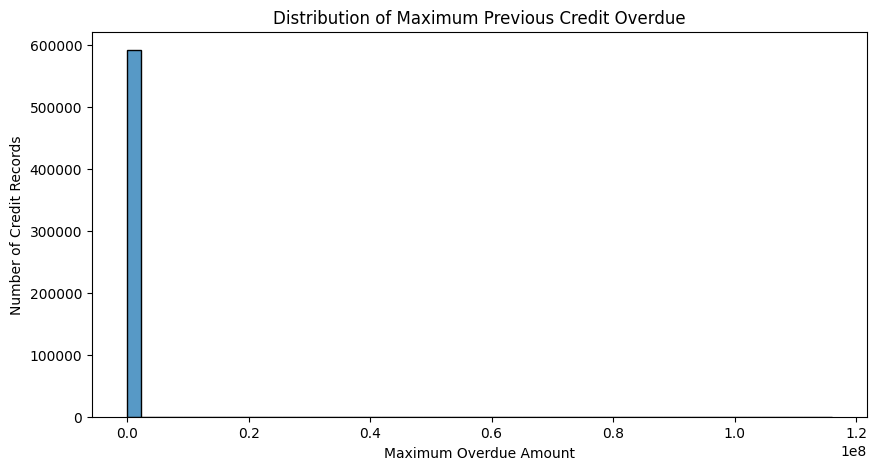

In [ ]:

plt.figure(figsize=(10, 5))

sns.histplot(
    bureau["AMT_CREDIT_MAX_OVERDUE"].dropna(),
    bins=50
)

plt.title("Distribution of Maximum Previous Credit Overdue")
plt.xlabel("Maximum Overdue Amount")
plt.ylabel("Number of Credit Records")

plt.show()


In [ ]:

# Step 39.1: Maximum overdue status versus current loan default

max_overdue_data = bureau_target.copy()

max_overdue_data["MAX_OVERDUE_STATUS"] = np.select(
    [
        max_overdue_data["AMT_CREDIT_MAX_OVERDUE"].isna(),
        max_overdue_data["AMT_CREDIT_MAX_OVERDUE"] == 0,
        max_overdue_data["AMT_CREDIT_MAX_OVERDUE"] > 0
    ],
    [
        "Missing",
        "Zero",
        "Positive"
    ],
    default="Other"
)

max_overdue_analysis = (
    max_overdue_data.groupby("MAX_OVERDUE_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

max_overdue_analysis["Default_Rate"] = (
    max_overdue_analysis["Default_Rate"] * 100
).round(2)

display(max_overdue_analysis)


,MAX_OVERDUE_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Missing,948545,73236.0,7.72
1,Positive,107137,10450.0,9.75
2,Zero,409643,30834.0,7.53


In [ ]:
bureau["AMT_CREDIT_SUM_OVERDUE"].describe()

,AMT_CREDIT_SUM_OVERDUE
count,1.716428e+06
mean,3.791276e+01
std,5.937650e+03
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,3.756681e+06


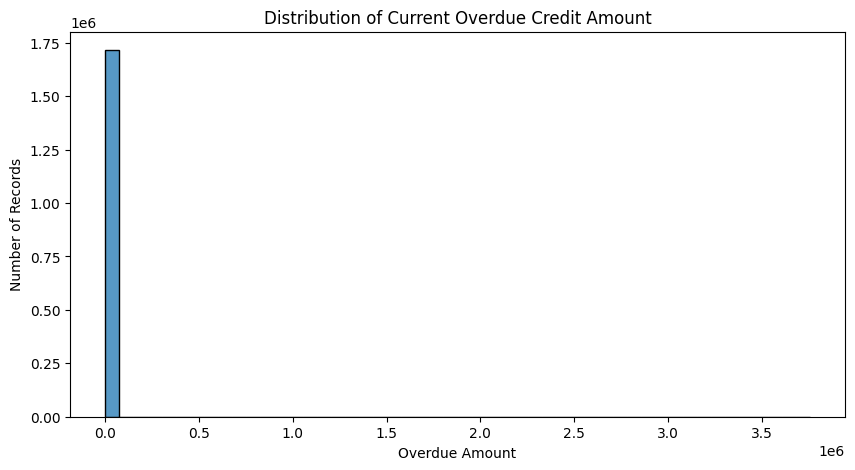

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    bureau["AMT_CREDIT_SUM_OVERDUE"],
    bins=50
)

plt.title("Distribution of Current Overdue Credit Amount")
plt.xlabel("Overdue Amount")
plt.ylabel("Number of Records")

plt.show()


In [ ]:
overdue_distribution = pd.DataFrame({
    "Status": ["Zero Overdue", "Positive Overdue"],
    "Records": [
        (bureau["AMT_CREDIT_SUM_OVERDUE"] == 0).sum(),
        (bureau["AMT_CREDIT_SUM_OVERDUE"] > 0).sum()
    ]
})

overdue_distribution["Percentage"] = (
    overdue_distribution["Records"] / len(bureau) * 100
).round(2)

display(overdue_distribution)

,Status,Records,Percentage
0,Zero Overdue,1712270,99.76
1,Positive Overdue,4158,0.24


In [ ]:
overdue_data = bureau_target.copy()

overdue_data["OVERDUE_STATUS"] = np.where(
    overdue_data["AMT_CREDIT_SUM_OVERDUE"] > 0,
    "Positive Overdue",
    "Zero Overdue"
)

overdue_analysis = (
    overdue_data.groupby("OVERDUE_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

overdue_analysis["Default_Rate"] = (
    overdue_analysis["Default_Rate"] * 100
).round(2)

display(overdue_analysis)

,OVERDUE_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Positive Overdue,3644,681.0,18.69
1,Zero Overdue,1461681,113839.0,7.79


In [ ]:
bureau["DAYS_CREDIT_ENDDATE"].describe()


,DAYS_CREDIT_ENDDATE
count,1.610875e+06
mean,5.105174e+02
std,4.994220e+03
min,-4.206000e+04
25%,-1.138000e+03
50%,-3.300000e+02
75%,4.740000e+02
max,3.119900e+04


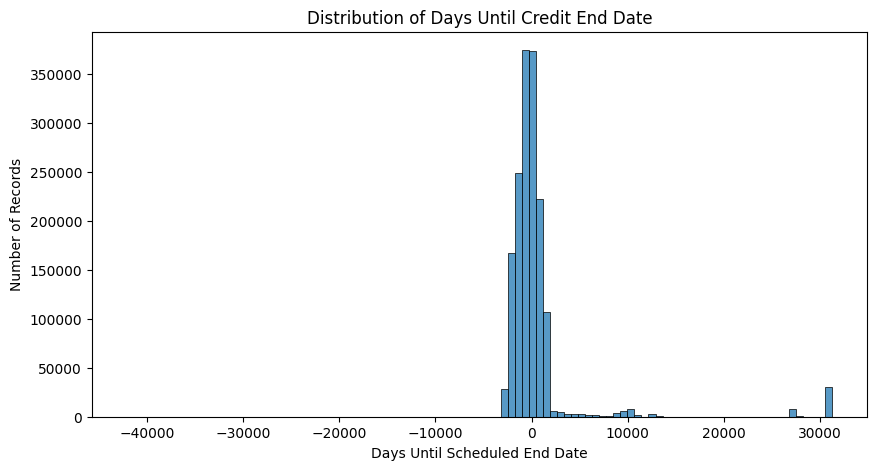

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    bureau["DAYS_CREDIT_ENDDATE"].dropna(),
    bins=100
)

plt.title("Distribution of Days Until Credit End Date")
plt.xlabel("Days Until Scheduled End Date")
plt.ylabel("Number of Records")

plt.show()

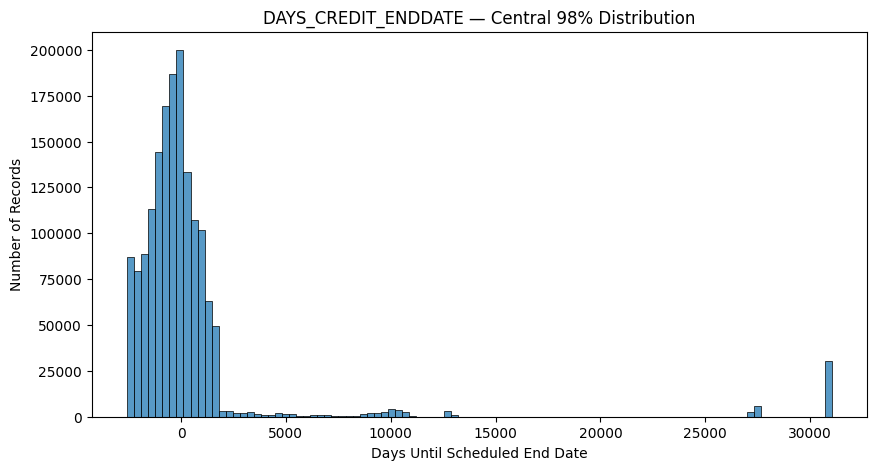

1st percentile: -2571.0
99th percentile: 31029.0


In [ ]:
lower = bureau["DAYS_CREDIT_ENDDATE"].quantile(0.01)
upper = bureau["DAYS_CREDIT_ENDDATE"].quantile(0.99)

plt.figure(figsize=(10, 5))

sns.histplot(
    bureau["DAYS_CREDIT_ENDDATE"].dropna().clip(lower, upper),
    bins=100
)

plt.title("DAYS_CREDIT_ENDDATE — Central 98% Distribution")
plt.xlabel("Days Until Scheduled End Date")
plt.ylabel("Number of Records")

plt.show()

print("1st percentile:", lower)
print("99th percentile:", upper)

In [ ]:
enddate_data = bureau_target.copy()

enddate_data["ENDDATE_STATUS"] = np.select(
    [
        enddate_data["DAYS_CREDIT_ENDDATE"].isna(),
        enddate_data["DAYS_CREDIT_ENDDATE"] < 0,
        enddate_data["DAYS_CREDIT_ENDDATE"] == 0,
        enddate_data["DAYS_CREDIT_ENDDATE"] > 0
    ],
    ["Missing", "Past", "Today", "Future"],
    default="Other"
)

enddate_analysis = (
    enddate_data.groupby("ENDDATE_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

enddate_analysis["Default_Rate"] = (
    enddate_analysis["Default_Rate"] * 100
).round(2)

display(enddate_analysis)

,ENDDATE_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Future,513371,46490.0,9.06
1,Missing,89098,9308.0,10.45
2,Past,862110,58628.0,6.80
3,Today,746,94.0,12.60


In [ ]:
bureau["DAYS_ENDDATE_FACT"].describe()

,DAYS_ENDDATE_FACT
count,1.082775e+06
mean,-1.017437e+03
std,7.140106e+02
min,-4.202300e+04
25%,-1.489000e+03
50%,-8.970000e+02
75%,-4.250000e+02
max,0.000000e+00


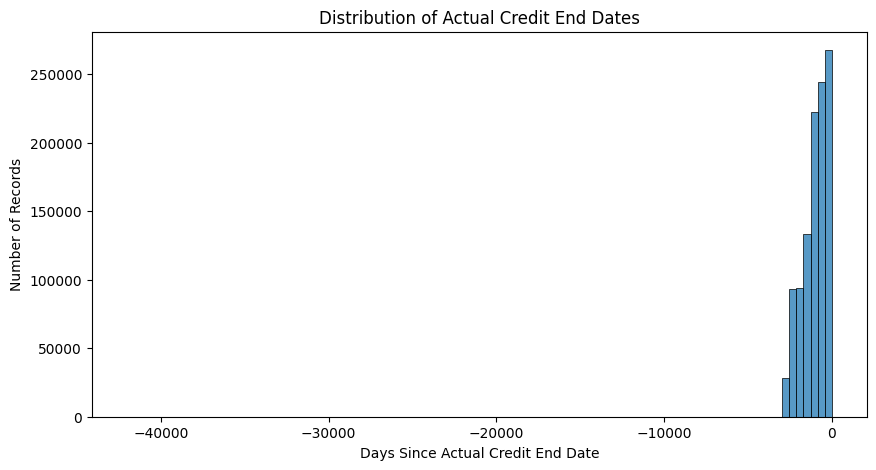

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    bureau["DAYS_ENDDATE_FACT"].dropna(),
    bins=100
)

plt.title("Distribution of Actual Credit End Dates")
plt.xlabel("Days Since Actual Credit End Date")
plt.ylabel("Number of Records")

plt.show()

In [ ]:
fact_data = bureau_target.copy()

fact_data["FACT_ENDDATE_STATUS"] = np.where(
    fact_data["DAYS_ENDDATE_FACT"].isna(),
    "Missing",
    "Recorded"
)

fact_analysis = (
    fact_data.groupby("FACT_ENDDATE_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

fact_analysis["Default_Rate"] = (
    fact_analysis["Default_Rate"] * 100
).round(2)

display(fact_analysis)

,FACT_ENDDATE_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Missing,544673,50624.0,9.29
1,Recorded,920652,63896.0,6.94


In [ ]:
bureau["DAYS_CREDIT_UPDATE"].describe()

,DAYS_CREDIT_UPDATE
count,1.716428e+06
mean,-5.937483e+02
std,7.207473e+02
min,-4.194700e+04
25%,-9.080000e+02
50%,-3.950000e+02
75%,-3.300000e+01
max,3.720000e+02


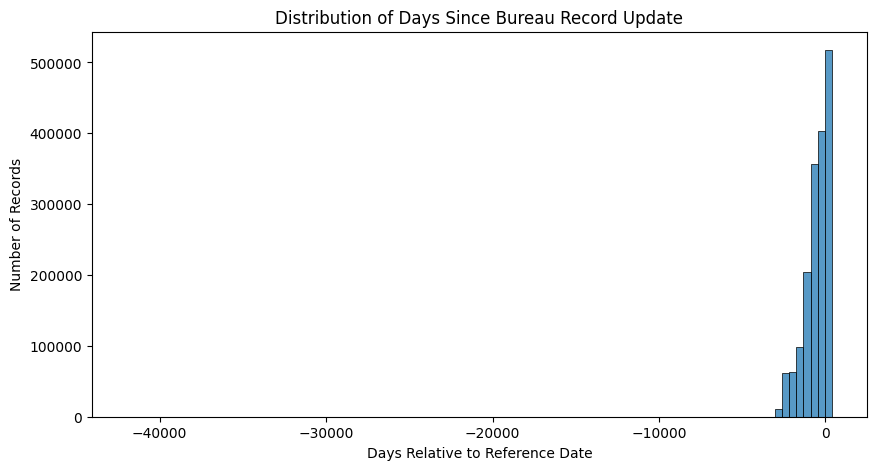

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    bureau["DAYS_CREDIT_UPDATE"],
    bins=100
)

plt.title("Distribution of Days Since Bureau Record Update")
plt.xlabel("Days Relative to Reference Date")
plt.ylabel("Number of Records")

plt.show()

In [ ]:
update_data = bureau_target.copy()

update_data["UPDATE_STATUS"] = np.select(
    [
        update_data["DAYS_CREDIT_UPDATE"] > 0,
        update_data["DAYS_CREDIT_UPDATE"] >= -30,
        update_data["DAYS_CREDIT_UPDATE"] >= -365
    ],
    [
        "Future Dated",
        "Recent",
        "Within 1 Year"
    ],
    default="Older"
)

update_analysis = (
    update_data.groupby("UPDATE_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

update_analysis["Default_Rate"] = (
    update_analysis["Default_Rate"] * 100
).round(2)

display(update_analysis)


,UPDATE_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Future Dated,17,2.0,11.76
1,Older,759519,50076.0,6.59
2,Recent,345011,34280.0,9.94
3,Within 1 Year,360778,30162.0,8.36


In [ ]:
bureau["CREDIT_CURRENCY"].value_counts(dropna=False)

,count
CREDIT_CURRENCY,
currency 1,1715020
currency 2,1224
currency 3,174
currency 4,10


In [ ]:
bureau["AMT_ANNUITY"].describe()

,AMT_ANNUITY
count,4.896370e+05
mean,1.571276e+04
std,3.258269e+05
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,1.350000e+04
max,1.184534e+08


In [ ]:
annuity_summary = pd.DataFrame({
    "Status": ["Missing", "Zero", "Positive"],
    "Records": [
        bureau["AMT_ANNUITY"].isna().sum(),
        (bureau["AMT_ANNUITY"] == 0).sum(),
        (bureau["AMT_ANNUITY"] > 0).sum()
    ]
})

annuity_summary["Percentage"] = (
    annuity_summary["Records"] / len(bureau) * 100
).round(2)

display(annuity_summary)

,Status,Records,Percentage
0,Missing,1226791,71.47
1,Zero,256915,14.97
2,Positive,232722,13.56


In [ ]:
annuity_data = bureau_target.copy()

annuity_data["ANNUITY_STATUS"] = np.select(
    [
        annuity_data["AMT_ANNUITY"].isna(),
        annuity_data["AMT_ANNUITY"] == 0,
        annuity_data["AMT_ANNUITY"] > 0
    ],
    ["Missing", "Zero", "Positive"],
    default="Other"
)

annuity_analysis = (
    annuity_data.groupby("ANNUITY_STATUS")
    .agg(
        Total_Records=("TARGET", "count"),
        Defaulter_Records=("TARGET", "sum"),
        Default_Rate=("TARGET", "mean")
    )
    .reset_index()
)

annuity_analysis["Default_Rate"] = (
    annuity_analysis["Default_Rate"] * 100
).round(2)

display(annuity_analysis)

,ANNUITY_STATUS,Total_Records,Defaulter_Records,Default_Rate
0,Missing,1130013,85670.0,7.58
1,Positive,168026,16109.0,9.59
2,Zero,167286,12741.0,7.62


In [ ]:
print("Total bureau records:", len(bureau))

print(
    "Unique applicants in bureau:",
    bureau["SK_ID_CURR"].nunique()
)

print(
    "Unique credit accounts:",
    bureau["SK_ID_BUREAU"].nunique()
)

print(
    "Applicants in main dataset:",
    df["SK_ID_CURR"].nunique()
)

Total bureau records: 1716428
Unique applicants in bureau: 305811
Unique credit accounts: 1716428
Applicants in main dataset: 307511


In [ ]:
bureau_account_count = (
    bureau.groupby("SK_ID_CURR")
    .size()
    .reset_index(name="BUREAU_TOTAL_ACCOUNTS")
)

print("Average accounts:", bureau_account_count["BUREAU_TOTAL_ACCOUNTS"].mean())
print("Median accounts:", bureau_account_count["BUREAU_TOTAL_ACCOUNTS"].median())
print("Minimum accounts:", bureau_account_count["BUREAU_TOTAL_ACCOUNTS"].min())
print("Maximum accounts:", bureau_account_count["BUREAU_TOTAL_ACCOUNTS"].max())

display(
    bureau_account_count["BUREAU_TOTAL_ACCOUNTS"].describe()
)

Average accounts: 5.612708502964249
Median accounts: 4.0
Minimum accounts: 1
Maximum accounts: 116


,BUREAU_TOTAL_ACCOUNTS
count,305811.000000
mean,5.612709
std,4.430354
min,1.000000
25%,2.000000
50%,4.000000
75%,8.000000
max,116.000000


In [ ]:
bureau_features = (
    bureau.groupby("SK_ID_CURR")
    .size()
    .reset_index(name="BUREAU_TOTAL_ACCOUNTS")
)

print("Feature table shape:", bureau_features.shape)

display(bureau_features.head())

Feature table shape: (305811, 2)


,SK_ID_CURR,BUREAU_TOTAL_ACCOUNTS
0,100001,7
1,100002,8
2,100003,4
3,100004,2
4,100005,3


In [ ]:
bureau_status_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_ACTIVE_ACCOUNTS=(
            "CREDIT_ACTIVE",
            lambda x: (x == "Active").sum()
        ),
        BUREAU_CLOSED_ACCOUNTS=(
            "CREDIT_ACTIVE",
            lambda x: (x == "Closed").sum()
        ),
        BUREAU_SOLD_ACCOUNTS=(
            "CREDIT_ACTIVE",
            lambda x: (x == "Sold").sum()
        )
    )
    .reset_index()
)

display(bureau_status_features.head())


,SK_ID_CURR,BUREAU_ACTIVE_ACCOUNTS,BUREAU_CLOSED_ACCOUNTS,BUREAU_SOLD_ACCOUNTS
0,100001,3,4,0
1,100002,2,6,0
2,100003,1,3,0
3,100004,0,2,0
4,100005,2,1,0


In [ ]:
bureau_status_features = (
    pd.crosstab(
        bureau["SK_ID_CURR"],
        bureau["CREDIT_ACTIVE"]
    )
    .reindex(columns=["Active", "Closed", "Sold"], fill_value=0)
    .rename(columns={
        "Active": "BUREAU_ACTIVE_ACCOUNTS",
        "Closed": "BUREAU_CLOSED_ACCOUNTS",
        "Sold": "BUREAU_SOLD_ACCOUNTS"
    })
    .reset_index()
)

display(bureau_status_features.head())

CREDIT_ACTIVE,SK_ID_CURR,BUREAU_ACTIVE_ACCOUNTS,BUREAU_CLOSED_ACCOUNTS,BUREAU_SOLD_ACCOUNTS
0,100001,3,4,0
1,100002,2,6,0
2,100003,1,3,0
3,100004,0,2,0
4,100005,2,1,0


In [ ]:
bureau_features = bureau_features.merge(
    bureau_status_features,
    on="SK_ID_CURR",
    how="left"
)

print("Shape:", bureau_features.shape)

display(bureau_features.head())


Shape: (305811, 5)


,SK_ID_CURR,BUREAU_TOTAL_ACCOUNTS,BUREAU_ACTIVE_ACCOUNTS,BUREAU_CLOSED_ACCOUNTS,BUREAU_SOLD_ACCOUNTS
0,100001,7,3,4,0
1,100002,8,2,6,0
2,100003,4,1,3,0
3,100004,2,0,2,0
4,100005,3,2,1,0


In [ ]:
bureau_status_features = (
    pd.crosstab(
        bureau["SK_ID_CURR"],
        bureau["CREDIT_ACTIVE"]
    )
    .reindex(
        columns=["Active", "Closed", "Sold", "Bad debt"],
        fill_value=0
    )
    .rename(columns={
        "Active": "BUREAU_ACTIVE_ACCOUNTS",
        "Closed": "BUREAU_CLOSED_ACCOUNTS",
        "Sold": "BUREAU_SOLD_ACCOUNTS",
        "Bad debt": "BUREAU_BAD_DEBT_ACCOUNTS"
    })
    .reset_index()
)

# Rebuild the complete feature table
bureau_features = (
    bureau.groupby("SK_ID_CURR")
    .size()
    .reset_index(name="BUREAU_TOTAL_ACCOUNTS")
    .merge(
        bureau_status_features,
        on="SK_ID_CURR",
        how="left"
    )
)

display(bureau_features.head())

,SK_ID_CURR,BUREAU_TOTAL_ACCOUNTS,BUREAU_ACTIVE_ACCOUNTS,BUREAU_CLOSED_ACCOUNTS,BUREAU_SOLD_ACCOUNTS,BUREAU_BAD_DEBT_ACCOUNTS
0,100001,7,3,4,0,0
1,100002,8,2,6,0,0
2,100003,4,1,3,0,0
3,100004,2,0,2,0,0
4,100005,3,2,1,0,0


In [ ]:
print(
    "Applicants where status counts don't match total:",
    (
        bureau_features[
            [
                "BUREAU_ACTIVE_ACCOUNTS",
                "BUREAU_CLOSED_ACCOUNTS",
                "BUREAU_SOLD_ACCOUNTS",
                "BUREAU_BAD_DEBT_ACCOUNTS"
            ]
        ].sum(axis=1)
        != bureau_features["BUREAU_TOTAL_ACCOUNTS"]
    ).sum()
)

Applicants where status counts don't match total: 0


In [ ]:
bureau_financial_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_TOTAL_DEBT=("AMT_CREDIT_SUM_DEBT", "sum"),
        BUREAU_AVG_DEBT=("AMT_CREDIT_SUM_DEBT", "mean"),
        BUREAU_MAX_DEBT=("AMT_CREDIT_SUM_DEBT", "max")
    )
    .reset_index()
)

display(bureau_financial_features.head())

,SK_ID_CURR,BUREAU_TOTAL_DEBT,BUREAU_AVG_DEBT,BUREAU_MAX_DEBT
0,100001,596686.5,85240.928571,373239.0
1,100002,245781.0,49156.200000,245781.0
2,100003,0.0,0.000000,0.0
3,100004,0.0,0.000000,0.0
4,100005,568408.5,189469.500000,543087.0


In [ ]:
debt_missing_check = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        TOTAL_ACCOUNTS=("SK_ID_BUREAU", "count"),
        DEBT_NON_MISSING=("AMT_CREDIT_SUM_DEBT", "count"),
        DEBT_MISSING=("AMT_CREDIT_SUM_DEBT", lambda x: x.isna().sum())
    )
    .reset_index()
)

debt_missing_check["ALL_DEBT_MISSING"] = (
    debt_missing_check["DEBT_NON_MISSING"] == 0
)

display(
    debt_missing_check[
        debt_missing_check["ALL_DEBT_MISSING"]
    ].head(10)
)

print(
    "Applicants with all debt values missing:",
    debt_missing_check["ALL_DEBT_MISSING"].sum()
)

,SK_ID_CURR,TOTAL_ACCOUNTS,DEBT_NON_MISSING,DEBT_MISSING,ALL_DEBT_MISSING
71,100084,1,0,1,True
82,100096,1,0,1,True
90,100106,1,0,1,True
135,100158,1,0,1,True
153,100176,1,0,1,True
175,100200,1,0,1,True
203,100231,1,0,1,True
223,100252,2,0,2,True
243,100274,1,0,1,True
280,100318,1,0,1,True


Applicants with all debt values missing: 8372


In [ ]:
BUREAU_TOTAL_DEBT=("AMT_CREDIT_SUM_DEBT", "sum")

In [ ]:
bureau_financial_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_TOTAL_DEBT=(
            "AMT_CREDIT_SUM_DEBT",
            lambda x: x.sum(min_count=1)
        ),
        BUREAU_AVG_DEBT=(
            "AMT_CREDIT_SUM_DEBT",
            "mean"
        ),
        BUREAU_MAX_DEBT=(
            "AMT_CREDIT_SUM_DEBT",
            "max"
        ),
        BUREAU_DEBT_MISSING_COUNT=(
            "AMT_CREDIT_SUM_DEBT",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

print(
    "Applicants with missing total debt:",
    bureau_financial_features["BUREAU_TOTAL_DEBT"].isna().sum()
)

display(bureau_financial_features.head())

Applicants with missing total debt: 8372


,SK_ID_CURR,BUREAU_TOTAL_DEBT,BUREAU_AVG_DEBT,BUREAU_MAX_DEBT,BUREAU_DEBT_MISSING_COUNT
0,100001,596686.5,85240.928571,373239.0,0
1,100002,245781.0,49156.200000,245781.0,3
2,100003,0.0,0.000000,0.0,0
3,100004,0.0,0.000000,0.0,0
4,100005,568408.5,189469.500000,543087.0,0


In [ ]:
bureau_features = bureau_features.merge(
    bureau_financial_features,
    on="SK_ID_CURR",
    how="left"
)

print("Feature table shape:", bureau_features.shape)

display(bureau_features.head())

Feature table shape: (305811, 10)


,SK_ID_CURR,BUREAU_TOTAL_ACCOUNTS,BUREAU_ACTIVE_ACCOUNTS,BUREAU_CLOSED_ACCOUNTS,BUREAU_SOLD_ACCOUNTS,BUREAU_BAD_DEBT_ACCOUNTS,BUREAU_TOTAL_DEBT,BUREAU_AVG_DEBT,BUREAU_MAX_DEBT,BUREAU_DEBT_MISSING_COUNT
0,100001,7,3,4,0,0,596686.5,85240.928571,373239.0,0
1,100002,8,2,6,0,0,245781.0,49156.200000,245781.0,3
2,100003,4,1,3,0,0,0.0,0.000000,0.0,0
3,100004,2,0,2,0,0,0.0,0.000000,0.0,0
4,100005,3,2,1,0,0,568408.5,189469.500000,543087.0,0


In [ ]:
bureau_overdue_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_TOTAL_OVERDUE_DAYS=(
            "CREDIT_DAY_OVERDUE", "sum"
        ),
        BUREAU_MAX_OVERDUE_DAYS=(
            "CREDIT_DAY_OVERDUE", "max"
        ),
        BUREAU_TOTAL_OVERDUE_AMOUNT=(
            "AMT_CREDIT_SUM_OVERDUE",
            lambda x: x.sum(min_count=1)
        ),
        BUREAU_MAX_OVERDUE_AMOUNT=(
            "AMT_CREDIT_SUM_OVERDUE", "max"
        )
    )
    .reset_index()
)

display(bureau_overdue_features.head())


,SK_ID_CURR,BUREAU_TOTAL_OVERDUE_DAYS,BUREAU_MAX_OVERDUE_DAYS,BUREAU_TOTAL_OVERDUE_AMOUNT,BUREAU_MAX_OVERDUE_AMOUNT
0,100001,0,0,0.0,0.0
1,100002,0,0,0.0,0.0
2,100003,0,0,0.0,0.0
3,100004,0,0,0.0,0.0
4,100005,0,0,0.0,0.0


In [ ]:
print(
    "Applicants with positive overdue days:",
    (bureau_overdue_features["BUREAU_TOTAL_OVERDUE_DAYS"] > 0).sum()
)

print(
    "Applicants with positive overdue amount:",
    (bureau_overdue_features["BUREAU_TOTAL_OVERDUE_AMOUNT"] > 0).sum()
)

print(
    "Applicants with missing total overdue amount:",
    bureau_overdue_features["BUREAU_TOTAL_OVERDUE_AMOUNT"].isna().sum()
)

print(
    "Maximum overdue days:",
    bureau_overdue_features["BUREAU_MAX_OVERDUE_DAYS"].max()
)

print(
    "Maximum overdue amount:",
    bureau_overdue_features["BUREAU_MAX_OVERDUE_AMOUNT"].max()
)


Applicants with positive overdue days: 3864
Applicants with positive overdue amount: 3801
Applicants with missing total overdue amount: 0
Maximum overdue days: 2792
Maximum overdue amount: 3756681.0


In [ ]:
bureau_features = bureau_features.merge(
    bureau_overdue_features,
    on="SK_ID_CURR",
    how="left"
)

print("Feature table shape:", bureau_features.shape)

display(bureau_features.head())

Feature table shape: (305811, 14)


,SK_ID_CURR,BUREAU_TOTAL_ACCOUNTS,BUREAU_ACTIVE_ACCOUNTS,BUREAU_CLOSED_ACCOUNTS,BUREAU_SOLD_ACCOUNTS,BUREAU_BAD_DEBT_ACCOUNTS,BUREAU_TOTAL_DEBT,BUREAU_AVG_DEBT,BUREAU_MAX_DEBT,BUREAU_DEBT_MISSING_COUNT,BUREAU_TOTAL_OVERDUE_DAYS,BUREAU_MAX_OVERDUE_DAYS,BUREAU_TOTAL_OVERDUE_AMOUNT,BUREAU_MAX_OVERDUE_AMOUNT
0,100001,7,3,4,0,0,596686.5,85240.928571,373239.0,0,0,0,0.0,0.0
1,100002,8,2,6,0,0,245781.0,49156.200000,245781.0,3,0,0,0.0,0.0
2,100003,4,1,3,0,0,0.0,0.000000,0.0,0,0,0,0.0,0.0
3,100004,2,0,2,0,0,0.0,0.000000,0.0,0,0,0,0.0,0.0
4,100005,3,2,1,0,0,568408.5,189469.500000,543087.0,0,0,0,0.0,0.0


In [ ]:
bureau_timing_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_AVG_DAYS_CREDIT=("DAYS_CREDIT", "mean"),
        BUREAU_MIN_DAYS_CREDIT=("DAYS_CREDIT", "min"),
        BUREAU_MAX_DAYS_CREDIT=("DAYS_CREDIT", "max")
    )
    .reset_index()
)

display(bureau_timing_features.head())

,SK_ID_CURR,BUREAU_AVG_DAYS_CREDIT,BUREAU_MIN_DAYS_CREDIT,BUREAU_MAX_DAYS_CREDIT
0,100001,-735.000000,-1572,-49
1,100002,-874.000000,-1437,-103
2,100003,-1400.750000,-2586,-606
3,100004,-867.000000,-1326,-408
4,100005,-190.666667,-373,-62


In [ ]:
bureau_enddate_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_AVG_DAYS_CREDIT_ENDDATE=(
            "DAYS_CREDIT_ENDDATE", "mean"
        ),
        BUREAU_MIN_DAYS_CREDIT_ENDDATE=(
            "DAYS_CREDIT_ENDDATE", "min"
        ),
        BUREAU_MAX_DAYS_CREDIT_ENDDATE=(
            "DAYS_CREDIT_ENDDATE", "max"
        )
    )
    .reset_index()
)

display(bureau_enddate_features.head())

,SK_ID_CURR,BUREAU_AVG_DAYS_CREDIT_ENDDATE,BUREAU_MIN_DAYS_CREDIT_ENDDATE,BUREAU_MAX_DAYS_CREDIT_ENDDATE
0,100001,82.428571,-1329.0,1778.0
1,100002,-349.000000,-1072.0,780.0
2,100003,-544.500000,-2434.0,1216.0
3,100004,-488.500000,-595.0,-382.0
4,100005,439.333333,-128.0,1324.0


In [ ]:
bureau_actual_enddate_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_AVG_DAYS_ENDDATE_FACT=(
            "DAYS_ENDDATE_FACT", "mean"
        ),
        BUREAU_MIN_DAYS_ENDDATE_FACT=(
            "DAYS_ENDDATE_FACT", "min"
        ),
        BUREAU_MAX_DAYS_ENDDATE_FACT=(
            "DAYS_ENDDATE_FACT", "max"
        )
    )
    .reset_index()
)

display(bureau_actual_enddate_features.head())

,SK_ID_CURR,BUREAU_AVG_DAYS_ENDDATE_FACT,BUREAU_MIN_DAYS_ENDDATE_FACT,BUREAU_MAX_DAYS_ENDDATE_FACT
0,100001,-825.500000,-1328.0,-544.0
1,100002,-697.500000,-1185.0,-36.0
2,100003,-1097.333333,-2131.0,-540.0
3,100004,-532.500000,-683.0,-382.0
4,100005,-123.000000,-123.0,-123.0


In [ ]:
bureau_timing_features = bureau_timing_features.merge(
    bureau_enddate_features,
    on="SK_ID_CURR",
    how="left"
)

bureau_timing_features = bureau_timing_features.merge(
    bureau_actual_enddate_features,
    on="SK_ID_CURR",
    how="left"
)

print("Timing feature table shape:", bureau_timing_features.shape)

display(bureau_timing_features.head())

Timing feature table shape: (305811, 10)


,SK_ID_CURR,BUREAU_AVG_DAYS_CREDIT,BUREAU_MIN_DAYS_CREDIT,BUREAU_MAX_DAYS_CREDIT,BUREAU_AVG_DAYS_CREDIT_ENDDATE,BUREAU_MIN_DAYS_CREDIT_ENDDATE,BUREAU_MAX_DAYS_CREDIT_ENDDATE,BUREAU_AVG_DAYS_ENDDATE_FACT,BUREAU_MIN_DAYS_ENDDATE_FACT,BUREAU_MAX_DAYS_ENDDATE_FACT
0,100001,-735.000000,-1572,-49,82.428571,-1329.0,1778.0,-825.500000,-1328.0,-544.0
1,100002,-874.000000,-1437,-103,-349.000000,-1072.0,780.0,-697.500000,-1185.0,-36.0
2,100003,-1400.750000,-2586,-606,-544.500000,-2434.0,1216.0,-1097.333333,-2131.0,-540.0
3,100004,-867.000000,-1326,-408,-488.500000,-595.0,-382.0,-532.500000,-683.0,-382.0
4,100005,-190.666667,-373,-62,439.333333,-128.0,1324.0,-123.000000,-123.0,-123.0


In [ ]:
bureau_update_features = (
    bureau.groupby("SK_ID_CURR")
    .agg(
        BUREAU_AVG_DAYS_CREDIT_UPDATE=("DAYS_CREDIT_UPDATE", "mean"),
        BUREAU_MIN_DAYS_CREDIT_UPDATE=("DAYS_CREDIT_UPDATE", "min"),
        BUREAU_MAX_DAYS_CREDIT_UPDATE=("DAYS_CREDIT_UPDATE", "max")
    )
    .reset_index()
)

print("Update feature table shape:", bureau_update_features.shape)
display(bureau_update_features.head())

Update feature table shape: (305811, 4)


,SK_ID_CURR,BUREAU_AVG_DAYS_CREDIT_UPDATE,BUREAU_MIN_DAYS_CREDIT_UPDATE,BUREAU_MAX_DAYS_CREDIT_UPDATE
0,100001,-93.142857,-155,-6
1,100002,-499.875000,-1185,-7
2,100003,-816.000000,-2131,-43
3,100004,-532.000000,-682,-382
4,100005,-54.333333,-121,-11


In [ ]:
bureau_timing_features = bureau_timing_features.merge(
    bureau_update_features,
    on="SK_ID_CURR",
    how="left"
)

print("Combined timing feature shape:", bureau_timing_features.shape)
display(bureau_timing_features.head())

Combined timing feature shape: (305811, 13)


,SK_ID_CURR,BUREAU_AVG_DAYS_CREDIT,BUREAU_MIN_DAYS_CREDIT,BUREAU_MAX_DAYS_CREDIT,BUREAU_AVG_DAYS_CREDIT_ENDDATE,BUREAU_MIN_DAYS_CREDIT_ENDDATE,BUREAU_MAX_DAYS_CREDIT_ENDDATE,BUREAU_AVG_DAYS_ENDDATE_FACT,BUREAU_MIN_DAYS_ENDDATE_FACT,BUREAU_MAX_DAYS_ENDDATE_FACT,BUREAU_AVG_DAYS_CREDIT_UPDATE,BUREAU_MIN_DAYS_CREDIT_UPDATE,BUREAU_MAX_DAYS_CREDIT_UPDATE
0,100001,-735.000000,-1572,-49,82.428571,-1329.0,1778.0,-825.500000,-1328.0,-544.0,-93.142857,-155,-6
1,100002,-874.000000,-1437,-103,-349.000000,-1072.0,780.0,-697.500000,-1185.0,-36.0,-499.875000,-1185,-7
2,100003,-1400.750000,-2586,-606,-544.500000,-2434.0,1216.0,-1097.333333,-2131.0,-540.0,-816.000000,-2131,-43
3,100004,-867.000000,-1326,-408,-488.500000,-595.0,-382.0,-532.500000,-683.0,-382.0,-532.000000,-682,-382
4,100005,-190.666667,-373,-62,439.333333,-128.0,1324.0,-123.000000,-123.0,-123.0,-54.333333,-121,-11


In [ ]:
bureau_features = bureau_features.merge(
    bureau_timing_features,
    on="SK_ID_CURR",
    how="left"
)

print("Bureau feature table shape:", bureau_features.shape)
print("Unique applicants:", bureau_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", bureau_features["SK_ID_CURR"].duplicated().sum())

display(bureau_features.head())

Bureau feature table shape: (305811, 26)
Unique applicants: 305811
Duplicate applicant IDs: 0


,SK_ID_CURR,BUREAU_TOTAL_ACCOUNTS,BUREAU_ACTIVE_ACCOUNTS,BUREAU_CLOSED_ACCOUNTS,BUREAU_SOLD_ACCOUNTS,BUREAU_BAD_DEBT_ACCOUNTS,BUREAU_TOTAL_DEBT,BUREAU_AVG_DEBT,BUREAU_MAX_DEBT,BUREAU_DEBT_MISSING_COUNT,...,BUREAU_MAX_DAYS_CREDIT,BUREAU_AVG_DAYS_CREDIT_ENDDATE,BUREAU_MIN_DAYS_CREDIT_ENDDATE,BUREAU_MAX_DAYS_CREDIT_ENDDATE,BUREAU_AVG_DAYS_ENDDATE_FACT,BUREAU_MIN_DAYS_ENDDATE_FACT,BUREAU_MAX_DAYS_ENDDATE_FACT,BUREAU_AVG_DAYS_CREDIT_UPDATE,BUREAU_MIN_DAYS_CREDIT_UPDATE,BUREAU_MAX_DAYS_CREDIT_UPDATE
0,100001,7,3,4,0,0,596686.5,85240.928571,373239.0,0,...,-49,82.428571,-1329.0,1778.0,-825.500000,-1328.0,-544.0,-93.142857,-155,-6
1,100002,8,2,6,0,0,245781.0,49156.200000,245781.0,3,...,-103,-349.000000,-1072.0,780.0,-697.500000,-1185.0,-36.0,-499.875000,-1185,-7
2,100003,4,1,3,0,0,0.0,0.000000,0.0,0,...,-606,-544.500000,-2434.0,1216.0,-1097.333333,-2131.0,-540.0,-816.000000,-2131,-43
3,100004,2,0,2,0,0,0.0,0.000000,0.0,0,...,-408,-488.500000,-595.0,-382.0,-532.500000,-683.0,-382.0,-532.000000,-682,-382
4,100005,3,2,1,0,0,568408.5,189469.500000,543087.0,0,...,-62,439.333333,-128.0,1324.0,-123.000000,-123.0,-123.0,-54.333333,-121,-11


In [ ]:
print("Rows:", bureau_features.shape[0])
print("Columns:", bureau_features.shape[1])
print("Unique applicants:", bureau_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", bureau_features["SK_ID_CURR"].duplicated().sum())
print("Missing applicant IDs:", bureau_features["SK_ID_CURR"].isna().sum())

Rows: 305811
Columns: 26
Unique applicants: 305811
Duplicate applicant IDs: 0
Missing applicant IDs: 0


In [ ]:
bureau_credit_type_features = (
    pd.crosstab(
        bureau["SK_ID_CURR"],
        bureau["CREDIT_TYPE"]
    )
    .add_prefix("BUREAU_TYPE_")
    .reset_index()
)

print("Credit type feature shape:", bureau_credit_type_features.shape)
display(bureau_credit_type_features.head())

Credit type feature shape: (305811, 16)


CREDIT_TYPE,SK_ID_CURR,BUREAU_TYPE_Another type of loan,BUREAU_TYPE_Car loan,BUREAU_TYPE_Cash loan (non-earmarked),BUREAU_TYPE_Consumer credit,BUREAU_TYPE_Credit card,BUREAU_TYPE_Interbank credit,BUREAU_TYPE_Loan for business development,BUREAU_TYPE_Loan for purchase of shares (margin lending),BUREAU_TYPE_Loan for the purchase of equipment,BUREAU_TYPE_Loan for working capital replenishment,BUREAU_TYPE_Microloan,BUREAU_TYPE_Mobile operator loan,BUREAU_TYPE_Mortgage,BUREAU_TYPE_Real estate loan,BUREAU_TYPE_Unknown type of loan
0,100001,0,0,0,7,0,0,0,0,0,0,0,0,0,0,0
1,100002,0,0,0,4,4,0,0,0,0,0,0,0,0,0,0
2,100003,0,0,0,2,2,0,0,0,0,0,0,0,0,0,0
3,100004,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0
4,100005,0,0,0,2,1,0,0,0,0,0,0,0,0,0,0


In [ ]:
credit_type_columns = [
    col for col in bureau_credit_type_features.columns
    if col.startswith("BUREAU_TYPE_")
]

bureau_credit_type_features["TOTAL_BY_CREDIT_TYPE"] = (
    bureau_credit_type_features[credit_type_columns].sum(axis=1)
)

validation = bureau_credit_type_features.merge(
    bureau_features[["SK_ID_CURR", "BUREAU_TOTAL_ACCOUNTS"]],
    on="SK_ID_CURR",
    how="left"
)

print(
    "Applicants with mismatched account counts:",
    (
        validation["TOTAL_BY_CREDIT_TYPE"]
        != validation["BUREAU_TOTAL_ACCOUNTS"]
    ).sum()
)

Applicants with mismatched account counts: 0


In [ ]:
bureau_features = bureau_features.merge(
    bureau_credit_type_features.drop(
        columns=["TOTAL_BY_CREDIT_TYPE"],
        errors="ignore"
    ),
    on="SK_ID_CURR",
    how="left"
)

print("Updated bureau feature shape:", bureau_features.shape)
print("Unique applicants:", bureau_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", bureau_features["SK_ID_CURR"].duplicated().sum())

display(bureau_features.head())

Updated bureau feature shape: (305811, 41)
Unique applicants: 305811
Duplicate applicant IDs: 0


,SK_ID_CURR,BUREAU_TOTAL_ACCOUNTS,BUREAU_ACTIVE_ACCOUNTS,BUREAU_CLOSED_ACCOUNTS,BUREAU_SOLD_ACCOUNTS,BUREAU_BAD_DEBT_ACCOUNTS,BUREAU_TOTAL_DEBT,BUREAU_AVG_DEBT,BUREAU_MAX_DEBT,BUREAU_DEBT_MISSING_COUNT,...,BUREAU_TYPE_Interbank credit,BUREAU_TYPE_Loan for business development,BUREAU_TYPE_Loan for purchase of shares (margin lending),BUREAU_TYPE_Loan for the purchase of equipment,BUREAU_TYPE_Loan for working capital replenishment,BUREAU_TYPE_Microloan,BUREAU_TYPE_Mobile operator loan,BUREAU_TYPE_Mortgage,BUREAU_TYPE_Real estate loan,BUREAU_TYPE_Unknown type of loan
0,100001,7,3,4,0,0,596686.5,85240.928571,373239.0,0,...,0,0,0,0,0,0,0,0,0,0
1,100002,8,2,6,0,0,245781.0,49156.200000,245781.0,3,...,0,0,0,0,0,0,0,0,0,0
2,100003,4,1,3,0,0,0.0,0.000000,0.0,0,...,0,0,0,0,0,0,0,0,0,0
3,100004,2,0,2,0,0,0.0,0.000000,0.0,0,...,0,0,0,0,0,0,0,0,0,0
4,100005,3,2,1,0,0,568408.5,189469.500000,543087.0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
print("Rows:", bureau_features.shape[0])
print("Columns:", bureau_features.shape[1])
print("Unique applicants:", bureau_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", bureau_features["SK_ID_CURR"].duplicated().sum())

print(
    "Missing values in applicant ID:",
    bureau_features["SK_ID_CURR"].isna().sum()
)

Rows: 305811
Columns: 41
Unique applicants: 305811
Duplicate IDs: 0
Missing values in applicant ID: 0


In [ ]:
df = df.merge(
    bureau_features,
    on="SK_ID_CURR",
    how="left"
)

print("Merged dataset shape:", df.shape)
print("Unique applicants:", df["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", df["SK_ID_CURR"].duplicated().sum())

print(
    "Applicants without bureau history:",
    df["BUREAU_TOTAL_ACCOUNTS"].isna().sum()
)

Merged dataset shape: (307511, 166)
Unique applicants: 307511
Duplicate applicant IDs: 0
Applicants without bureau history: 44020


In [ ]:
print("Current df shape:", df.shape)

print("\nBureau-related columns:")
print([col for col in df.columns if "BUREAU" in col])

print("\nNumber of bureau feature columns:")
print(len([col for col in df.columns if "BUREAU" in col]))

print("\nMissing values in bureau total accounts:")
print(df["BUREAU_TOTAL_ACCOUNTS"].isna().sum())

print("\nBureau feature table:")
print("Rows:", bureau_features.shape[0])
print("Unique IDs:", bureau_features["SK_ID_CURR"].nunique())

print("\nApplicants in df not found in bureau_features:")
print(
    (~df["SK_ID_CURR"].isin(bureau_features["SK_ID_CURR"])).sum()
)

Current df shape: (307511, 166)

Bureau-related columns:
['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'BUREAU_TOTAL_ACCOUNTS', 'BUREAU_ACTIVE_ACCOUNTS', 'BUREAU_CLOSED_ACCOUNTS', 'BUREAU_SOLD_ACCOUNTS', 'BUREAU_BAD_DEBT_ACCOUNTS', 'BUREAU_TOTAL_DEBT', 'BUREAU_AVG_DEBT', 'BUREAU_MAX_DEBT', 'BUREAU_DEBT_MISSING_COUNT', 'BUREAU_TOTAL_OVERDUE_DAYS', 'BUREAU_MAX_OVERDUE_DAYS', 'BUREAU_TOTAL_OVERDUE_AMOUNT', 'BUREAU_MAX_OVERDUE_AMOUNT', 'BUREAU_AVG_DAYS_CREDIT', 'BUREAU_MIN_DAYS_CREDIT', 'BUREAU_MAX_DAYS_CREDIT', 'BUREAU_AVG_DAYS_CREDIT_ENDDATE', 'BUREAU_MIN_DAYS_CREDIT_ENDDATE', 'BUREAU_MAX_DAYS_CREDIT_ENDDATE', 'BUREAU_AVG_DAYS_ENDDATE_FACT', 'BUREAU_MIN_DAYS_ENDDATE_FACT', 'BUREAU_MAX_DAYS_ENDDATE_FACT', 'BUREAU_AVG_DAYS_CREDIT_UPDATE', 'BUREAU_MIN_DAYS_CREDIT_UPDATE', 'BUREAU_MAX_DAYS_CREDIT_UPDATE', 'BUREAU_TYPE_Another type of loan', 'BUREAU_TYPE_Car loan

In [ ]:
main_applicants = set(df["SK_ID_CURR"])

bureau_applicants = set(bureau_features["SK_ID_CURR"])

print("Applicants in main dataset:", len(main_applicants))
print("Applicants in bureau dataset:", len(bureau_applicants))

print(
    "Applicants without bureau history:",
    len(main_applicants - bureau_applicants)
)

print(
    "Bureau applicants not in main dataset:",
    len(bureau_applicants - main_applicants)
)

Applicants in main dataset: 307511
Applicants in bureau dataset: 305811
Applicants without bureau history: 44020
Bureau applicants not in main dataset: 42320


In [ ]:
bureau_columns = [
    col for col in bureau_features.columns
    if col != "SK_ID_CURR"
]

bureau_missing = (
    df[bureau_columns]
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

bureau_missing_summary = pd.DataFrame({
    "Missing_Count": bureau_missing,
    "Missing_Percentage": (
        bureau_missing / len(df) * 100
    )
})

display(bureau_missing_summary)

,Missing_Count,Missing_Percentage
BUREAU_MAX_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_AVG_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_MIN_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_AVG_DEBT,51380,16.708345
BUREAU_TOTAL_DEBT,51380,16.708345
BUREAU_MAX_DEBT,51380,16.708345
BUREAU_AVG_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_MIN_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_MAX_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_BAD_DEBT_ACCOUNTS,44020,14.314935


In [ ]:
df["BUREAU_NO_HISTORY"] = (
    df["BUREAU_TOTAL_ACCOUNTS"].isna().astype(int)
)

print(
    df["BUREAU_NO_HISTORY"].value_counts()
)

print(
    df["BUREAU_NO_HISTORY"].value_counts(normalize=True) * 100
)

BUREAU_NO_HISTORY
0    263491
1     44020
Name: count, dtype: int64
BUREAU_NO_HISTORY
0    85.685065
1    14.314935
Name: proportion, dtype: float64


In [ ]:
bureau_count_columns = [
    "BUREAU_TOTAL_ACCOUNTS",
    "BUREAU_ACTIVE_ACCOUNTS",
    "BUREAU_CLOSED_ACCOUNTS",
    "BUREAU_SOLD_ACCOUNTS",
    "BUREAU_BAD_DEBT_ACCOUNTS",
    "BUREAU_DEBT_MISSING_COUNT",
    "BUREAU_TOTAL_OVERDUE_DAYS",
    "BUREAU_MAX_OVERDUE_DAYS"
]

bureau_type_columns = [
    col for col in df.columns
    if col.startswith("BUREAU_TYPE_")
]

bureau_count_columns = bureau_count_columns + bureau_type_columns

df.loc[
    df["BUREAU_NO_HISTORY"] == 1,
    bureau_count_columns
] = 0

print("Remaining missing count features:")
print(df[bureau_count_columns].isna().sum().sum())

print("\nNo-history applicants with non-zero account counts:")
print(
    df.loc[
        df["BUREAU_NO_HISTORY"] == 1,
        "BUREAU_TOTAL_ACCOUNTS"
    ].sum()
)

Remaining missing count features:
0

No-history applicants with non-zero account counts:
0.0


In [ ]:
bureau_financial_columns = [
    "BUREAU_TOTAL_DEBT",
    "BUREAU_AVG_DEBT",
    "BUREAU_MAX_DEBT",
    "BUREAU_TOTAL_OVERDUE_AMOUNT",
    "BUREAU_MAX_OVERDUE_AMOUNT"
]

print("Missing financial values:")
display(df[bureau_financial_columns].isna().sum())

print("\nFinancial feature summary:")
display(df[bureau_financial_columns].describe().T)

Missing financial values:


,0
BUREAU_TOTAL_DEBT,51380
BUREAU_AVG_DEBT,51380
BUREAU_MAX_DEBT,51380
BUREAU_TOTAL_OVERDUE_AMOUNT,44020
BUREAU_MAX_OVERDUE_AMOUNT,44020



Financial feature summary:


,count,mean,std,min,25%,50%,75%,max
BUREAU_TOTAL_DEBT,256131.0,659059.531142,1.653606e+06,-6981558.210,0.0,184500.000,683302.50,3.344983e+08
BUREAU_AVG_DEBT,256131.0,160390.076973,5.266501e+05,-1083614.670,0.0,44208.035,142136.25,4.365000e+07
BUREAU_MAX_DEBT,256131.0,521627.494041,1.343224e+06,-25959.645,0.0,149458.500,495000.00,1.701000e+08
BUREAU_TOTAL_OVERDUE_AMOUNT,263491.0,223.034341,1.649719e+04,0.000,0.0,0.000,0.00,3.756681e+06
BUREAU_MAX_OVERDUE_AMOUNT,263491.0,184.970193,1.438824e+04,0.000,0.0,0.000,0.00,3.756681e+06


In [ ]:
bureau_overdue_amount_columns = [
    "BUREAU_TOTAL_OVERDUE_AMOUNT",
    "BUREAU_MAX_OVERDUE_AMOUNT"
]

df.loc[
    df["BUREAU_NO_HISTORY"] == 1,
    bureau_overdue_amount_columns
] = 0

print("Missing overdue amount values:")
print(
    df[bureau_overdue_amount_columns]
    .isna()
    .sum()
)

print("\nNo-history applicants with overdue amounts:")
print(
    df.loc[
        df["BUREAU_NO_HISTORY"] == 1,
        bureau_overdue_amount_columns
    ].sum()
)


Missing overdue amount values:
BUREAU_TOTAL_OVERDUE_AMOUNT    0
BUREAU_MAX_OVERDUE_AMOUNT      0
dtype: int64

No-history applicants with overdue amounts:
BUREAU_TOTAL_OVERDUE_AMOUNT    0.0
BUREAU_MAX_OVERDUE_AMOUNT      0.0
dtype: float64


In [ ]:
debt_missing_analysis = pd.DataFrame({
    "No_Bureau_History": (
        df["BUREAU_NO_HISTORY"] == 1
    ),
    "Debt_Missing": (
        df["BUREAU_TOTAL_DEBT"].isna()
    )
})

print(pd.crosstab(
    debt_missing_analysis["No_Bureau_History"],
    debt_missing_analysis["Debt_Missing"],
    margins=True
))


Debt_Missing        False   True     All
No_Bureau_History                       
False              256131   7360  263491
True                    0  44020   44020
All                256131  51380  307511


In [ ]:
df["BUREAU_DEBT_INFO_MISSING"] = (
    (
        df["BUREAU_NO_HISTORY"] == 0
    ) &
    (
        df["BUREAU_TOTAL_DEBT"].isna()
    )
).astype(int)

print(df["BUREAU_DEBT_INFO_MISSING"].value_counts())

print("\nCross-check:")
print(pd.crosstab(
    df["BUREAU_NO_HISTORY"],
    df["BUREAU_DEBT_INFO_MISSING"]
))

BUREAU_DEBT_INFO_MISSING
0    300151
1      7360
Name: count, dtype: int64

Cross-check:
BUREAU_DEBT_INFO_MISSING       0     1
BUREAU_NO_HISTORY                     
0                         256131  7360
1                          44020     0


In [ ]:
bureau_timing_columns = [
    col for col in df.columns
    if col.startswith("BUREAU_")
    and (
        "DAYS_CREDIT" in col
        or "DAYS_ENDDATE_FACT" in col
    )
]

timing_missing = pd.DataFrame({
    "Missing_Count": df[bureau_timing_columns].isna().sum(),
    "Missing_Percentage": (
        df[bureau_timing_columns].isna().mean() * 100
    )
})

display(timing_missing.sort_values(
    "Missing_Count",
    ascending=False
))


,Missing_Count,Missing_Percentage
BUREAU_AVG_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_MAX_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_MIN_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_AVG_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_MIN_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_MAX_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_AVG_DAYS_CREDIT,44020,14.314935
BUREAU_MIN_DAYS_CREDIT,44020,14.314935
BUREAU_MAX_DAYS_CREDIT,44020,14.314935
BUREAU_AVG_DAYS_CREDIT_UPDATE,44020,14.314935


In [ ]:
df["BUREAU_SCHEDULED_ENDDATE_MISSING"] = (
    (
        df["BUREAU_NO_HISTORY"] == 0
    ) &
    (
        df["BUREAU_AVG_DAYS_CREDIT_ENDDATE"].isna()
    )
).astype(int)

df["BUREAU_ACTUAL_ENDDATE_MISSING"] = (
    (
        df["BUREAU_NO_HISTORY"] == 0
    ) &
    (
        df["BUREAU_AVG_DAYS_ENDDATE_FACT"].isna()
    )
).astype(int)

print("Scheduled end-date missingness:")
print(df["BUREAU_SCHEDULED_ENDDATE_MISSING"].value_counts())

print("\nActual end-date missingness:")
print(df["BUREAU_ACTUAL_ENDDATE_MISSING"].value_counts())

Scheduled end-date missingness:
BUREAU_SCHEDULED_ENDDATE_MISSING
0    305262
1      2249
Name: count, dtype: int64

Actual end-date missingness:
BUREAU_ACTUAL_ENDDATE_MISSING
0    274375
1     33136
Name: count, dtype: int64


In [ ]:
bureau_missing_final = pd.DataFrame({
    "Missing_Count": df[bureau_features.columns.drop("SK_ID_CURR")].isna().sum(),
    "Missing_Percentage": (
        df[bureau_features.columns.drop("SK_ID_CURR")].isna().mean() * 100
    )
})

display(
    bureau_missing_final[
        bureau_missing_final["Missing_Count"] > 0
    ].sort_values("Missing_Count", ascending=False)
)

,Missing_Count,Missing_Percentage
BUREAU_MAX_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_AVG_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_MIN_DAYS_ENDDATE_FACT,77156,25.090485
BUREAU_AVG_DEBT,51380,16.708345
BUREAU_TOTAL_DEBT,51380,16.708345
BUREAU_MAX_DEBT,51380,16.708345
BUREAU_AVG_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_MIN_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_MAX_DAYS_CREDIT_ENDDATE,46269,15.046291
BUREAU_AVG_DAYS_CREDIT,44020,14.314935


In [ ]:
bureau_balance = pd.read_csv(
    os.path.join(data_path, "bureau_balance.csv")
)

print("Shape:", bureau_balance.shape)
print("\nColumns:")
print(bureau_balance.columns.tolist())

display(bureau_balance.head())

Shape: (27299925, 3)

Columns:
['SK_ID_BUREAU', 'MONTHS_BALANCE', 'STATUS']


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


In [ ]:
print("Dataset shape:", bureau_balance.shape)

print("\nUnique bureau accounts:")
print(bureau_balance["SK_ID_BUREAU"].nunique())

print("\nStatus distribution:")
display(
    bureau_balance["STATUS"].value_counts(dropna=False)
)

print("\nStatus distribution (%):")
display(
    bureau_balance["STATUS"]
    .value_counts(normalize=True, dropna=False) * 100
)

print("\nMonth range:")
print(bureau_balance["MONTHS_BALANCE"].min())
print(bureau_balance["MONTHS_BALANCE"].max())

print("\nMissing values:")
display(bureau_balance.isnull().sum())

Dataset shape: (27299925, 3)

Unique bureau accounts:
817395

Status distribution:


,count
STATUS,
C,13646993
0,7499507
X,5810482
1,242347
5,62406
2,23419
3,8924
4,5847



Status distribution (%):


,proportion
STATUS,
C,49.989123
0,27.470797
X,21.283875
1,0.887720
5,0.228594
2,0.085784
3,0.032689
4,0.021418



Month range:
-96
0

Missing values:


,0
SK_ID_BUREAU,0
MONTHS_BALANCE,0
STATUS,0


In [ ]:
bureau_balance_months = (
    bureau_balance.groupby("SK_ID_BUREAU")
    .size()
)

print("Average months per account:", bureau_balance_months.mean())
print("Median months per account:", bureau_balance_months.median())
print("Minimum months:", bureau_balance_months.min())
print("Maximum months:", bureau_balance_months.max())

print("\nDistribution:")
display(bureau_balance_months.describe())

Average months per account: 33.39869341016277
Median months per account: 26.0
Minimum months: 1
Maximum months: 97

Distribution:


,0
count,817395.000000
mean,33.398693
std,25.794666
min,1.000000
25%,13.000000
50%,26.000000
75%,48.000000
max,97.000000


In [ ]:
bureau_balance["IS_DELINQUENT"] = (
    bureau_balance["STATUS"].isin(["1", "2", "3", "4", "5"])
).astype(int)

bureau_balance["IS_SERIOUS_DELINQUENCY"] = (
    bureau_balance["STATUS"].isin(["2", "3", "4", "5"])
).astype(int)

bureau_balance["IS_STATUS_5"] = (
    bureau_balance["STATUS"] == "5"
).astype(int)

print(bureau_balance[
    ["STATUS", "IS_DELINQUENT",
     "IS_SERIOUS_DELINQUENCY", "IS_STATUS_5"]
].head(10))

  STATUS  IS_DELINQUENT  IS_SERIOUS_DELINQUENCY  IS_STATUS_5
0      C              0                       0            0
1      C              0                       0            0
2      C              0                       0            0
3      C              0                       0            0
4      C              0                       0            0
5      C              0                       0            0
6      C              0                       0            0
7      C              0                       0            0
8      C              0                       0            0
9      0              0                       0            0


In [ ]:
status_mapping = {
    "0": 0,
    "1": 1,
    "2": 2,
    "3": 3,
    "4": 4,
    "5": 5
}

bureau_balance["STATUS_NUMERIC"] = (
    bureau_balance["STATUS"].map(status_mapping)
)

In [ ]:
bureau_balance_features = (
    bureau_balance.groupby("SK_ID_BUREAU")
    .agg(
        BB_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
        BB_DELINQUENT_MONTHS=("IS_DELINQUENT", "sum"),
        BB_SERIOUS_DELINQUENT_MONTHS=("IS_SERIOUS_DELINQUENCY", "sum"),
        BB_STATUS_5_MONTHS=("IS_STATUS_5", "sum"),
        BB_MAX_STATUS=("STATUS_NUMERIC", "max")
    )
    .reset_index()
)

print("Account-level feature shape:", bureau_balance_features.shape)
display(bureau_balance_features.head())

Account-level feature shape: (817395, 6)


,SK_ID_BUREAU,BB_MONTHS_COUNT,BB_DELINQUENT_MONTHS,BB_SERIOUS_DELINQUENT_MONTHS,BB_STATUS_5_MONTHS,BB_MAX_STATUS
0,5001709,97,0,0,0,NaN
1,5001710,83,0,0,0,0.0
2,5001711,4,0,0,0,0.0
3,5001712,19,0,0,0,0.0
4,5001713,22,0,0,0,NaN


In [ ]:
print("Rows:", bureau_balance_features.shape[0])

print(
    "Unique credit accounts:",
    bureau_balance_features["SK_ID_BUREAU"].nunique()
)

print(
    "Duplicate account IDs:",
    bureau_balance_features["SK_ID_BUREAU"].duplicated().sum()
)

print(
    "Missing maximum status:",
    bureau_balance_features["BB_MAX_STATUS"].isna().sum()
)

print(
    "Minimum months:",
    bureau_balance_features["BB_MONTHS_COUNT"].min()
)

print(
    "Maximum months:",
    bureau_balance_features["BB_MONTHS_COUNT"].max()
)

Rows: 817395
Unique credit accounts: 817395
Duplicate account IDs: 0
Missing maximum status: 130368
Minimum months: 1
Maximum months: 97


In [ ]:
bureau_balance_with_applicant = bureau[
    ["SK_ID_BUREAU", "SK_ID_CURR"]
].merge(
    bureau_balance_features,
    on="SK_ID_BUREAU",
    how="left"
)

print("Shape:", bureau_balance_with_applicant.shape)

print(
    "Unique applicants:",
    bureau_balance_with_applicant["SK_ID_CURR"].nunique()
)

print(
    "Unique bureau accounts:",
    bureau_balance_with_applicant["SK_ID_BUREAU"].nunique()
)

display(bureau_balance_with_applicant.head())

Shape: (1716428, 7)
Unique applicants: 305811
Unique bureau accounts: 1716428


,SK_ID_BUREAU,SK_ID_CURR,BB_MONTHS_COUNT,BB_DELINQUENT_MONTHS,BB_SERIOUS_DELINQUENT_MONTHS,BB_STATUS_5_MONTHS,BB_MAX_STATUS
0,5714462,215354,NaN,NaN,NaN,NaN,NaN
1,5714463,215354,NaN,NaN,NaN,NaN,NaN
2,5714464,215354,NaN,NaN,NaN,NaN,NaN
3,5714465,215354,NaN,NaN,NaN,NaN,NaN
4,5714466,215354,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("Total bureau accounts:",
      len(bureau_balance_with_applicant))

print(
    "Accounts with monthly history:",
    bureau_balance_with_applicant["BB_MONTHS_COUNT"].notna().sum()
)

print(
    "Accounts without monthly history:",
    bureau_balance_with_applicant["BB_MONTHS_COUNT"].isna().sum()
)

print(
    "Percentage with monthly history:",
    bureau_balance_with_applicant["BB_MONTHS_COUNT"].notna().mean() * 100
)

print(
    "Percentage without monthly history:",
    bureau_balance_with_applicant["BB_MONTHS_COUNT"].isna().mean() * 100
)

Total bureau accounts: 1716428
Accounts with monthly history: 774354
Accounts without monthly history: 942074
Percentage with monthly history: 45.114272197843434
Percentage without monthly history: 54.885727802156566


In [ ]:
bureau_balance_applicant_features = (
    bureau_balance_with_applicant
    .groupby("SK_ID_CURR")
    .agg(
        BB_ACCOUNTS_WITH_HISTORY=("BB_MONTHS_COUNT", "count"),
        BB_TOTAL_MONTHS=("BB_MONTHS_COUNT", "sum"),
        BB_TOTAL_DELINQUENT_MONTHS=("BB_DELINQUENT_MONTHS", "sum"),
        BB_TOTAL_SERIOUS_DELINQUENT_MONTHS=("BB_SERIOUS_DELINQUENT_MONTHS", "sum"),
        BB_TOTAL_STATUS_5_MONTHS=("BB_STATUS_5_MONTHS", "sum"),
        BB_MAX_STATUS=("BB_MAX_STATUS", "max"),
        BB_AVG_MONTHS_PER_ACCOUNT=("BB_MONTHS_COUNT", "mean")
    )
    .reset_index()
)

print(
    "Applicant-level feature shape:",
    bureau_balance_applicant_features.shape
)

display(bureau_balance_applicant_features.head())

Applicant-level feature shape: (305811, 8)


,SK_ID_CURR,BB_ACCOUNTS_WITH_HISTORY,BB_TOTAL_MONTHS,BB_TOTAL_DELINQUENT_MONTHS,BB_TOTAL_SERIOUS_DELINQUENT_MONTHS,BB_TOTAL_STATUS_5_MONTHS,BB_MAX_STATUS,BB_AVG_MONTHS_PER_ACCOUNT
0,100001,7,172.0,1.0,0.0,0.0,1.0,24.571429
1,100002,8,110.0,27.0,0.0,0.0,1.0,13.750000
2,100003,0,0.0,0.0,0.0,0.0,NaN,NaN
3,100004,0,0.0,0.0,0.0,0.0,NaN,NaN
4,100005,3,21.0,0.0,0.0,0.0,0.0,7.000000


In [ ]:
print("Rows:", bureau_balance_applicant_features.shape[0])
print("Unique applicants:",
      bureau_balance_applicant_features["SK_ID_CURR"].nunique())

print("Duplicate applicant IDs:",
      bureau_balance_applicant_features["SK_ID_CURR"].duplicated().sum())

print("\nNegative delinquent months:")
print(
    (bureau_balance_applicant_features[
        "BB_TOTAL_DELINQUENT_MONTHS"
    ] < 0).sum()
)

print("\nSerious delinquent months greater than total delinquent months:")
print(
    (
        bureau_balance_applicant_features[
            "BB_TOTAL_SERIOUS_DELINQUENT_MONTHS"
        ]
        >
        bureau_balance_applicant_features[
            "BB_TOTAL_DELINQUENT_MONTHS"
        ]
    ).sum()
)

print("\nMaximum status distribution:")
display(
    bureau_balance_applicant_features["BB_MAX_STATUS"]
    .value_counts(dropna=False)
    .sort_index()
)

Rows: 305811
Unique applicants: 305811
Duplicate applicant IDs: 0

Negative delinquent months:
0

Serious delinquent months greater than total delinquent months:
0

Maximum status distribution:


,count
BB_MAX_STATUS,
0.0,82251
1.0,39196
2.0,4497
3.0,1227
4.0,616
5.0,2986
NaN,175038


In [ ]:
bureau_balance_with_applicant["BB_NO_MONTHLY_HISTORY"] = (
    bureau_balance_with_applicant["BB_MONTHS_COUNT"].isna().astype(int)
)

In [ ]:
bureau_balance_coverage = (
    bureau_balance_with_applicant
    .groupby("SK_ID_CURR")
    .agg(
        BB_TOTAL_BUREAU_ACCOUNTS=("SK_ID_BUREAU", "count"),
        BB_ACCOUNTS_WITHOUT_HISTORY=("BB_NO_MONTHLY_HISTORY", "sum"),
        BB_HISTORY_COVERAGE=("BB_MONTHS_COUNT", "count")
    )
    .reset_index()
)

bureau_balance_coverage["BB_HISTORY_COVERAGE"] = (
    bureau_balance_coverage["BB_HISTORY_COVERAGE"]
    / bureau_balance_coverage["BB_TOTAL_BUREAU_ACCOUNTS"]
)

print("Coverage feature shape:", bureau_balance_coverage.shape)
display(bureau_balance_coverage.head())

Coverage feature shape: (305811, 4)


,SK_ID_CURR,BB_TOTAL_BUREAU_ACCOUNTS,BB_ACCOUNTS_WITHOUT_HISTORY,BB_HISTORY_COVERAGE
0,100001,7,0,1.0
1,100002,8,0,1.0
2,100003,4,4,0.0
3,100004,2,2,0.0
4,100005,3,0,1.0


In [ ]:
bureau_balance_applicant_features = (
    bureau_balance_applicant_features.merge(
        bureau_balance_coverage,
        on="SK_ID_CURR",
        how="left"
    )
)

print(
    "Combined feature shape:",
    bureau_balance_applicant_features.shape
)

print(
    "Duplicate applicant IDs:",
    bureau_balance_applicant_features["SK_ID_CURR"].duplicated().sum()
)

display(bureau_balance_applicant_features.head())

Combined feature shape: (305811, 11)
Duplicate applicant IDs: 0


,SK_ID_CURR,BB_ACCOUNTS_WITH_HISTORY,BB_TOTAL_MONTHS,BB_TOTAL_DELINQUENT_MONTHS,BB_TOTAL_SERIOUS_DELINQUENT_MONTHS,BB_TOTAL_STATUS_5_MONTHS,BB_MAX_STATUS,BB_AVG_MONTHS_PER_ACCOUNT,BB_TOTAL_BUREAU_ACCOUNTS,BB_ACCOUNTS_WITHOUT_HISTORY,BB_HISTORY_COVERAGE
0,100001,7,172.0,1.0,0.0,0.0,1.0,24.571429,7,0,1.0
1,100002,8,110.0,27.0,0.0,0.0,1.0,13.750000,8,0,1.0
2,100003,0,0.0,0.0,0.0,0.0,NaN,NaN,4,4,0.0
3,100004,0,0.0,0.0,0.0,0.0,NaN,NaN,2,2,0.0
4,100005,3,21.0,0.0,0.0,0.0,0.0,7.000000,3,0,1.0


In [ ]:
print("Applicants:", len(bureau_balance_applicant_features))

print(
    "Coverage below 0:",
    (
        bureau_balance_applicant_features["BB_HISTORY_COVERAGE"] < 0
    ).sum()
)

print(
    "Coverage above 1:",
    (
        bureau_balance_applicant_features["BB_HISTORY_COVERAGE"] > 1
    ).sum()
)

print(
    "Account count mismatches:",
    (
        bureau_balance_applicant_features["BB_TOTAL_BUREAU_ACCOUNTS"]
        !=
        bureau_balance_applicant_features["BB_ACCOUNTS_WITH_HISTORY"]
        +
        bureau_balance_applicant_features["BB_ACCOUNTS_WITHOUT_HISTORY"]
    ).sum()
)

print(
    "Missing coverage values:",
    bureau_balance_applicant_features["BB_HISTORY_COVERAGE"].isna().sum()
)

Applicants: 305811
Coverage below 0: 0
Coverage above 1: 0
Account count mismatches: 0
Missing coverage values: 0


In [ ]:
df = df.merge(
    bureau_balance_applicant_features,
    on="SK_ID_CURR",
    how="left"
)

print("Updated dataset shape:", df.shape)

print("Unique applicants:",
      df["SK_ID_CURR"].nunique())

print("Duplicate applicant IDs:",
      df["SK_ID_CURR"].duplicated().sum())

print("Applicants without bureau records:",
      df["BB_TOTAL_BUREAU_ACCOUNTS"].isna().sum())

Updated dataset shape: (307511, 180)
Unique applicants: 307511
Duplicate applicant IDs: 0
Applicants without bureau records: 44020


In [ ]:
print("Current dataset columns:", df.shape[1])

print("\nNew bureau balance columns:")
print([
    col for col in df.columns
    if col.startswith("BB_")
])

print("\nAll columns with merge suffixes:")
print([
    col for col in df.columns
    if col.endswith("_x") or col.endswith("_y")
])

Current dataset columns: 180

New bureau balance columns:
['BB_ACCOUNTS_WITH_HISTORY', 'BB_TOTAL_MONTHS', 'BB_TOTAL_DELINQUENT_MONTHS', 'BB_TOTAL_SERIOUS_DELINQUENT_MONTHS', 'BB_TOTAL_STATUS_5_MONTHS', 'BB_MAX_STATUS', 'BB_AVG_MONTHS_PER_ACCOUNT', 'BB_TOTAL_BUREAU_ACCOUNTS', 'BB_ACCOUNTS_WITHOUT_HISTORY', 'BB_HISTORY_COVERAGE']

All columns with merge suffixes:
[]


In [ ]:
bb_columns = [
    col for col in df.columns
    if col.startswith("BB_")
]

display(
    df[bb_columns].isna().sum().sort_values(ascending=False)
)

,0
BB_MAX_STATUS,217655
BB_AVG_MONTHS_PER_ACCOUNT,215280
BB_TOTAL_MONTHS,44020
BB_ACCOUNTS_WITH_HISTORY,44020
BB_TOTAL_SERIOUS_DELINQUENT_MONTHS,44020
BB_TOTAL_DELINQUENT_MONTHS,44020
BB_TOTAL_STATUS_5_MONTHS,44020
BB_TOTAL_BUREAU_ACCOUNTS,44020
BB_ACCOUNTS_WITHOUT_HISTORY,44020
BB_HISTORY_COVERAGE,44020


In [ ]:
bb_count_columns = [
    "BB_ACCOUNTS_WITH_HISTORY",
    "BB_TOTAL_MONTHS",
    "BB_TOTAL_DELINQUENT_MONTHS",
    "BB_TOTAL_SERIOUS_DELINQUENT_MONTHS",
    "BB_TOTAL_STATUS_5_MONTHS",
    "BB_TOTAL_BUREAU_ACCOUNTS",
    "BB_ACCOUNTS_WITHOUT_HISTORY"
]

df.loc[df["BUREAU_NO_HISTORY"] == 1, bb_count_columns] = 0

df.loc[df["BUREAU_NO_HISTORY"] == 1, "BB_HISTORY_COVERAGE"] = 0

print("Remaining missing values:")
display(df[bb_columns].isna().sum())

Remaining missing values:


,0
BB_ACCOUNTS_WITH_HISTORY,0
BB_TOTAL_MONTHS,0
BB_TOTAL_DELINQUENT_MONTHS,0
BB_TOTAL_SERIOUS_DELINQUENT_MONTHS,0
BB_TOTAL_STATUS_5_MONTHS,0
BB_MAX_STATUS,217655
BB_AVG_MONTHS_PER_ACCOUNT,215280
BB_TOTAL_BUREAU_ACCOUNTS,0
BB_ACCOUNTS_WITHOUT_HISTORY,0
BB_HISTORY_COVERAGE,0


In [ ]:
df["BB_MAX_STATUS_MISSING"] = (
    df["BB_MAX_STATUS"].isna().astype(int)
)

df["BB_AVG_MONTHS_MISSING"] = (
    df["BB_AVG_MONTHS_PER_ACCOUNT"].isna().astype(int)
)

print("Missingness indicator counts:")

print(df[
    ["BB_MAX_STATUS_MISSING", "BB_AVG_MONTHS_MISSING"]
].sum())

print("\nIndicator value counts:")

display(
    df["BB_MAX_STATUS_MISSING"].value_counts()
)

display(
    df["BB_AVG_MONTHS_MISSING"].value_counts()
)

Missingness indicator counts:
BB_MAX_STATUS_MISSING    217655
BB_AVG_MONTHS_MISSING    215280
dtype: int64

Indicator value counts:


,count
BB_MAX_STATUS_MISSING,
1,217655
0,89856


,count
BB_AVG_MONTHS_MISSING,
1,215280
0,92231


In [ ]:
pd.crosstab(
    df["BB_AVG_MONTHS_MISSING"],
    df["BB_MAX_STATUS_MISSING"],
    margins=True
)

BB_MAX_STATUS_MISSING,0,1,All
BB_AVG_MONTHS_MISSING,,,
0,89856,2375,92231
1,0,215280,215280
All,89856,217655,307511


In [ ]:
pos_cash = pd.read_csv(
    os.path.join(data_path, "POS_CASH_balance.csv")
)

print("Dataset shape:", pos_cash.shape)

display(pos_cash.head())

In [ ]:
print("Dataset information:")
pos_cash.info()

print("\nMissing values:")
display(
    pos_cash.isnull().sum().sort_values(ascending=False)
)

print("\nDuplicate rows:", pos_cash.duplicated().sum())

In [ ]:
print("Contract status distribution:")

display(
    pos_cash["NAME_CONTRACT_STATUS"]
    .value_counts()
)

print("\nContract status percentages:")

display(
    pos_cash["NAME_CONTRACT_STATUS"]
    .value_counts(normalize=True).mul(100).round(2)
)

In [ ]:
print("SK_DPD statistics:")
display(pos_cash["SK_DPD"].describe())

print("\nSK_DPD_DEF statistics:")
display(pos_cash["SK_DPD_DEF"].describe())

print("\nPositive overdue records:")
print("SK_DPD:", (pos_cash["SK_DPD"] > 0).sum())
print("SK_DPD_DEF:", (pos_cash["SK_DPD_DEF"] > 0).sum())


In [ ]:
dpd_bins = [-1, 0, 30, 60, 90, 120, float("inf")]

dpd_labels = [
    "No overdue",
    "1-30 days",
    "31-60 days",
    "61-90 days",
    "91-120 days",
    "Above 120 days"
]

pos_cash["DPD_CATEGORY"] = pd.cut(
    pos_cash["SK_DPD"],
    bins=dpd_bins,
    labels=dpd_labels
)

print("SK_DPD severity distribution:")

display(
    pos_cash["DPD_CATEGORY"]
    .value_counts()
    .reindex(dpd_labels)
)

print("\nPercentage distribution:")

display(
    pos_cash["DPD_CATEGORY"]
    .value_counts(normalize=True)
    .reindex(dpd_labels)
    .mul(100)
    .round(3)
)

In [ ]:
dpd_bins = [-1, 0, 30, 60, 90, 120, float("inf")]

dpd_labels = [
    "No overdue",
    "1-30 days",
    "31-60 days",
    "61-90 days",
    "91-120 days",
    "Above 120 days"
]

pos_cash["DPD_CATEGORY"] = pd.cut(
    pos_cash["SK_DPD"],
    bins=dpd_bins,
    labels=dpd_labels
)

print("SK_DPD severity distribution:")

display(
    pos_cash["DPD_CATEGORY"]
    .value_counts()
    .reindex(dpd_labels)
)

print("\nPercentage distribution:")

display(
    pos_cash["DPD_CATEGORY"]
    .value_counts(normalize=True)
    .reindex(dpd_labels)
    .mul(100)
    .round(3)
)

In [ ]:
extreme_dpd = (
    pos_cash[pos_cash["SK_DPD"] > 120]
    .sort_values("SK_DPD", ascending=False)
)

display(
    extreme_dpd[
        [
            "SK_ID_PREV",
            "SK_ID_CURR",
            "MONTHS_BALANCE",
            "CNT_INSTALMENT",
            "CNT_INSTALMENT_FUTURE",
            "NAME_CONTRACT_STATUS",
            "SK_DPD",
            "SK_DPD_DEF"
        ]
    ].head(15)
)

In [ ]:
print("SK_DPD positive, SK_DPD_DEF zero:")
print(
    ((pos_cash["SK_DPD"] > 0) &
     (pos_cash["SK_DPD_DEF"] == 0)).sum()
)

print("\nBoth measures positive:")
print(
    ((pos_cash["SK_DPD"] > 0) &
     (pos_cash["SK_DPD_DEF"] > 0)).sum()
)

print("\nSK_DPD zero, SK_DPD_DEF positive:")
print(
    ((pos_cash["SK_DPD"] == 0) &
     (pos_cash["SK_DPD_DEF"] > 0)).sum()
)


In [ ]:
dpd_by_status = (
    pos_cash.groupby("NAME_CONTRACT_STATUS")
    .agg(
        TOTAL_RECORDS=("SK_DPD", "count"),
        POSITIVE_DPD=("SK_DPD", lambda x: (x > 0).sum()),
        POSITIVE_DPD_DEF=("SK_DPD_DEF", lambda x: (x > 0).sum()),
        AVG_DPD=("SK_DPD", "mean"),
        MAX_DPD=("SK_DPD", "max")
    )
)

dpd_by_status["DPD_RATE"] = (
    dpd_by_status["POSITIVE_DPD"] /
    dpd_by_status["TOTAL_RECORDS"] * 100
)

display(dpd_by_status.sort_values("DPD_RATE", ascending=False).round(2))

In [ ]:
pos_cash_target = pos_cash.merge(
    df[["SK_ID_CURR", "TARGET"]].drop_duplicates(),
    on="SK_ID_CURR",
    how="left"
)

print("Shape:", pos_cash_target.shape)

print("\nTarget missing values:")
print(pos_cash_target["TARGET"].isna().sum())

print("\nTarget distribution:")
display(pos_cash_target["TARGET"].value_counts())

In [ ]:
pos_cash_target.groupby("TARGET").agg(
    TOTAL_RECORDS=("SK_DPD", "count"),
    OVERDUE_RECORDS=("SK_DPD", lambda x: (x > 0).sum()),
    AVG_DPD=("SK_DPD", "mean"),
    MAX_DPD=("SK_DPD", "max")
).assign(
    OVERDUE_RATE=lambda x:
        x["OVERDUE_RECORDS"] / x["TOTAL_RECORDS"] * 100
).round(2)

In [ ]:
pos_cash_target.groupby("TARGET").agg(
    TOTAL_RECORDS=("SK_DPD_DEF", "count"),
    OVERDUE_RECORDS=(
        "SK_DPD_DEF",
        lambda x: (x > 0).sum()
    ),
    AVG_DPD_DEF=("SK_DPD_DEF", "mean"),
    MAX_DPD_DEF=("SK_DPD_DEF", "max")
).assign(
    OVERDUE_RATE=lambda x:
        x["OVERDUE_RECORDS"] / x["TOTAL_RECORDS"] * 100
).round(2)

In [ ]:
pos_cash_applicant_features = (
    pos_cash.groupby("SK_ID_CURR")
    .agg(
        POS_TOTAL_RECORDS=("SK_DPD", "count"),

        POS_OVERDUE_RECORDS=(
            "SK_DPD",
            lambda x: (x > 0).sum()
        ),

        POS_OVERDUE_DEF_RECORDS=(
            "SK_DPD_DEF",
            lambda x: (x > 0).sum()
        ),

        POS_MAX_DPD=("SK_DPD", "max"),

        POS_AVG_DPD=("SK_DPD", "mean"),

        POS_MAX_DPD_DEF=("SK_DPD_DEF", "max"),

        POS_AVG_DPD_DEF=("SK_DPD_DEF", "mean")
    )
    .reset_index()
)

pos_cash_applicant_features["POS_OVERDUE_RATE"] = (
    pos_cash_applicant_features["POS_OVERDUE_RECORDS"] /
    pos_cash_applicant_features["POS_TOTAL_RECORDS"] * 100
)

pos_cash_applicant_features["POS_OVERDUE_DEF_RATE"] = (
    pos_cash_applicant_features["POS_OVERDUE_DEF_RECORDS"] /
    pos_cash_applicant_features["POS_TOTAL_RECORDS"] * 100
)

print("Feature dataset shape:", pos_cash_applicant_features.shape)

display(pos_cash_applicant_features.head())

In [ ]:
print("Total rows:", len(pos_cash_applicant_features))

print(
    "Unique applicants:",
    pos_cash_applicant_features["SK_ID_CURR"].nunique()
)

print(
    "Duplicate applicant IDs:",
    pos_cash_applicant_features["SK_ID_CURR"].duplicated().sum()
)

print(
    "Missing applicant IDs:",
    pos_cash_applicant_features["SK_ID_CURR"].isna().sum()
)

In [ ]:
df = df.merge(
    pos_cash_applicant_features,
    on="SK_ID_CURR",
    how="left"
)

print("Updated dataset shape:", df.shape)

print("Unique applicants:", df["SK_ID_CURR"].nunique())

print("Duplicate applicant IDs:",
      df["SK_ID_CURR"].duplicated().sum())

In [ ]:
print("Applicants without POS_CASH history:")

print(
    df["POS_TOTAL_RECORDS"].isna().sum()
)

print("\nApplicants with POS_CASH history:")

print(
    df["POS_TOTAL_RECORDS"].notna().sum()
)

In [ ]:
df["POS_NO_HISTORY"] = (
    df["POS_TOTAL_RECORDS"].isna().astype(int)
)

print("POS_NO_HISTORY distribution:")
display(df["POS_NO_HISTORY"].value_counts())

In [ ]:
pos_fill_columns = [
    "POS_TOTAL_RECORDS",
    "POS_OVERDUE_RECORDS",
    "POS_OVERDUE_DEF_RECORDS",
    "POS_MAX_DPD",
    "POS_AVG_DPD",
    "POS_MAX_DPD_DEF",
    "POS_AVG_DPD_DEF",
    "POS_OVERDUE_RATE",
    "POS_OVERDUE_DEF_RATE"
]

df[pos_fill_columns] = df[pos_fill_columns].fillna(0)

print("Remaining missing POS_CASH values:")

display(df[pos_fill_columns].isna().sum())

In [ ]:
print("Dataset shape:", df.shape)

print("Unique applicants:", df["SK_ID_CURR"].nunique())

print("Duplicate applicant IDs:",
      df["SK_ID_CURR"].duplicated().sum())

print("\nPOS history validation:")

print(
    "No history but records > 0:",
    ((df["POS_NO_HISTORY"] == 1) &
     (df["POS_TOTAL_RECORDS"] > 0)).sum()
)

print(
    "History exists but records = 0:",
    ((df["POS_NO_HISTORY"] == 0) &
     (df["POS_TOTAL_RECORDS"] == 0)).sum()
)

In [ ]:
credit_card = pd.read_csv(
    os.path.join(data_path, "credit_card_balance.csv")
)

print("Dataset shape:", credit_card.shape)

display(credit_card.head())


In [ ]:
print("Dataset information:")
credit_card.info()

print("\nMissing values:")
display(
    credit_card.isnull().sum().sort_values(ascending=False)
)

print("\nDuplicate rows:", credit_card.duplicated().sum())

In [ ]:
print("Contract status distribution:")

display(
    credit_card["NAME_CONTRACT_STATUS"].value_counts()
)

print("\nContract status percentages:")

display(
    credit_card["NAME_CONTRACT_STATUS"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

In [ ]:
print("Credit card balance statistics:")
display(credit_card["AMT_BALANCE"].describe())

print("\nCredit limit statistics:")
display(credit_card["AMT_CREDIT_LIMIT_ACTUAL"].describe())

print("\nZero credit limits:",
      (credit_card["AMT_CREDIT_LIMIT_ACTUAL"] == 0).sum())

print("Zero balances:",
      (credit_card["AMT_BALANCE"] == 0).sum())

In [ ]:
print("Negative balance records:",
      (credit_card["AMT_BALANCE"] < 0).sum())

print("\nPositive balance records:",
      (credit_card["AMT_BALANCE"] > 0).sum())

print("\nZero balance records:",
      (credit_card["AMT_BALANCE"] == 0).sum())

print("\nNegative balances with zero credit limit:")

print(
    (
        (credit_card["AMT_BALANCE"] < 0) &
        (credit_card["AMT_CREDIT_LIMIT_ACTUAL"] == 0)
    ).sum()
)

print("\nNegative balances with positive credit limit:")

print(
    (
        (credit_card["AMT_BALANCE"] < 0) &
        (credit_card["AMT_CREDIT_LIMIT_ACTUAL"] > 0)
    ).sum()
)

In [ ]:
credit_card["CC_CREDIT_UTILIZATION"] = np.where(
    credit_card["AMT_CREDIT_LIMIT_ACTUAL"] > 0,
    (
        credit_card["AMT_BALANCE"] /
        credit_card["AMT_CREDIT_LIMIT_ACTUAL"]
    ) * 100,
    np.nan
)

print("Credit utilisation statistics:")
display(credit_card["CC_CREDIT_UTILIZATION"].describe())

print("\nMissing utilisation values:",
      credit_card["CC_CREDIT_UTILIZATION"].isna().sum())

print("\nNegative utilisation records:",
      (credit_card["CC_CREDIT_UTILIZATION"] < 0).sum())

print("\nUtilisation above 100%:",
      (credit_card["CC_CREDIT_UTILIZATION"] > 100).sum())

In [ ]:
high_utilization = (
    credit_card[
        credit_card["CC_CREDIT_UTILIZATION"] > 100
    ]
    .sort_values(
        "CC_CREDIT_UTILIZATION",
        ascending=False
    )
)

display(
    high_utilization[
        [
            "SK_ID_PREV",
            "SK_ID_CURR",
            "MONTHS_BALANCE",
            "AMT_BALANCE",
            "AMT_CREDIT_LIMIT_ACTUAL",
            "CC_CREDIT_UTILIZATION",
            "NAME_CONTRACT_STATUS"
        ]
    ].head(15)
)

In [ ]:
high_utilization = credit_card[
    credit_card["CC_CREDIT_UTILIZATION"] > 100
]

print("High utilisation records:",
      len(high_utilization))

print("\nUnique applicants:",
      high_utilization["SK_ID_CURR"].nunique())

print("\nUnique previous credit card accounts:",
      high_utilization["SK_ID_PREV"].nunique())

print("\nContract status distribution:")

display(
    high_utilization["NAME_CONTRACT_STATUS"]
    .value_counts()
)

In [ ]:
drawing_columns = [
    "AMT_DRAWINGS_CURRENT",
    "AMT_DRAWINGS_ATM_CURRENT",
    "AMT_DRAWINGS_POS_CURRENT",
    "AMT_DRAWINGS_OTHER_CURRENT"
]

display(credit_card[drawing_columns].describe().T)

In [ ]:
for col in drawing_columns:

    print(f"\n{col}")

    print("Negative:", (credit_card[col] < 0).sum())

    print("Zero:", (credit_card[col] == 0).sum())

    print("Positive:", (credit_card[col] > 0).sum())

    print("Missing:", credit_card[col].isna().sum())

In [ ]:
drawing_component_columns = [
    "AMT_DRAWINGS_ATM_CURRENT",
    "AMT_DRAWINGS_POS_CURRENT",
    "AMT_DRAWINGS_OTHER_CURRENT"
]

print("Missing values in all three columns:")
print(
    credit_card[drawing_component_columns]
    .isna()
    .all(axis=1)
    .sum()
)

print("\nMissing values in at least one column:")
print(
    credit_card[drawing_component_columns]
    .isna()
    .any(axis=1)
    .sum()
)

print("\nMissing component values with zero total drawings:")
print(
    (
        credit_card[drawing_component_columns].isna().all(axis=1) &
        (credit_card["AMT_DRAWINGS_CURRENT"] == 0)
    ).sum()
)

In [ ]:
payment_columns = [
    "AMT_PAYMENT_CURRENT",
    "AMT_PAYMENT_TOTAL_CURRENT",
    "AMT_INST_MIN_REGULARITY"
]

display(
    credit_card[payment_columns].describe().T
)

In [ ]:
for col in payment_columns:

    print(f"\n{col}")

    print("Negative:", (credit_card[col] < 0).sum())

    print("Zero:", (credit_card[col] == 0).sum())

    print("Positive:", (credit_card[col] > 0).sum())

    print("Missing:", credit_card[col].isna().sum())

In [ ]:
print("Payment current missing AND drawing components missing:")

print(
    (
        credit_card["AMT_PAYMENT_CURRENT"].isna() &
        credit_card[drawing_component_columns].isna().all(axis=1)
    ).sum()
)

print("\nPayment current missing AND minimum regularity missing:")

print(
    (
        credit_card["AMT_PAYMENT_CURRENT"].isna() &
        credit_card["AMT_INST_MIN_REGULARITY"].isna()
    ).sum()
)

print("\nPayment current missing AND total payment is zero:")

print(
    (
        credit_card["AMT_PAYMENT_CURRENT"].isna() &
        (credit_card["AMT_PAYMENT_TOTAL_CURRENT"] == 0)
    ).sum()
)

In [ ]:
receivable_columns = [
    "AMT_RECEIVABLE_PRINCIPAL",
    "AMT_RECIVABLE",
    "AMT_TOTAL_RECEIVABLE"
]

display(
    credit_card[receivable_columns].describe().T
)


In [ ]:
for col in receivable_columns:

    print(f"\n{col}")

    print("Negative:", (credit_card[col] < 0).sum())

    print("Zero:", (credit_card[col] == 0).sum())

    print("Positive:", (credit_card[col] > 0).sum())

    print("Missing:", credit_card[col].isna().sum())


In [ ]:
print("Difference: Total Receivable - Principal")

display(
    (
        credit_card["AMT_TOTAL_RECEIVABLE"] -
        credit_card["AMT_RECEIVABLE_PRINCIPAL"]
    ).describe()
)

print("\nDifference: Total Receivable - Receivable")

display(
    (
        credit_card["AMT_TOTAL_RECEIVABLE"] -
        credit_card["AMT_RECIVABLE"]
    ).describe()
)

print("\nRecords where receivable and total receivable differ:")

print(
    (
        credit_card["AMT_RECIVABLE"] !=
        credit_card["AMT_TOTAL_RECEIVABLE"]
    ).sum()
)

In [ ]:
print("Instalment maturity statistics:")

display(
    credit_card["CNT_INSTALMENT_MATURE_CUM"].describe()
)

print("\nNegative values:",
      (credit_card["CNT_INSTALMENT_MATURE_CUM"] < 0).sum())

print("Zero values:",
      (credit_card["CNT_INSTALMENT_MATURE_CUM"] == 0).sum())

print("Positive values:",
      (credit_card["CNT_INSTALMENT_MATURE_CUM"] > 0).sum())

print("Missing values:",
      credit_card["CNT_INSTALMENT_MATURE_CUM"].isna().sum())

In [ ]:
print("SK_DPD statistics:")

display(credit_card["SK_DPD"].describe())

print("\nSK_DPD_DEF statistics:")

display(credit_card["SK_DPD_DEF"].describe())

print("\nDelinquency counts:")

for col in ["SK_DPD", "SK_DPD_DEF"]:
    print(f"\n{col}")
    print("Zero:", (credit_card[col] == 0).sum())
    print("Positive:", (credit_card[col] > 0).sum())
    print("Negative:", (credit_card[col] < 0).sum())
    print("Missing:", credit_card[col].isna().sum())

In [ ]:
print("Relationship between SK_DPD and SK_DPD_DEF")

print(
    "Both positive:",
    (
        (credit_card["SK_DPD"] > 0) &
        (credit_card["SK_DPD_DEF"] > 0)
    ).sum()
)

print(
    "SK_DPD positive, SK_DPD_DEF zero:",
    (
        (credit_card["SK_DPD"] > 0) &
        (credit_card["SK_DPD_DEF"] == 0)
    ).sum()
)

print(
    "SK_DPD zero, SK_DPD_DEF positive:",
    (
        (credit_card["SK_DPD"] == 0) &
        (credit_card["SK_DPD_DEF"] > 0)
    ).sum()
)

print(
    "Both zero:",
    (
        (credit_card["SK_DPD"] == 0) &
        (credit_card["SK_DPD_DEF"] == 0)
    ).sum()
)

In [ ]:
dpd_bins = [-1, 0, 30, 60, 90, 120, float("inf")]

dpd_labels = [
    "No overdue",
    "1-30 days",
    "31-60 days",
    "61-90 days",
    "91-120 days",
    "Above 120 days"
]

credit_card["CC_DPD_CATEGORY"] = pd.cut(
    credit_card["SK_DPD"],
    bins=dpd_bins,
    labels=dpd_labels
)

print("Credit card delinquency severity:")

display(
    credit_card["CC_DPD_CATEGORY"]
    .value_counts()
    .reindex(dpd_labels)
    .to_frame("Record_Count")
)


In [ ]:
cc_target = credit_card.merge(
    df[["SK_ID_CURR", "TARGET"]].drop_duplicates(),
    on="SK_ID_CURR",
    how="left"
)

cc_dpd_target = (
    cc_target[cc_target["TARGET"].notna()]
    .groupby("CC_DPD_CATEGORY", observed=False)
    .agg(
        TOTAL_RECORDS=("TARGET", "count"),
        DEFAULT_RECORDS=("TARGET", "sum"),
        DEFAULT_RATE=("TARGET", "mean")
    )
    .reindex(dpd_labels)
)

cc_dpd_target["DEFAULT_RATE"] *= 100

display(cc_dpd_target)


In [ ]:
cc_applicant_dpd = (
    cc_target[cc_target["TARGET"].notna()]
    .groupby("CC_DPD_CATEGORY", observed=False)
    .agg(
        UNIQUE_APPLICANTS=("SK_ID_CURR", "nunique"),
        TOTAL_RECORDS=("SK_ID_CURR", "count")
    )
    .reindex(dpd_labels)
)

cc_applicant_dpd["RECORDS_PER_APPLICANT"] = (
    cc_applicant_dpd["TOTAL_RECORDS"] /
    cc_applicant_dpd["UNIQUE_APPLICANTS"]
)

display(cc_applicant_dpd)

In [ ]:
cc_applicant_dpd_analysis = (
    cc_target[cc_target["TARGET"].notna()]
    .groupby("SK_ID_CURR")
    .agg(
        MAX_DPD=("SK_DPD", "max"),
        TARGET=("TARGET", "first")
    )
    .reset_index()
)

cc_applicant_dpd_analysis["MAX_DPD_CATEGORY"] = pd.cut(
    cc_applicant_dpd_analysis["MAX_DPD"],
    bins=dpd_bins,
    labels=dpd_labels
)

print("Applicant-level dataset shape:")
print(cc_applicant_dpd_analysis.shape)

print("\nUnique applicants:")
print(cc_applicant_dpd_analysis["SK_ID_CURR"].nunique())

print("\nDuplicate applicant IDs:")
print(cc_applicant_dpd_analysis["SK_ID_CURR"].duplicated().sum())

In [ ]:
cc_applicant_default_rate = (
    cc_applicant_dpd_analysis
    .groupby("MAX_DPD_CATEGORY", observed=False)
    .agg(
        APPLICANTS=("TARGET", "count"),
        DEFAULTERS=("TARGET", "sum"),
        DEFAULT_RATE=("TARGET", "mean")
    )
    .reindex(dpd_labels)
)

cc_applicant_default_rate["DEFAULT_RATE"] *= 100

display(cc_applicant_default_rate)

In [ ]:
cc_applicant_delinquency = (
    cc_target[cc_target["TARGET"].notna()]
    .groupby("SK_ID_CURR")
    .agg(
        TOTAL_MONTHS=("SK_DPD", "count"),
        OVERDUE_MONTHS=("SK_DPD", lambda x: (x > 0).sum()),
        MAX_DPD=("SK_DPD", "max"),
        TARGET=("TARGET", "first")
    )
    .reset_index()
)

cc_applicant_delinquency["OVERDUE_MONTH_RATE"] = (
    cc_applicant_delinquency["OVERDUE_MONTHS"] /
    cc_applicant_delinquency["TOTAL_MONTHS"] * 100
)

display(
    cc_applicant_delinquency[
        ["TOTAL_MONTHS", "OVERDUE_MONTHS",
         "OVERDUE_MONTH_RATE", "MAX_DPD"]
    ].describe()
)

In [ ]:
overdue_bins = [-0.001, 0, 5, 10, 25, 50, 100]

overdue_labels = [
    "0%",
    "0-5%",
    "5-10%",
    "10-25%",
    "25-50%",
    "50-100%"
]

cc_applicant_delinquency["OVERDUE_RATE_CATEGORY"] = pd.cut(
    cc_applicant_delinquency["OVERDUE_MONTH_RATE"],
    bins=overdue_bins,
    labels=overdue_labels
)

cc_overdue_target = (
    cc_applicant_delinquency
    .groupby("OVERDUE_RATE_CATEGORY", observed=False)
    .agg(
        APPLICANTS=("TARGET", "count"),
        DEFAULTERS=("TARGET", "sum"),
        DEFAULT_RATE=("TARGET", "mean")
    )
    .reindex(overdue_labels)
)

cc_overdue_target["DEFAULT_RATE"] *= 100

display(cc_overdue_target)


In [ ]:
print("Monthly credit utilisation statistics:")

display(
    credit_card["CC_CREDIT_UTILIZATION"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nUtilisation categories:")

print(
    pd.cut(
        credit_card["CC_CREDIT_UTILIZATION"],
        bins=[-float("inf"), 0, 30, 50, 75, 100, float("inf")],
        labels=[
            "Negative",
            "0-30%",
            "30-50%",
            "50-75%",
            "75-100%",
            "Above 100%"
        ]
    ).value_counts().sort_index()
)

In [ ]:
cc_util = credit_card["CC_CREDIT_UTILIZATION"]

cc_util_category = pd.Series(
    index=credit_card.index,
    dtype="object"
)

cc_util_category[cc_util < 0] = "Negative"
cc_util_category[cc_util == 0] = "Zero"
cc_util_category[(cc_util > 0) & (cc_util <= 30)] = "0-30%"
cc_util_category[(cc_util > 30) & (cc_util <= 50)] = "30-50%"
cc_util_category[(cc_util > 50) & (cc_util <= 75)] = "50-75%"
cc_util_category[(cc_util > 75) & (cc_util <= 100)] = "75-100%"
cc_util_category[cc_util > 100] = "Above 100%"

print("Corrected utilisation categories:")

display(
    cc_util_category.value_counts(dropna=False)
)


In [ ]:
cc_utilization_features = (
    credit_card.groupby("SK_ID_CURR")
    .agg(
        CC_AVG_UTILIZATION=("CC_CREDIT_UTILIZATION", "mean"),
        CC_MAX_UTILIZATION=("CC_CREDIT_UTILIZATION", "max"),
        CC_MEDIAN_UTILIZATION=("CC_CREDIT_UTILIZATION", "median"),
        CC_VALID_UTILIZATION_MONTHS=("CC_CREDIT_UTILIZATION", "count"),
        CC_UTILIZATION_ABOVE_100_MONTHS=(
            "CC_CREDIT_UTILIZATION",
            lambda x: (x > 100).sum()
        )
    )
    .reset_index()
)

cc_utilization_features["CC_UTILIZATION_ABOVE_100_RATE"] = (
    cc_utilization_features["CC_UTILIZATION_ABOVE_100_MONTHS"] /
    cc_utilization_features["CC_VALID_UTILIZATION_MONTHS"] * 100
)

print("Applicant-level utilisation feature shape:")
print(cc_utilization_features.shape)

print("\nUnique applicants:")
print(cc_utilization_features["SK_ID_CURR"].nunique())

print("\nDuplicate applicant IDs:")
print(cc_utilization_features["SK_ID_CURR"].duplicated().sum())

In [ ]:
print("Applicant-level utilisation statistics:")

display(
    cc_utilization_features.drop(columns=["SK_ID_CURR"]).describe()
)

print("\nMissing values:")

display(
    cc_utilization_features.isnull().sum().to_frame("Missing_Count")
)

print("\nApplicants with zero valid utilisation months:")

print(
    (cc_utilization_features["CC_VALID_UTILIZATION_MONTHS"] == 0).sum()
)

In [ ]:
cc_utilization_features["CC_UTILIZATION_INFO_MISSING"] = (
    cc_utilization_features["CC_VALID_UTILIZATION_MONTHS"] == 0
).astype(int)

print("Utilisation information availability:")

display(
    cc_utilization_features[
        "CC_UTILIZATION_INFO_MISSING"
    ].value_counts().to_frame("Applicant_Count")
)

print("\nCheck missingness consistency:")

print(
    "Applicants with missing average utilisation:",
    cc_utilization_features["CC_AVG_UTILIZATION"].isna().sum()
)

print(
    "Applicants with missingness indicator:",
    cc_utilization_features["CC_UTILIZATION_INFO_MISSING"].sum()
)

print(
    "Applicants with zero valid utilisation months:",
    (cc_utilization_features["CC_VALID_UTILIZATION_MONTHS"] == 0).sum()
)

In [ ]:
cc_account_features = (
    credit_card.groupby("SK_ID_CURR")
    .agg(
        CC_TOTAL_ACCOUNTS=("SK_ID_PREV", "nunique"),
        CC_TOTAL_MONTHLY_RECORDS=("SK_ID_PREV", "count")
    )
    .reset_index()
)

print("Credit-card account statistics:")

display(
    cc_account_features[
        ["CC_TOTAL_ACCOUNTS", "CC_TOTAL_MONTHLY_RECORDS"]
    ].describe()
)

print("\nUnique applicants:")
print(cc_account_features["SK_ID_CURR"].nunique())

print("\nDuplicate applicant IDs:")
print(cc_account_features["SK_ID_CURR"].duplicated().sum())

In [ ]:
print("Credit-card contract status distribution:")

display(
    credit_card["NAME_CONTRACT_STATUS"]
    .value_counts(dropna=False)
    .to_frame("Record_Count")
)

print("\nContract status percentages:")

display(
    (
        credit_card["NAME_CONTRACT_STATUS"]
        .value_counts(normalize=True, dropna=False) * 100
    ).to_frame("Percentage")
)


In [ ]:
cc_account_status = (
    credit_card.groupby(["SK_ID_CURR", "SK_ID_PREV"])
    .agg(
        STATUS_COUNT=("NAME_CONTRACT_STATUS", "nunique"),
        MONTHLY_RECORDS=("NAME_CONTRACT_STATUS", "count")
    )
    .reset_index()
)

print("Account status consistency:")

display(
    cc_account_status["STATUS_COUNT"]
    .value_counts()
    .sort_index()
    .to_frame("Account_Count")
)

print("\nAccounts with multiple contract statuses:")

print((cc_account_status["STATUS_COUNT"] > 1).sum())

print("\nTotal unique credit-card accounts:")

print(cc_account_status.shape[0])

In [ ]:
cc_account_status_combinations = (
    credit_card.groupby(["SK_ID_CURR", "SK_ID_PREV"])
    ["NAME_CONTRACT_STATUS"]
    .agg(lambda x: " -> ".join(sorted(x.unique())))
)

print("Most common account status combinations:")

display(
    cc_account_status_combinations
    .value_counts()
    .head(15)
    .to_frame("Account_Count")
)

In [ ]:
cc_applicant_features = (
    credit_card.groupby("SK_ID_CURR")
    .agg(
        CC_TOTAL_ACCOUNTS=("SK_ID_PREV", "nunique"),
        CC_TOTAL_MONTHS=("SK_ID_PREV", "count"),

        CC_AVG_BALANCE=("AMT_BALANCE", "mean"),
        CC_MAX_BALANCE=("AMT_BALANCE", "max"),

        CC_AVG_CREDIT_LIMIT=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
        CC_MAX_CREDIT_LIMIT=("AMT_CREDIT_LIMIT_ACTUAL", "max"),

        CC_AVG_DPD=("SK_DPD", "mean"),
        CC_MAX_DPD=("SK_DPD", "max"),

        CC_OVERDUE_MONTHS=("SK_DPD", lambda x: (x > 0).sum()),

        CC_AVG_UTILIZATION=("CC_CREDIT_UTILIZATION", "mean"),
        CC_MAX_UTILIZATION=("CC_CREDIT_UTILIZATION", "max"),
        CC_MEDIAN_UTILIZATION=("CC_CREDIT_UTILIZATION", "median"),

        CC_VALID_UTILIZATION_MONTHS=("CC_CREDIT_UTILIZATION", "count"),

        CC_UTILIZATION_ABOVE_100_MONTHS=(
            "CC_CREDIT_UTILIZATION",
            lambda x: (x > 100).sum()
        )
    )
    .reset_index()
)

print("Applicant-level credit-card feature shape:")
print(cc_applicant_features.shape)

print("\nUnique applicants:")
print(cc_applicant_features["SK_ID_CURR"].nunique())

print("\nDuplicate applicant IDs:")
print(cc_applicant_features["SK_ID_CURR"].duplicated().sum())


In [ ]:
cc_applicant_features["CC_OVERDUE_MONTH_RATE"] = (
    cc_applicant_features["CC_OVERDUE_MONTHS"] /
    cc_applicant_features["CC_TOTAL_MONTHS"] * 100
)

cc_applicant_features["CC_UTILIZATION_ABOVE_100_RATE"] = (
    cc_applicant_features["CC_UTILIZATION_ABOVE_100_MONTHS"] /
    cc_applicant_features["CC_VALID_UTILIZATION_MONTHS"].replace(0, np.nan) * 100
)

cc_applicant_features["CC_UTILIZATION_INFO_MISSING"] = (
    cc_applicant_features["CC_VALID_UTILIZATION_MONTHS"] == 0
).astype(int)

print("Updated feature shape:")
print(cc_applicant_features.shape)

print("\nMissing values:")
display(
    cc_applicant_features.isnull().sum().to_frame("Missing_Count")
)


In [ ]:
print("Credit-card feature validation")

print("\n1. Duplicate applicant IDs:")
print(cc_applicant_features["SK_ID_CURR"].duplicated().sum())

print("\n2. Missingness indicator consistency:")
print(
    (
        cc_applicant_features["CC_UTILIZATION_INFO_MISSING"] ==
        (cc_applicant_features["CC_VALID_UTILIZATION_MONTHS"] == 0).astype(int)
    ).all()
)

print("\n3. Overdue month rate range:")
print(
    cc_applicant_features["CC_OVERDUE_MONTH_RATE"].agg(["min", "max"])
)

print("\n4. Above-100% utilisation rate range:")
print(
    cc_applicant_features["CC_UTILIZATION_ABOVE_100_RATE"].agg(["min", "max"])
)

print("\n5. Total applicants:")
print(len(cc_applicant_features))

print("\n6. Missing applicant IDs:")
print(cc_applicant_features["SK_ID_CURR"].isna().sum())


In [ ]:
df = df.merge(
    cc_applicant_features,
    on="SK_ID_CURR",
    how="left"
)

print("Updated main dataset shape:")
print(df.shape)

print("\nUnique applicants:")
print(df["SK_ID_CURR"].nunique())

print("\nDuplicate applicant IDs:")
print(df["SK_ID_CURR"].duplicated().sum())

In [ ]:
cc_feature_columns = [
    col for col in cc_applicant_features.columns
    if col != "SK_ID_CURR"
]

print("Missing values in merged credit-card features:")

display(
    df[cc_feature_columns]
    .isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

print("\nApplicants without credit-card history:")

print(
    df["CC_TOTAL_MONTHS"].isna().sum()
)

print("\nApplicants with credit-card history:")

print(
    df["CC_TOTAL_MONTHS"].notna().sum()
)

In [ ]:
df["CC_NO_HISTORY"] = (
    df["CC_TOTAL_MONTHS"].isna()
).astype(int)

cc_zero_fill_columns = [
    "CC_TOTAL_ACCOUNTS",
    "CC_TOTAL_MONTHS",
    "CC_AVG_BALANCE",
    "CC_MAX_BALANCE",
    "CC_AVG_CREDIT_LIMIT",
    "CC_MAX_CREDIT_LIMIT",
    "CC_AVG_DPD",
    "CC_MAX_DPD",
    "CC_OVERDUE_MONTHS",
    "CC_VALID_UTILIZATION_MONTHS",
    "CC_UTILIZATION_ABOVE_100_MONTHS",
    "CC_OVERDUE_MONTH_RATE"
]

df[cc_zero_fill_columns] = (
    df[cc_zero_fill_columns].fillna(0)
)

# No credit-card history also means no valid utilisation information
df["CC_UTILIZATION_INFO_MISSING"] = (
    df["CC_UTILIZATION_INFO_MISSING"].fillna(1).astype(int)
)

print("Credit-card history distribution:")

display(
    df["CC_NO_HISTORY"].value_counts().to_frame("Applicant_Count")
)

print("\nUtilisation information missingness:")

display(
    df["CC_UTILIZATION_INFO_MISSING"]
    .value_counts()
    .to_frame("Applicant_Count")
)

print("\nRemaining missing values in credit-card features:")

display(
    df[cc_feature_columns]
    .isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

In [ ]:
print("FINAL CREDIT-CARD INTEGRATION VALIDATION")

print("\n1. Main dataset shape:")
print(df.shape)

print("\n2. Unique applicants:")
print(df["SK_ID_CURR"].nunique())

print("\n3. Duplicate applicant IDs:")
print(df["SK_ID_CURR"].duplicated().sum())

print("\n4. No-history indicator consistency:")
print(
    (
        df["CC_NO_HISTORY"] ==
        (df["CC_TOTAL_MONTHS"] == 0).astype(int)
    ).all()
)

print("\n5. Utilisation missingness consistency:")
print(
    (
        df["CC_UTILIZATION_INFO_MISSING"] ==
        (df["CC_VALID_UTILIZATION_MONTHS"] == 0).astype(int)
    ).all()
)

print("\n6. Applicants without credit-card history but with accounts:")
print(
    (
        (df["CC_NO_HISTORY"] == 1) &
        (df["CC_TOTAL_ACCOUNTS"] > 0)
    ).sum()
)

print("\n7. Applicants with credit-card history but no valid utilisation:")
print(
    (
        (df["CC_NO_HISTORY"] == 0) &
        (df["CC_UTILIZATION_INFO_MISSING"] == 1)
    ).sum()
)


In [ ]:
previous_app = pd.read_csv(
    os.path.join(data_path, "previous_application.csv")
)

print("Dataset shape:")
print(previous_app.shape)

print("\nColumn names:")
print(previous_app.columns.tolist())

print("\nData types:")
display(previous_app.dtypes.to_frame("Data_Type"))

print("\nMissing values:")
display(
    previous_app.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

In [ ]:
print("Total previous applications:")
print(len(previous_app))

print("\nUnique previous application IDs:")
print(previous_app["SK_ID_PREV"].nunique())

print("\nUnique applicants:")
print(previous_app["SK_ID_CURR"].nunique())

print("\nDuplicate previous application IDs:")
print(previous_app["SK_ID_PREV"].duplicated().sum())

print("\nApplications per applicant:")

display(
    previous_app.groupby("SK_ID_CURR")
    .size()
    .describe()
)


In [ ]:
print("Previous application contract status:")

display(
    previous_app["NAME_CONTRACT_STATUS"]
    .value_counts(dropna=False)
    .to_frame("Application_Count")
)

print("\nStatus percentages:")

display(
    (
        previous_app["NAME_CONTRACT_STATUS"]
        .value_counts(normalize=True) * 100
    ).to_frame("Percentage")
)

In [ ]:
print("Previous application contract types:")

display(
    previous_app["NAME_CONTRACT_TYPE"]
    .value_counts()
    .to_frame("Application_Count")
)

print("\nContract type percentages:")

display(
    (
        previous_app["NAME_CONTRACT_TYPE"]
        .value_counts(normalize=True) * 100
    ).to_frame("Percentage")
)

In [ ]:
print("Previous application rejection reasons:")

display(
    previous_app["CODE_REJECT_REASON"]
    .value_counts(dropna=False)
    .to_frame("Application_Count")
)

print("\nRejection reason percentages:")

display(
    (
        previous_app["CODE_REJECT_REASON"]
        .value_counts(normalize=True, dropna=False) * 100
    ).to_frame("Percentage")
)

In [ ]:
print("Rejection reason vs contract status:")

display(
    pd.crosstab(
        previous_app["CODE_REJECT_REASON"],
        previous_app["NAME_CONTRACT_STATUS"],
        margins=True
    )
)

In [ ]:
print("Previous application client types:")

display(
    previous_app["NAME_CLIENT_TYPE"]
    .value_counts(dropna=False)
    .to_frame("Application_Count")
)

print("\nClient type percentages:")

display(
    (
        previous_app["NAME_CLIENT_TYPE"]
        .value_counts(normalize=True, dropna=False) * 100
    ).to_frame("Percentage")
)

In [ ]:
print("Previous application channel distribution:")

display(
    previous_app["CHANNEL_TYPE"]
    .value_counts(dropna=False)
    .to_frame("Application_Count")
)

print("\nChannel percentages:")

display(
    (
        previous_app["CHANNEL_TYPE"]
        .value_counts(normalize=True, dropna=False) * 100
    ).to_frame("Percentage")
)

In [ ]:
print("Previous application payment types:")

display(
    previous_app["NAME_PAYMENT_TYPE"]
    .value_counts(dropna=False)
    .to_frame("Application_Count")
)

print("\nPayment type percentages:")

display(
    (
        previous_app["NAME_PAYMENT_TYPE"]
        .value_counts(normalize=True, dropna=False) * 100
    ).to_frame("Percentage")
)

In [ ]:
print("Previous application cash loan purposes:")

display(
    previous_app["NAME_CASH_LOAN_PURPOSE"]
    .value_counts(dropna=False)
    .to_frame("Application_Count")
)

print("\nPurpose percentages:")

display(
    (
        previous_app["NAME_CASH_LOAN_PURPOSE"]
        .value_counts(normalize=True, dropna=False) * 100
    ).to_frame("Percentage")
)

In [ ]:
print("Contract type vs cash loan purpose:")

display(
    pd.crosstab(
        previous_app["NAME_CONTRACT_TYPE"],
        previous_app["NAME_CASH_LOAN_PURPOSE"],
        margins=True
    )
)

In [ ]:
amount_columns = [
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

print("Previous application financial statistics:")

display(
    previous_app[amount_columns].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nMissing values:")

display(
    previous_app[amount_columns]
    .isnull()
    .sum()
    .to_frame("Missing_Count")
)

In [ ]:
previous_app["CREDIT_APPLICATION_DIFFERENCE"] = (
    previous_app["AMT_CREDIT"] -
    previous_app["AMT_APPLICATION"]
)

print("Credit minus application amount:")

display(
    previous_app["CREDIT_APPLICATION_DIFFERENCE"].describe()
)

print("\nCredit amount comparison:")

print(
    "Credit greater than requested:",
    (
        previous_app["AMT_CREDIT"] >
        previous_app["AMT_APPLICATION"]
    ).sum()
)

print(
    "Credit lower than requested:",
    (
        previous_app["AMT_CREDIT"] <
        previous_app["AMT_APPLICATION"]
    ).sum()
)

print(
    "Credit equal to requested:",
    (
        previous_app["AMT_CREDIT"] ==
        previous_app["AMT_APPLICATION"]
    ).sum()
)

print(
    "Missing credit amount:",
    previous_app["AMT_CREDIT"].isna().sum()
)

In [ ]:
credit_difference_by_status = (
    previous_app
    .groupby("NAME_CONTRACT_STATUS")
    .agg(
        APPLICATIONS=("CREDIT_APPLICATION_DIFFERENCE", "count"),
        AVG_DIFFERENCE=("CREDIT_APPLICATION_DIFFERENCE", "mean"),
        MEDIAN_DIFFERENCE=("CREDIT_APPLICATION_DIFFERENCE", "median"),
        MIN_DIFFERENCE=("CREDIT_APPLICATION_DIFFERENCE", "min"),
        MAX_DIFFERENCE=("CREDIT_APPLICATION_DIFFERENCE", "max")
    )
)

display(credit_difference_by_status)

In [ ]:
previous_app["CREDIT_DIFFERENCE_CATEGORY"] = np.select(
    [
        previous_app["CREDIT_APPLICATION_DIFFERENCE"] > 0,
        previous_app["CREDIT_APPLICATION_DIFFERENCE"] < 0,
        previous_app["CREDIT_APPLICATION_DIFFERENCE"] == 0
    ],
    [
        "Credit Greater",
        "Credit Lower",
        "Credit Equal"
    ],
    default="Missing"
)

difference_status_table = pd.crosstab(
    previous_app["NAME_CONTRACT_STATUS"],
    previous_app["CREDIT_DIFFERENCE_CATEGORY"],
    normalize="index"
) * 100

display(difference_status_table.round(2))

In [ ]:
down_payment_summary = previous_app.groupby(
    "NAME_CONTRACT_TYPE"
).agg(
    APPLICATIONS=("SK_ID_PREV", "count"),
    DOWN_PAYMENT_AVAILABLE=("AMT_DOWN_PAYMENT", "count"),
    AVG_DOWN_PAYMENT=("AMT_DOWN_PAYMENT", "mean"),
    MEDIAN_DOWN_PAYMENT=("AMT_DOWN_PAYMENT", "median"),
    AVG_DOWN_PAYMENT_RATE=("RATE_DOWN_PAYMENT", "mean"),
    MEDIAN_DOWN_PAYMENT_RATE=("RATE_DOWN_PAYMENT", "median")
)

display(down_payment_summary.round(2))

In [ ]:
down_payment_categories = previous_app.copy()

down_payment_categories["DOWN_PAYMENT_CATEGORY"] = np.select(
    [
        down_payment_categories["AMT_DOWN_PAYMENT"].isna(),
        down_payment_categories["AMT_DOWN_PAYMENT"] == 0,
        down_payment_categories["AMT_DOWN_PAYMENT"] > 0
    ],
    [
        "Missing",
        "Zero",
        "Positive"
    ],
    default="Negative"
)

down_payment_distribution = pd.crosstab(
    down_payment_categories["NAME_CONTRACT_TYPE"],
    down_payment_categories["DOWN_PAYMENT_CATEGORY"],
    normalize="index"
) * 100

display(down_payment_distribution.round(2))

In [ ]:
previous_app = pd.read_csv(
    os.path.join(data_path, "previous_application.csv")
)

print("Dataset loaded successfully")
print("Shape:", previous_app.shape)

In [ ]:
import os
import pandas as pd
import numpy as np

print("Libraries imported successfully")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [ ]:
data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

print("Folder exists:", os.path.exists(data_path))
print("\nFiles in project folder:")

print(os.listdir(data_path))

In [ ]:
previous_app = pd.read_csv(
    os.path.join(data_path, "previous_application.csv")
)

print("Dataset loaded successfully")
print("Shape:", previous_app.shape)
print("Unique applicants:", previous_app["SK_ID_CURR"].nunique())


In [ ]:
down_payment_categories = previous_app.copy()

down_payment_categories["DOWN_PAYMENT_CATEGORY"] = np.select(
    [
        down_payment_categories["AMT_DOWN_PAYMENT"].isna(),
        down_payment_categories["AMT_DOWN_PAYMENT"] == 0,
        down_payment_categories["AMT_DOWN_PAYMENT"] > 0
    ],
    [
        "Missing",
        "Zero",
        "Positive"
    ],
    default="Negative"
)

down_payment_distribution = pd.crosstab(
    down_payment_categories["NAME_CONTRACT_TYPE"],
    down_payment_categories["DOWN_PAYMENT_CATEGORY"],
    normalize="index"
) * 100

display(down_payment_distribution.round(2))

In [ ]:
down_payment_rate_summary = previous_app.groupby(
    "NAME_CONTRACT_TYPE"
).agg(
    TOTAL_APPLICATIONS=("SK_ID_PREV", "count"),
    AVAILABLE_RATES=("RATE_DOWN_PAYMENT", "count"),
    ZERO_RATES=("RATE_DOWN_PAYMENT", lambda x: (x == 0).sum()),
    POSITIVE_RATES=("RATE_DOWN_PAYMENT", lambda x: (x > 0).sum()),
    AVG_RATE=("RATE_DOWN_PAYMENT", "mean"),
    MEDIAN_RATE=("RATE_DOWN_PAYMENT", "median"),
    MAX_RATE=("RATE_DOWN_PAYMENT", "max")
)

display(down_payment_rate_summary.round(4))

In [ ]:
import os
import pandas as pd
import numpy as np

data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

previous_app = pd.read_csv(
    os.path.join(data_path, "previous_application.csv")
)

print("Previous Application restored")
print("Shape:", previous_app.shape)
print("Unique applicants:", previous_app["SK_ID_CURR"].nunique())

In [ ]:
down_payment_rate_summary = previous_app.groupby(
    "NAME_CONTRACT_TYPE"
).agg(
    TOTAL_APPLICATIONS=("SK_ID_PREV", "count"),
    AVAILABLE_RATES=("RATE_DOWN_PAYMENT", "count"),
    ZERO_RATES=("RATE_DOWN_PAYMENT", lambda x: (x == 0).sum()),
    POSITIVE_RATES=("RATE_DOWN_PAYMENT", lambda x: (x > 0).sum()),
    AVG_RATE=("RATE_DOWN_PAYMENT", "mean"),
    MEDIAN_RATE=("RATE_DOWN_PAYMENT", "median"),
    MAX_RATE=("RATE_DOWN_PAYMENT", "max")
)

display(down_payment_rate_summary.round(4))

In [ ]:
print("DAYS_DECISION Summary:")
display(previous_app["DAYS_DECISION"].describe())

print("\nMissing values:")
print(previous_app["DAYS_DECISION"].isnull().sum())

print("\nApplications by time since previous decision:")

previous_app["DECISION_AGE_YEARS"] = (
    -previous_app["DAYS_DECISION"] / 365.25
)

previous_app["DECISION_AGE_GROUP"] = pd.cut(
    previous_app["DECISION_AGE_YEARS"],
    bins=[-0.01, 0.5, 1, 2, 3, 5, 10, float("inf")],
    labels=[
        "0-6 months",
        "6-12 months",
        "1-2 years",
        "2-3 years",
        "3-5 years",
        "5-10 years",
        "Above 10 years"
    ]
)

display(
    previous_app["DECISION_AGE_GROUP"]
    .value_counts(dropna=False)
    .sort_index()
)

In [ ]:
recent_application = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        TOTAL_PREVIOUS_APPLICATIONS=("SK_ID_PREV", "count"),
        MOST_RECENT_DECISION_DAYS=("DAYS_DECISION", "max"),
        OLDEST_DECISION_DAYS=("DAYS_DECISION", "min"),
        AVG_DECISION_DAYS=("DAYS_DECISION", "mean")
    )
    .reset_index()
)

recent_application["MOST_RECENT_DECISION_AGE_YEARS"] = (
    -recent_application["MOST_RECENT_DECISION_DAYS"] / 365.25
)

print("Applicant-level feature table shape:", recent_application.shape)
print("\nMost recent previous decision age:")
display(
    recent_application["MOST_RECENT_DECISION_AGE_YEARS"].describe()
)

print("\nApplicants by most recent previous decision:")
display(
    pd.cut(
        recent_application["MOST_RECENT_DECISION_AGE_YEARS"],
        bins=[-0.01, 0.5, 1, 2, 3, 5, 10],
        labels=[
            "0-6 months",
            "6-12 months",
            "1-2 years",
            "2-3 years",
            "3-5 years",
            "5-10 years"
        ]
    ).value_counts().sort_index()
)

In [ ]:
previous_status_features = (
    previous_app.pivot_table(
        index="SK_ID_CURR",
        columns="NAME_CONTRACT_STATUS",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_status_features.columns.name = None

previous_status_features = previous_status_features.rename(
    columns={
        "Approved": "PREV_APPROVED_COUNT",
        "Refused": "PREV_REFUSED_COUNT",
        "Canceled": "PREV_CANCELED_COUNT",
        "Unused offer": "PREV_UNUSED_OFFER_COUNT"
    }
)

print("Applicant-level status feature shape:",
      previous_status_features.shape)

display(previous_status_features.head())

print("\nTotal counts by status:")
display(
    previous_status_features.drop(columns="SK_ID_CURR").sum()
)

In [ ]:
previous_status_features["PREV_TOTAL_APPLICATIONS"] = (
    previous_status_features[
        [
            "PREV_APPROVED_COUNT",
            "PREV_CANCELED_COUNT",
            "PREV_REFUSED_COUNT",
            "PREV_UNUSED_OFFER_COUNT"
        ]
    ].sum(axis=1)
)

for status in [
    "APPROVED",
    "CANCELED",
    "REFUSED",
    "UNUSED_OFFER"
]:
    previous_status_features[f"PREV_{status}_RATE"] = (
        previous_status_features[f"PREV_{status}_COUNT"]
        / previous_status_features["PREV_TOTAL_APPLICATIONS"]
    )

print("Feature table shape:", previous_status_features.shape)

display(previous_status_features.head())

print("\nOutcome rate summary:")
display(
    previous_status_features[
        [
            "PREV_APPROVED_RATE",
            "PREV_CANCELED_RATE",
            "PREV_REFUSED_RATE",
            "PREV_UNUSED_OFFER_RATE"
        ]
    ].describe().round(3)
)

print(
    "\nMaximum difference from 1 in outcome rates:",
    (
        previous_status_features[
            [
                "PREV_APPROVED_RATE",
                "PREV_CANCELED_RATE",
                "PREV_REFUSED_RATE",
                "PREV_UNUSED_OFFER_RATE"
            ]
        ].sum(axis=1) - 1
    ).abs().max()
)

In [ ]:
import os
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

previous_app = pd.read_csv(
    os.path.join(data_path, "previous_application.csv")
)

print("Previous Application restored")
print("Shape:", previous_app.shape)
print("Unique applicants:", previous_app["SK_ID_CURR"].nunique())

In [ ]:
previous_contract_features = (
    previous_app.pivot_table(
        index="SK_ID_CURR",
        columns="NAME_CONTRACT_TYPE",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_contract_features.columns.name = None

previous_contract_features = previous_contract_features.rename(
    columns={
        "Cash loans": "PREV_CASH_LOAN_COUNT",
        "Consumer loans": "PREV_CONSUMER_LOAN_COUNT",
        "Revolving loans": "PREV_REVOLVING_LOAN_COUNT",
        "XNA": "PREV_UNKNOWN_CONTRACT_COUNT"
    }
)

print("Feature table shape:", previous_contract_features.shape)

display(previous_contract_features.head())

print("\nTotal contract counts:")
display(
    previous_contract_features.drop(columns="SK_ID_CURR").sum()
)

In [ ]:
previous_channel_features = (
    previous_app.pivot_table(
        index="SK_ID_CURR",
        columns="CHANNEL_TYPE",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_channel_features.columns.name = None

previous_channel_features = previous_channel_features.rename(
    columns={
        col: "PREV_CHANNEL_" + str(col).upper()
        .replace(" ", "_")
        .replace("/", "_")
        .replace("+", "PLUS")
        for col in previous_channel_features.columns
        if col != "SK_ID_CURR"
    }
)

print("Feature table shape:", previous_channel_features.shape)

display(previous_channel_features.head())

print("\nTotal applications by channel:")
display(
    previous_channel_features.drop(columns="SK_ID_CURR").sum()
)

In [ ]:
channel_count_columns = [
    col for col in previous_channel_features.columns
    if col != "SK_ID_CURR"
]

previous_channel_features["PREV_CHANNEL_TOTAL"] = (
    previous_channel_features[channel_count_columns].sum(axis=1)
)

for col in channel_count_columns:
    rate_col = col.replace("_COUNT", "_RATE")
    rate_col = rate_col + "_RATE"

    previous_channel_features[rate_col] = (
        previous_channel_features[col]
        / previous_channel_features["PREV_CHANNEL_TOTAL"]
    )

channel_rate_columns = [
    col for col in previous_channel_features.columns
    if col.endswith("_RATE")
]

print("Updated feature table shape:",
      previous_channel_features.shape)

print("\nChannel proportion summary:")
display(
    previous_channel_features[channel_rate_columns]
    .describe()
    .round(3)
)

print(
    "\nMaximum deviation from 1:",
    (
        previous_channel_features[channel_rate_columns].sum(axis=1) - 1
    ).abs().max()
)


In [ ]:
print("NAME_PORTFOLIO distribution:")
display(
    previous_app["NAME_PORTFOLIO"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

print("\nNAME_PRODUCT_TYPE distribution:")
display(
    previous_app["NAME_PRODUCT_TYPE"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_portfolio_features = (
    previous_app.pivot_table(
        index="SK_ID_CURR",
        columns="NAME_PORTFOLIO",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_portfolio_features.columns.name = None

previous_portfolio_features = previous_portfolio_features.rename(
    columns={
        col: "PREV_PORTFOLIO_" + str(col).upper()
        .replace(" ", "_")
        for col in previous_portfolio_features.columns
        if col != "SK_ID_CURR"
    }
)

print("Feature table shape:", previous_portfolio_features.shape)

display(previous_portfolio_features.head())

print("\nTotal applications by portfolio:")
display(
    previous_portfolio_features.drop(columns="SK_ID_CURR").sum()
)

In [ ]:
previous_product_features = (
    previous_app.pivot_table(
        index="SK_ID_CURR",
        columns="NAME_PRODUCT_TYPE",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_product_features.columns.name = None

previous_product_features = previous_product_features.rename(
    columns={
        col: "PREV_PRODUCT_" + str(col).upper().replace("-", "_")
        for col in previous_product_features.columns
        if col != "SK_ID_CURR"
    }
)

print("Feature table shape:", previous_product_features.shape)

display(previous_product_features.head())

print("\nTotal applications by product type:")
display(
    previous_product_features.drop(columns="SK_ID_CURR").sum()
)

In [ ]:
print("CNT_PAYMENT Summary:")
display(previous_app["CNT_PAYMENT"].describe())

print("\nMissing values:")
print(previous_app["CNT_PAYMENT"].isnull().sum())

print("\nZero instalment records:")
print((previous_app["CNT_PAYMENT"] == 0).sum())

print("\nInstalment count distribution:")
display(
    previous_app["CNT_PAYMENT"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("APPLICATION_COUNT")
)



In [ ]:
print("CNT_PAYMENT status by portfolio:")

previous_app["CNT_PAYMENT_STATUS"] = np.select(
    [
        previous_app["CNT_PAYMENT"].isna(),
        previous_app["CNT_PAYMENT"] == 0,
        previous_app["CNT_PAYMENT"] > 0
    ],
    [
        "Missing",
        "Zero",
        "Positive"
    ],
    default="Other"
)

display(
    pd.crosstab(
        previous_app["NAME_PORTFOLIO"],
        previous_app["CNT_PAYMENT_STATUS"],
        margins=True
    )
)

In [ ]:
previous_installment_features = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_AVG_INSTALLMENTS=("CNT_PAYMENT", "mean"),
        PREV_MAX_INSTALLMENTS=("CNT_PAYMENT", "max"),
        PREV_MIN_INSTALLMENTS=("CNT_PAYMENT", "min"),
        PREV_TOTAL_INSTALLMENT_RECORDS=("CNT_PAYMENT", "count"),
        PREV_ZERO_INSTALLMENT_COUNT=(
            "CNT_PAYMENT",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

print("Feature table shape:",
      previous_installment_features.shape)

display(previous_installment_features.head())

print("\nFeature summary:")
display(
    previous_installment_features.drop(
        columns="SK_ID_CURR"
    ).describe().round(2)
)

In [ ]:
installment_diagnostic = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_TOTAL_APPLICATIONS=("SK_ID_PREV", "count"),
        PREV_XNA_PORTFOLIO_COUNT=(
            "NAME_PORTFOLIO",
            lambda x: (x == "XNA").sum()
        ),
        PREV_CARDS_PORTFOLIO_COUNT=(
            "NAME_PORTFOLIO",
            lambda x: (x == "Cards").sum()
        ),
        PREV_POSITIVE_INSTALLMENT_COUNT=(
            "CNT_PAYMENT",
            lambda x: (x > 0).sum()
        ),
        PREV_MISSING_INSTALLMENT_COUNT=(
            "CNT_PAYMENT",
            lambda x: x.isna().sum()
        )
    )
    .reset_index()
)

installment_diagnostic = installment_diagnostic.merge(
    previous_installment_features[
        ["SK_ID_CURR", "PREV_AVG_INSTALLMENTS"]
    ],
    on="SK_ID_CURR",
    how="left"
)

print("Applicants with missing average instalments:",
      installment_diagnostic["PREV_AVG_INSTALLMENTS"].isna().sum())

print("\nMissing instalment information by portfolio:")
display(
    installment_diagnostic[
        installment_diagnostic["PREV_AVG_INSTALLMENTS"].isna()
    ][
        [
            "PREV_TOTAL_APPLICATIONS",
            "PREV_XNA_PORTFOLIO_COUNT",
            "PREV_CARDS_PORTFOLIO_COUNT",
            "PREV_POSITIVE_INSTALLMENT_COUNT",
            "PREV_MISSING_INSTALLMENT_COUNT"
        ]
    ].describe().round(2)
)

In [ ]:
previous_date_columns = [
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION"
]

print("Date column summary:")
display(previous_app[previous_date_columns].describe().round(2))

print("\nMissing values:")
display(
    previous_app[previous_date_columns]
    .isnull()
    .sum()
    .to_frame("MISSING_COUNT")
    .assign(
        MISSING_PERCENTAGE=lambda x:
        (x["MISSING_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_date_columns = [
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION"
]

placeholder_summary = pd.DataFrame({
    "MISSING_COUNT": previous_app[previous_date_columns].isna().sum(),
    "PLACEHOLDER_365243": (
        previous_app[previous_date_columns] == 365243
    ).sum(),
    "VALID_DATE_VALUES": (
        previous_app[previous_date_columns].notna()
        & (previous_app[previous_date_columns] != 365243)
    ).sum()
})

display(placeholder_summary)

In [ ]:
date_placeholder_by_status = pd.DataFrame(
    index=previous_app["NAME_CONTRACT_STATUS"].unique()
)

for col in previous_date_columns:
    date_placeholder_by_status[col] = (
        previous_app.assign(
            IS_PLACEHOLDER=previous_app[col] == 365243
        )
        .groupby("NAME_CONTRACT_STATUS")["IS_PLACEHOLDER"]
        .sum()
    )

display(date_placeholder_by_status)

In [ ]:
approved_previous = previous_app[
    previous_app["NAME_CONTRACT_STATUS"] == "Approved"
].copy()

approved_previous[previous_date_columns] = (
    approved_previous[previous_date_columns]
    .replace(365243, np.nan)
)

print("Approved applications:", len(approved_previous))

print("\nValid date counts after placeholder removal:")
display(
    approved_previous[previous_date_columns]
    .count()
    .to_frame("VALID_DATE_COUNT")
)

print("\nDate statistics after placeholder removal:")
display(
    approved_previous[previous_date_columns]
    .describe()
    .round(2)
)

In [ ]:
date_relationships = approved_previous[previous_date_columns].copy()

date_relationships["DUE_AFTER_DRAWING"] = (
    date_relationships["DAYS_FIRST_DUE"]
    - date_relationships["DAYS_FIRST_DRAWING"]
)

date_relationships["LAST_DUE_AFTER_FIRST_DUE"] = (
    date_relationships["DAYS_LAST_DUE"]
    - date_relationships["DAYS_FIRST_DUE"]
)

date_relationships["TERMINATION_AFTER_LAST_DUE"] = (
    date_relationships["DAYS_TERMINATION"]
    - date_relationships["DAYS_LAST_DUE"]
)

relationship_columns = [
    "DUE_AFTER_DRAWING",
    "LAST_DUE_AFTER_FIRST_DUE",
    "TERMINATION_AFTER_LAST_DUE"
]

print("Date relationship summary:")
display(
    date_relationships[relationship_columns]
    .describe()
    .round(2)
)

print("\nNegative, zero and positive differences:")

for col in relationship_columns:
    print(f"\n{col}")
    display(
        pd.Series(
            np.select(
                [
                    date_relationships[col] < 0,
                    date_relationships[col] == 0,
                    date_relationships[col] > 0
                ],
                ["Negative", "Zero", "Positive"],
                default="Missing"
            )
        ).value_counts()
    )

In [ ]:
unusual_due_records = approved_previous.loc[
    date_relationships["DUE_AFTER_DRAWING"] < 0,
    [
        "SK_ID_CURR",
        "SK_ID_PREV",
        "NAME_CONTRACT_TYPE",
        "NAME_CONTRACT_STATUS",
        "DAYS_FIRST_DRAWING",
        "DAYS_FIRST_DUE",
        "DAYS_LAST_DUE_1ST_VERSION",
        "DAYS_LAST_DUE",
        "DAYS_TERMINATION"
    ]
].copy()

unusual_due_records["DUE_AFTER_DRAWING"] = (
    unusual_due_records["DAYS_FIRST_DUE"]
    - unusual_due_records["DAYS_FIRST_DRAWING"]
)

print("Unusual records:", len(unusual_due_records))

display(unusual_due_records.head(20))

print("\nSummary of unusual date differences:")
display(
    unusual_due_records["DUE_AFTER_DRAWING"].describe()
)

In [ ]:
date_contract_analysis = approved_previous.copy()

date_contract_analysis["DUE_AFTER_DRAWING"] = (
    date_contract_analysis["DAYS_FIRST_DUE"]
    - date_contract_analysis["DAYS_FIRST_DRAWING"]
)

date_contract_analysis["DUE_SEQUENCE_STATUS"] = np.select(
    [
        date_contract_analysis["DUE_AFTER_DRAWING"].isna(),
        date_contract_analysis["DUE_AFTER_DRAWING"] < 0,
        date_contract_analysis["DUE_AFTER_DRAWING"] == 0,
        date_contract_analysis["DUE_AFTER_DRAWING"] > 0
    ],
    [
        "Missing",
        "Negative",
        "Zero",
        "Positive"
    ],
    default="Other"
)

display(
    pd.crosstab(
        date_contract_analysis["NAME_CONTRACT_TYPE"],
        date_contract_analysis["DUE_SEQUENCE_STATUS"],
        margins=True
    )
)

In [ ]:
previous_app_date_features = previous_app[
    ["SK_ID_CURR", "SK_ID_PREV"] + previous_date_columns
].copy()

# Replace special placeholder with missing values
previous_app_date_features[previous_date_columns] = (
    previous_app_date_features[previous_date_columns]
    .replace(365243, np.nan)
)

# Calculate intervals between date events
previous_app_date_features["PREV_DAYS_DRAWING_TO_FIRST_DUE"] = (
    previous_app_date_features["DAYS_FIRST_DUE"]
    - previous_app_date_features["DAYS_FIRST_DRAWING"]
)

previous_app_date_features["PREV_DAYS_FIRST_TO_LAST_DUE"] = (
    previous_app_date_features["DAYS_LAST_DUE"]
    - previous_app_date_features["DAYS_FIRST_DUE"]
)

previous_app_date_features["PREV_DAYS_LAST_DUE_TO_TERMINATION"] = (
    previous_app_date_features["DAYS_TERMINATION"]
    - previous_app_date_features["DAYS_LAST_DUE"]
)

print("Date feature table shape:",
      previous_app_date_features.shape)

print("\nDate interval summary:")
display(
    previous_app_date_features[
        [
            "PREV_DAYS_DRAWING_TO_FIRST_DUE",
            "PREV_DAYS_FIRST_TO_LAST_DUE",
            "PREV_DAYS_LAST_DUE_TO_TERMINATION"
        ]
    ].describe().round(2)
)


In [ ]:
date_interval_columns = [
    "PREV_DAYS_DRAWING_TO_FIRST_DUE",
    "PREV_DAYS_FIRST_TO_LAST_DUE",
    "PREV_DAYS_LAST_DUE_TO_TERMINATION"
]

previous_date_applicant_features = (
    previous_app_date_features
    .groupby("SK_ID_CURR")
    .agg(
        PREV_AVG_DRAWING_TO_DUE=(
            "PREV_DAYS_DRAWING_TO_FIRST_DUE", "mean"
        ),
        PREV_MAX_DRAWING_TO_DUE=(
            "PREV_DAYS_DRAWING_TO_FIRST_DUE", "max"
        ),
        PREV_AVG_FIRST_TO_LAST_DUE=(
            "PREV_DAYS_FIRST_TO_LAST_DUE", "mean"
        ),
        PREV_MAX_FIRST_TO_LAST_DUE=(
            "PREV_DAYS_FIRST_TO_LAST_DUE", "max"
        ),
        PREV_AVG_TERMINATION_GAP=(
            "PREV_DAYS_LAST_DUE_TO_TERMINATION", "mean"
        ),
        PREV_MAX_TERMINATION_GAP=(
            "PREV_DAYS_LAST_DUE_TO_TERMINATION", "max"
        ),
        PREV_DRAWING_TO_DUE_RECORDS=(
            "PREV_DAYS_DRAWING_TO_FIRST_DUE", "count"
        ),
        PREV_FIRST_TO_LAST_RECORDS=(
            "PREV_DAYS_FIRST_TO_LAST_DUE", "count"
        ),
        PREV_TERMINATION_GAP_RECORDS=(
            "PREV_DAYS_LAST_DUE_TO_TERMINATION", "count"
        )
    )
    .reset_index()
)

print("Applicant-level date feature shape:",
      previous_date_applicant_features.shape)

display(previous_date_applicant_features.head())

print("\nFeature summary:")
display(
    previous_date_applicant_features.drop(
        columns="SK_ID_CURR"
    ).describe().round(2)
)


In [ ]:
date_feature_columns = [
    "PREV_AVG_DRAWING_TO_DUE",
    "PREV_AVG_FIRST_TO_LAST_DUE",
    "PREV_AVG_TERMINATION_GAP"
]

print("Unique applicants:",
      previous_date_applicant_features["SK_ID_CURR"].nunique())

print("Duplicate applicant IDs:",
      previous_date_applicant_features["SK_ID_CURR"].duplicated().sum())

print("\nApplicants with no valid date intervals:")

no_valid_date_intervals = (
    previous_date_applicant_features[date_feature_columns]
    .isna()
    .all(axis=1)
)

print(no_valid_date_intervals.sum())

print("\nApplicants with at least one valid date interval:")
print((~no_valid_date_intervals).sum())

print("\nMissing values in applicant-level date features:")
display(
    previous_date_applicant_features.isnull().sum().to_frame(
        "MISSING_COUNT"
    )
)

In [ ]:
print("NAME_YIELD_GROUP distribution:")

display(
    previous_app["NAME_YIELD_GROUP"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_yield_features = pd.crosstab(
    previous_app["SK_ID_CURR"],
    previous_app["NAME_YIELD_GROUP"]
).reset_index()

# Rename columns
previous_yield_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else f"PREV_YIELD_{col.upper()}_COUNT"
    for col in previous_yield_features.columns
]

# Total previous applications
yield_count_cols = [
    col for col in previous_yield_features.columns
    if col != "SK_ID_CURR"
]

previous_yield_features["PREV_YIELD_TOTAL_COUNT"] = (
    previous_yield_features[yield_count_cols].sum(axis=1)
)

# Calculate proportions
for col in yield_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_yield_features[rate_col] = (
        previous_yield_features[col] /
        previous_yield_features["PREV_YIELD_TOTAL_COUNT"]
    )

print("Feature table shape:", previous_yield_features.shape)
print("Unique applicants:", previous_yield_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", previous_yield_features["SK_ID_CURR"].duplicated().sum())

display(previous_yield_features.head())

In [ ]:
print("Original applications:", len(previous_app))

print(
    "Aggregated applications:",
    previous_yield_features["PREV_YIELD_TOTAL_COUNT"].sum()
)

print(
    "Applicants with rate sum different from 1:",
    (
        (previous_yield_features[
            [col for col in previous_yield_features.columns
             if col.endswith("_RATE")]
        ].sum(axis=1) - 1).abs() > 1e-10
    ).sum()
)

print(
    "Missing values:",
    previous_yield_features.isnull().sum().sum()
)


In [ ]:
print("NAME_SELLER_INDUSTRY distribution:")

display(
    previous_app["NAME_SELLER_INDUSTRY"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_seller_features = pd.crosstab(
    previous_app["SK_ID_CURR"],
    previous_app["NAME_SELLER_INDUSTRY"]
).reset_index()

# Rename columns
previous_seller_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else f"PREV_SELLER_{col.upper().replace(' ', '_')}_COUNT"
    for col in previous_seller_features.columns
]

# Total seller-industry records per applicant
seller_count_cols = [
    col for col in previous_seller_features.columns
    if col != "SK_ID_CURR"
]

previous_seller_features["PREV_SELLER_TOTAL_COUNT"] = (
    previous_seller_features[seller_count_cols].sum(axis=1)
)

# Calculate proportions
for col in seller_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_seller_features[rate_col] = (
        previous_seller_features[col] /
        previous_seller_features["PREV_SELLER_TOTAL_COUNT"]
    )

print("Feature table shape:", previous_seller_features.shape)
print("Unique applicants:", previous_seller_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", previous_seller_features["SK_ID_CURR"].duplicated().sum())

display(previous_seller_features.head())

In [ ]:
print("Original applications:", len(previous_app))

print(
    "Aggregated applications:",
    previous_seller_features["PREV_SELLER_TOTAL_COUNT"].sum()
)

seller_rate_cols = [
    col for col in previous_seller_features.columns
    if col.endswith("_RATE")
]

print(
    "Applicants with rate sum different from 1:",
    (
        (previous_seller_features[seller_rate_cols].sum(axis=1) - 1)
        .abs() > 1e-10
    ).sum()
)

print(
    "Missing values:",
    previous_seller_features.isnull().sum().sum()
)

In [ ]:
print("NAME_GOODS_CATEGORY distribution:")

display(
    previous_app["NAME_GOODS_CATEGORY"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_goods_features = pd.crosstab(
    previous_app["SK_ID_CURR"],
    previous_app["NAME_GOODS_CATEGORY"]
).reset_index()

# Rename columns
previous_goods_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else f"PREV_GOODS_{col.upper().replace(' ', '_').replace('/', '_')}_COUNT"
    for col in previous_goods_features.columns
]

# Identify count columns
goods_count_cols = [
    col for col in previous_goods_features.columns
    if col != "SK_ID_CURR"
]

# Total previous applications
previous_goods_features["PREV_GOODS_TOTAL_COUNT"] = (
    previous_goods_features[goods_count_cols].sum(axis=1)
)

# Calculate category proportions
for col in goods_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_goods_features[rate_col] = (
        previous_goods_features[col] /
        previous_goods_features["PREV_GOODS_TOTAL_COUNT"]
    )

print("Feature table shape:", previous_goods_features.shape)
print("Unique applicants:", previous_goods_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", previous_goods_features["SK_ID_CURR"].duplicated().sum())

display(previous_goods_features.head())

In [ ]:
print("Original applications:", len(previous_app))

print(
    "Aggregated applications:",
    previous_goods_features["PREV_GOODS_TOTAL_COUNT"].sum()
)

goods_rate_cols = [
    col for col in previous_goods_features.columns
    if col.endswith("_RATE")
]

print(
    "Applicants with rate sum different from 1:",
    (
        (previous_goods_features[goods_rate_cols].sum(axis=1) - 1)
        .abs() > 1e-10
    ).sum()
)

print(
    "Missing values:",
    previous_goods_features.isnull().sum().sum()
)

In [ ]:
print("NAME_TYPE_SUITE distribution:")

display(
    previous_app["NAME_TYPE_SUITE"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_suite_features = pd.crosstab(
    previous_app["SK_ID_CURR"],
    previous_app["NAME_TYPE_SUITE"],
    dropna=False
).reset_index()


previous_app["NAME_TYPE_SUITE_CLEAN"] = (
    previous_app["NAME_TYPE_SUITE"].fillna("MISSING")
)

previous_suite_features = pd.crosstab(
    previous_app["SK_ID_CURR"],
    previous_app["NAME_TYPE_SUITE_CLEAN"]
).reset_index()

previous_suite_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else f"PREV_SUITE_{col.upper().replace(' ', '_').replace(',', '')}_COUNT"
    for col in previous_suite_features.columns
]

suite_count_cols = [
    col for col in previous_suite_features.columns
    if col != "SK_ID_CURR"
]

previous_suite_features["PREV_SUITE_TOTAL_COUNT"] = (
    previous_suite_features[suite_count_cols].sum(axis=1)
)

for col in suite_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_suite_features[rate_col] = (
        previous_suite_features[col] /
        previous_suite_features["PREV_SUITE_TOTAL_COUNT"]
    )

print("Feature table shape:", previous_suite_features.shape)
print("Unique applicants:", previous_suite_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", previous_suite_features["SK_ID_CURR"].duplicated().sum())

display(previous_suite_features.head())

In [ ]:
print("Original applications:", len(previous_app))

print(
    "Aggregated applications:",
    previous_suite_features["PREV_SUITE_TOTAL_COUNT"].sum()
)

suite_rate_cols = [
    col for col in previous_suite_features.columns
    if col.endswith("_RATE")
]

print(
    "Applicants with rate sum different from 1:",
    (
        (previous_suite_features[suite_rate_cols].sum(axis=1) - 1)
        .abs() > 1e-10
    ).sum()
)

print(
    "Missing values:",
    previous_suite_features.isnull().sum().sum()
)

In [ ]:
print("WEEKDAY_APPR_PROCESS_START distribution:")

display(
    previous_app["WEEKDAY_APPR_PROCESS_START"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
# Import libraries
import os
import pandas as pd
import numpy as np

# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set project folder
data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

# Reload Previous Application dataset
previous_app = pd.read_csv(
    os.path.join(data_path, "previous_application.csv")
)

# Verify
print("Dataset loaded successfully")
print("Shape:", previous_app.shape)
print("Unique applicants:", previous_app["SK_ID_CURR"].nunique())

display(previous_app.head())

In [ ]:
print("WEEKDAY_APPR_PROCESS_START distribution:")

display(
    previous_app["WEEKDAY_APPR_PROCESS_START"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_weekday_features = pd.crosstab(
    previous_app["SK_ID_CURR"],
    previous_app["WEEKDAY_APPR_PROCESS_START"]
).reset_index()

# Rename columns
previous_weekday_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else f"PREV_WEEKDAY_{col}_COUNT"
    for col in previous_weekday_features.columns
]

# Identify count columns
weekday_count_cols = [
    col for col in previous_weekday_features.columns
    if col != "SK_ID_CURR"
]

# Calculate total applications
previous_weekday_features["PREV_WEEKDAY_TOTAL_COUNT"] = (
    previous_weekday_features[weekday_count_cols].sum(axis=1)
)

# Calculate weekday proportions
for col in weekday_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_weekday_features[rate_col] = (
        previous_weekday_features[col] /
        previous_weekday_features["PREV_WEEKDAY_TOTAL_COUNT"]
    )

print("Feature table shape:", previous_weekday_features.shape)
print("Unique applicants:", previous_weekday_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", previous_weekday_features["SK_ID_CURR"].duplicated().sum())

display(previous_weekday_features.head())

In [ ]:
print("Original applications:", len(previous_app))

print(
    "Aggregated applications:",
    previous_weekday_features["PREV_WEEKDAY_TOTAL_COUNT"].sum()
)

weekday_rate_cols = [
    col for col in previous_weekday_features.columns
    if col.endswith("_RATE")
]

print(
    "Applicants with rate sum different from 1:",
    (
        (previous_weekday_features[weekday_rate_cols].sum(axis=1) - 1)
        .abs() > 1e-10
    ).sum()
)

print(
    "Missing values:",
    previous_weekday_features.isnull().sum().sum()
)

In [ ]:
print("HOUR_APPR_PROCESS_START distribution:")

display(
    previous_app["HOUR_APPR_PROCESS_START"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
# Create time-period categories
def classify_application_hour(hour):
    if hour <= 5:
        return "EARLY_MORNING"
    elif hour <= 11:
        return "MORNING"
    elif hour <= 17:
        return "AFTERNOON"
    else:
        return "EVENING_NIGHT"

previous_app["APPLICATION_TIME_PERIOD"] = (
    previous_app["HOUR_APPR_PROCESS_START"]
    .apply(classify_application_hour)
)

# Applicant-level time-period counts
previous_hour_features = pd.crosstab(
    previous_app["SK_ID_CURR"],
    previous_app["APPLICATION_TIME_PERIOD"]
).reset_index()

# Rename columns
previous_hour_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else f"PREV_TIME_{col}_COUNT"
    for col in previous_hour_features.columns
]

# Identify count columns
hour_count_cols = [
    col for col in previous_hour_features.columns
    if col != "SK_ID_CURR"
]

# Total applications
previous_hour_features["PREV_TIME_TOTAL_COUNT"] = (
    previous_hour_features[hour_count_cols].sum(axis=1)
)

# Calculate proportions
for col in hour_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_hour_features[rate_col] = (
        previous_hour_features[col] /
        previous_hour_features["PREV_TIME_TOTAL_COUNT"]
    )

print("Feature table shape:", previous_hour_features.shape)
print("Unique applicants:", previous_hour_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", previous_hour_features["SK_ID_CURR"].duplicated().sum())

display(previous_hour_features.head())

In [ ]:
# Create time-period categories
previous_app["APPLICATION_TIME_PERIOD"] = pd.cut(
    previous_app["HOUR_APPR_PROCESS_START"],
    bins=[-1, 5, 11, 17, 23],
    labels=[
        "EARLY_MORNING",
        "MORNING",
        "AFTERNOON",
        "EVENING_NIGHT"
    ]
)

# Applicant-level time-period counts
previous_hour_features = pd.crosstab(
    previous_app["SK_ID_CURR"],
    previous_app["APPLICATION_TIME_PERIOD"]
).reset_index()

# Rename columns
previous_hour_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else f"PREV_TIME_{str(col)}_COUNT"
    for col in previous_hour_features.columns
]

# Identify count columns
hour_count_cols = [
    col for col in previous_hour_features.columns
    if col != "SK_ID_CURR"
]

# Calculate total applications
previous_hour_features["PREV_TIME_TOTAL_COUNT"] = (
    previous_hour_features[hour_count_cols].sum(axis=1)
)

# Calculate proportions
for col in hour_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_hour_features[rate_col] = (
        previous_hour_features[col] /
        previous_hour_features["PREV_TIME_TOTAL_COUNT"]
    )

print("Feature table shape:", previous_hour_features.shape)
print("Unique applicants:", previous_hour_features["SK_ID_CURR"].nunique())
print("Duplicate applicant IDs:", previous_hour_features["SK_ID_CURR"].duplicated().sum())

display(previous_hour_features.head())

In [ ]:
print("Original applications:", len(previous_app))

print(
    "Aggregated applications:",
    previous_hour_features["PREV_TIME_TOTAL_COUNT"].sum()
)

hour_rate_cols = [
    col for col in previous_hour_features.columns
    if col.endswith("_RATE")
]

print(
    "Applicants with rate sum different from 1:",
    (
        (previous_hour_features[hour_rate_cols].sum(axis=1) - 1)
        .abs() > 1e-10
    ).sum()
)

print(
    "Missing values:",
    previous_hour_features.isnull().sum().sum()
)


In [ ]:
print("FLAG_LAST_APPL_PER_CONTRACT distribution:")

display(
    previous_app["FLAG_LAST_APPL_PER_CONTRACT"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
flag_last_analysis = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_LAST_FLAG_Y_COUNT=(
            "FLAG_LAST_APPL_PER_CONTRACT",
            lambda x: (x == "Y").sum()
        ),
        PREV_LAST_FLAG_N_COUNT=(
            "FLAG_LAST_APPL_PER_CONTRACT",
            lambda x: (x == "N").sum()
        ),
        PREV_TOTAL_APPLICATIONS=(
            "SK_ID_PREV", "count"
        )
    )
    .reset_index()
)

print("Applicants with at least one N record:",
      (flag_last_analysis["PREV_LAST_FLAG_N_COUNT"] > 0).sum())

print("Applicants with only Y records:",
      (flag_last_analysis["PREV_LAST_FLAG_N_COUNT"] == 0).sum())

print("Total N records:",
      flag_last_analysis["PREV_LAST_FLAG_N_COUNT"].sum())

display(flag_last_analysis.head())

In [ ]:
flag_last_analysis = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_LAST_FLAG_Y_COUNT=(
            "FLAG_LAST_APPL_PER_CONTRACT",
            lambda x: (x == "Y").sum()
        ),
        PREV_LAST_FLAG_N_COUNT=(
            "FLAG_LAST_APPL_PER_CONTRACT",
            lambda x: (x == "N").sum()
        ),
        PREV_TOTAL_APPLICATIONS=(
            "SK_ID_PREV", "count"
        )
    )
    .reset_index()
)

print("Applicants with at least one N record:",
      (flag_last_analysis["PREV_LAST_FLAG_N_COUNT"] > 0).sum())

print("Applicants with only Y records:",
      (flag_last_analysis["PREV_LAST_FLAG_N_COUNT"] == 0).sum())

print("Total N records:",
      flag_last_analysis["PREV_LAST_FLAG_N_COUNT"].sum())

display(flag_last_analysis.head())

In [ ]:
print("FLAG_LAST_APPL_PER_CONTRACT vs application status:")

display(
    pd.crosstab(
        previous_app["FLAG_LAST_APPL_PER_CONTRACT"],
        previous_app["NAME_CONTRACT_STATUS"],
        margins=True
    )
)

In [ ]:
previous_flag_features = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_FLAG_Y_COUNT=(
            "FLAG_LAST_APPL_PER_CONTRACT",
            lambda x: (x == "Y").sum()
        ),
        PREV_FLAG_N_COUNT=(
            "FLAG_LAST_APPL_PER_CONTRACT",
            lambda x: (x == "N").sum()
        )
    )
    .reset_index()
)

previous_flag_features["PREV_FLAG_TOTAL_COUNT"] = (
    previous_flag_features["PREV_FLAG_Y_COUNT"] +
    previous_flag_features["PREV_FLAG_N_COUNT"]
)

previous_flag_features["PREV_FLAG_N_RATE"] = (
    previous_flag_features["PREV_FLAG_N_COUNT"] /
    previous_flag_features["PREV_FLAG_TOTAL_COUNT"]
)

print("Feature table shape:", previous_flag_features.shape)
print("Unique applicants:", previous_flag_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_flag_features["SK_ID_CURR"].duplicated().sum())

display(previous_flag_features.head())

In [ ]:
print("Original applications:", len(previous_app))

print(
    "Aggregated applications:",
    previous_flag_features["PREV_FLAG_TOTAL_COUNT"].sum()
)

print(
    "Total N records:",
    previous_flag_features["PREV_FLAG_N_COUNT"].sum()
)

print(
    "Applicants with N records:",
    (previous_flag_features["PREV_FLAG_N_COUNT"] > 0).sum()
)

print(
    "Missing values:",
    previous_flag_features.isnull().sum().sum()
)

In [ ]:
print("NFLAG_LAST_APPL_IN_DAY distribution:")

display(
    previous_app["NFLAG_LAST_APPL_IN_DAY"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_day_flag_analysis = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_DAY_FLAG_1_COUNT=(
            "NFLAG_LAST_APPL_IN_DAY",
            lambda x: (x == 1).sum()
        ),
        PREV_DAY_FLAG_0_COUNT=(
            "NFLAG_LAST_APPL_IN_DAY",
            lambda x: (x == 0).sum()
        ),
        PREV_DAY_TOTAL_COUNT=(
            "SK_ID_PREV", "count"
        )
    )
    .reset_index()
)

print(
    "Applicants with at least one 0 record:",
    (previous_day_flag_analysis["PREV_DAY_FLAG_0_COUNT"] > 0).sum()
)

print(
    "Applicants with only 1 records:",
    (previous_day_flag_analysis["PREV_DAY_FLAG_0_COUNT"] == 0).sum()
)

print(
    "Total 0 records:",
    previous_day_flag_analysis["PREV_DAY_FLAG_0_COUNT"].sum()
)

display(previous_day_flag_analysis.head())

In [ ]:
print("NFLAG_LAST_APPL_IN_DAY vs application status:")

display(
    pd.crosstab(
        previous_app["NFLAG_LAST_APPL_IN_DAY"],
        previous_app["NAME_CONTRACT_STATUS"],
        margins=True
    )
)


In [ ]:
previous_day_flag_features = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_DAY_FLAG_1_COUNT=(
            "NFLAG_LAST_APPL_IN_DAY",
            lambda x: (x == 1).sum()
        ),
        PREV_DAY_FLAG_0_COUNT=(
            "NFLAG_LAST_APPL_IN_DAY",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

previous_day_flag_features["PREV_DAY_FLAG_TOTAL_COUNT"] = (
    previous_day_flag_features["PREV_DAY_FLAG_1_COUNT"] +
    previous_day_flag_features["PREV_DAY_FLAG_0_COUNT"]
)

previous_day_flag_features["PREV_DAY_FLAG_0_RATE"] = (
    previous_day_flag_features["PREV_DAY_FLAG_0_COUNT"] /
    previous_day_flag_features["PREV_DAY_FLAG_TOTAL_COUNT"]
)

print("Feature table shape:", previous_day_flag_features.shape)
print("Unique applicants:", previous_day_flag_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_day_flag_features["SK_ID_CURR"].duplicated().sum())

display(previous_day_flag_features.head())

In [ ]:
print("Original applications:", len(previous_app))

print(
    "Aggregated applications:",
    previous_day_flag_features["PREV_DAY_FLAG_TOTAL_COUNT"].sum()
)

print(
    "Total 0 records:",
    previous_day_flag_features["PREV_DAY_FLAG_0_COUNT"].sum()
)

print(
    "Applicants with 0 records:",
    (previous_day_flag_features["PREV_DAY_FLAG_0_COUNT"] > 0).sum()
)

print(
    "Missing values:",
    previous_day_flag_features.isnull().sum().sum()
)

In [ ]:
print("NFLAG_INSURED_ON_APPROVAL distribution:")

display(
    previous_app["NFLAG_INSURED_ON_APPROVAL"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("APPLICATION_COUNT")
    .assign(
        PERCENTAGE=lambda x:
        (x["APPLICATION_COUNT"] / len(previous_app) * 100).round(2)
    )
)

In [ ]:
previous_app["INSURANCE_STATUS"] = (
    previous_app["NFLAG_INSURED_ON_APPROVAL"]
    .map({0.0: "NOT_INSURED", 1.0: "INSURED"})
    .fillna("MISSING")
)

print("Insurance status vs application outcome:")

display(
    pd.crosstab(
        previous_app["INSURANCE_STATUS"],
        previous_app["NAME_CONTRACT_STATUS"],
        margins=True
    )
)

In [ ]:
previous_insurance_features = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_INSURED_COUNT=(
            "INSURANCE_STATUS",
            lambda x: (x == "INSURED").sum()
        ),
        PREV_NOT_INSURED_COUNT=(
            "INSURANCE_STATUS",
            lambda x: (x == "NOT_INSURED").sum()
        ),
        PREV_INSURANCE_MISSING_COUNT=(
            "INSURANCE_STATUS",
            lambda x: (x == "MISSING").sum()
        )
    )
    .reset_index()
)

# Total previous applications
previous_insurance_features["PREV_INSURANCE_TOTAL_COUNT"] = (
    previous_insurance_features["PREV_INSURED_COUNT"] +
    previous_insurance_features["PREV_NOT_INSURED_COUNT"] +
    previous_insurance_features["PREV_INSURANCE_MISSING_COUNT"]
)

# Calculate proportions
insurance_count_cols = [
    "PREV_INSURED_COUNT",
    "PREV_NOT_INSURED_COUNT",
    "PREV_INSURANCE_MISSING_COUNT"
]

for col in insurance_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_insurance_features[rate_col] = (
        previous_insurance_features[col] /
        previous_insurance_features["PREV_INSURANCE_TOTAL_COUNT"]
    )

print("Feature table shape:", previous_insurance_features.shape)
print("Unique applicants:", previous_insurance_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_insurance_features["SK_ID_CURR"].duplicated().sum())

display(previous_insurance_features.head())

In [ ]:
print("Original application records:", len(previous_app))

print(
    "Aggregated application records:",
    previous_insurance_features["PREV_INSURANCE_TOTAL_COUNT"].sum()
)

print("\nCategory count validation:")

print(
    "Insured records:",
    previous_insurance_features["PREV_INSURED_COUNT"].sum()
)

print(
    "Not insured records:",
    previous_insurance_features["PREV_NOT_INSURED_COUNT"].sum()
)

print(
    "Missing insurance records:",
    previous_insurance_features["PREV_INSURANCE_MISSING_COUNT"].sum()
)

rate_sum = (
    previous_insurance_features["PREV_INSURED_RATE"] +
    previous_insurance_features["PREV_NOT_INSURED_RATE"] +
    previous_insurance_features["PREV_INSURANCE_MISSING_RATE"]
)

print("\nMaximum deviation of rate sum from 1:", (rate_sum - 1).abs().max())

print(
    "Missing values in feature table:",
    previous_insurance_features.isnull().sum().sum()
)

In [ ]:
previous_feature_tables = {
    "recent_application": recent_application,
    "previous_status_features": previous_status_features,
    "previous_contract_features": previous_contract_features,
    "previous_channel_features": previous_channel_features,
    "previous_portfolio_features": previous_portfolio_features,
    "previous_product_features": previous_product_features,
    "previous_installment_features": previous_installment_features,
    "previous_date_applicant_features": previous_date_applicant_features,
    "previous_yield_features": previous_yield_features,
    "previous_seller_features": previous_seller_features,
    "previous_goods_features": previous_goods_features,
    "previous_suite_features": previous_suite_features,
    "previous_weekday_features": previous_weekday_features,
    "previous_hour_features": previous_hour_features,
    "previous_flag_features": previous_flag_features,
    "previous_day_flag_features": previous_day_flag_features,
    "previous_insurance_features": previous_insurance_features
}

for name, table in previous_feature_tables.items():
    print(
        name,
        "| Shape:", table.shape,
        "| Unique applicants:", table["SK_ID_CURR"].nunique(),
        "| Duplicate IDs:", table["SK_ID_CURR"].duplicated().sum()
    )

In [ ]:
required_variables = [
    "df",
    "previous_app",
    "recent_application",
    "previous_status_features",
    "previous_contract_features",
    "previous_channel_features",
    "previous_portfolio_features",
    "previous_product_features",
    "previous_installment_features",
    "previous_date_applicant_features",
    "previous_yield_features",
    "previous_seller_features",
    "previous_goods_features",
    "previous_suite_features",
    "previous_weekday_features",
    "previous_hour_features",
    "previous_flag_features",
    "previous_day_flag_features",
    "previous_insurance_features"
]

for var in required_variables:
    print(f"{var}: {'Available' if var in globals() else 'Missing'}")


In [ ]:
recent_application = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        TOTAL_PREVIOUS_APPLICATIONS=("SK_ID_PREV", "count"),
        MOST_RECENT_DECISION_DAYS=("DAYS_DECISION", "max"),
        OLDEST_DECISION_DAYS=("DAYS_DECISION", "min"),
        AVG_DECISION_DAYS=("DAYS_DECISION", "mean")
    )
    .reset_index()
)

recent_application["MOST_RECENT_DECISION_AGE_YEARS"] = (
    -recent_application["MOST_RECENT_DECISION_DAYS"] / 365.25
)

print("Feature table shape:", recent_application.shape)
print("Unique applicants:", recent_application["SK_ID_CURR"].nunique())
print("Duplicate IDs:", recent_application["SK_ID_CURR"].duplicated().sum())

display(recent_application.head())

In [ ]:
previous_status_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="NAME_CONTRACT_STATUS",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .rename(columns={
        "Approved": "PREV_APPROVED_COUNT",
        "Canceled": "PREV_CANCELED_COUNT",
        "Refused": "PREV_REFUSED_COUNT",
        "Unused offer": "PREV_UNUSED_OFFER_COUNT"
    })
    .reset_index()
)

# Ensure all expected columns exist
expected_cols = [
    "PREV_APPROVED_COUNT",
    "PREV_CANCELED_COUNT",
    "PREV_REFUSED_COUNT",
    "PREV_UNUSED_OFFER_COUNT"
]

for col in expected_cols:
    if col not in previous_status_features.columns:
        previous_status_features[col] = 0

previous_status_features["PREV_TOTAL_APPLICATIONS"] = (
    previous_status_features[expected_cols].sum(axis=1)
)

print("Feature table shape:", previous_status_features.shape)
print("Unique applicants:", previous_status_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_status_features["SK_ID_CURR"].duplicated().sum())

display(previous_status_features.head())


In [ ]:
status_count_cols = [
    "PREV_APPROVED_COUNT",
    "PREV_CANCELED_COUNT",
    "PREV_REFUSED_COUNT",
    "PREV_UNUSED_OFFER_COUNT"
]

for col in status_count_cols:
    rate_col = col.replace("_COUNT", "_RATE")
    previous_status_features[rate_col] = (
        previous_status_features[col] /
        previous_status_features["PREV_TOTAL_APPLICATIONS"]
    )

status_rate_cols = [
    "PREV_APPROVED_RATE",
    "PREV_CANCELED_RATE",
    "PREV_REFUSED_RATE",
    "PREV_UNUSED_OFFER_RATE"
]

print("Updated feature table shape:", previous_status_features.shape)

print("\nAverage outcome rates:")
display(previous_status_features[status_rate_cols].mean().to_frame("AVERAGE_RATE"))

print(
    "\nMaximum deviation of rate sum from 1:",
    (
        previous_status_features[status_rate_cols].sum(axis=1) - 1
    ).abs().max()
)

In [ ]:
previous_contract_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="NAME_CONTRACT_TYPE",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .rename(columns={
        "Cash loans": "PREV_CASH_LOAN_COUNT",
        "Consumer loans": "PREV_CONSUMER_LOAN_COUNT",
        "Revolving loans": "PREV_REVOLVING_LOAN_COUNT",
        "XNA": "PREV_UNKNOWN_CONTRACT_COUNT"
    })
    .reset_index()
)

expected_cols = [
    "PREV_CASH_LOAN_COUNT",
    "PREV_CONSUMER_LOAN_COUNT",
    "PREV_REVOLVING_LOAN_COUNT",
    "PREV_UNKNOWN_CONTRACT_COUNT"
]

for col in expected_cols:
    if col not in previous_contract_features.columns:
        previous_contract_features[col] = 0

print("Feature table shape:", previous_contract_features.shape)
print("Unique applicants:", previous_contract_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_contract_features["SK_ID_CURR"].duplicated().sum())

display(previous_contract_features.head())

In [ ]:
contract_count_cols = [
    "PREV_CASH_LOAN_COUNT",
    "PREV_CONSUMER_LOAN_COUNT",
    "PREV_REVOLVING_LOAN_COUNT",
    "PREV_UNKNOWN_CONTRACT_COUNT"
]

print("Original contract-type counts:")

display(
    previous_app["NAME_CONTRACT_TYPE"]
    .value_counts()
    .sort_index()
    .to_frame("ORIGINAL_COUNT")
)

print("\nAggregated contract-type counts:")

display(
    previous_contract_features[contract_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_contract_features[contract_count_cols].sum().sum()
)

In [ ]:
previous_channel_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="CHANNEL_TYPE",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

# Standardise column names
previous_channel_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else "PREV_CHANNEL_" + str(col).upper().replace(" ", "_").replace("/", "_")
    for col in previous_channel_features.columns
]

print("Feature table shape:", previous_channel_features.shape)
print("Unique applicants:", previous_channel_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_channel_features["SK_ID_CURR"].duplicated().sum())

display(previous_channel_features.head())

In [ ]:
print("Original channel counts:")

display(
    previous_app["CHANNEL_TYPE"]
    .value_counts()
    .sort_index()
    .to_frame("ORIGINAL_COUNT")
)

channel_count_cols = [
    col for col in previous_channel_features.columns
    if col != "SK_ID_CURR"
]

print("\nAggregated channel counts:")

display(
    previous_channel_features[channel_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_channel_features[channel_count_cols].sum().sum()
)

In [ ]:
previous_channel_features["PREV_CHANNEL_TOTAL"] = (
    previous_channel_features[channel_count_cols].sum(axis=1)
)

for col in channel_count_cols:
    rate_col = col + "_RATE"
    previous_channel_features[rate_col] = (
        previous_channel_features[col] /
        previous_channel_features["PREV_CHANNEL_TOTAL"]
    )

channel_rate_cols = [
    col for col in previous_channel_features.columns
    if col.endswith("_RATE")
]

print("Updated feature table shape:", previous_channel_features.shape)

print("\nAverage channel proportions:")

display(
    previous_channel_features[channel_rate_cols]
    .mean()
    .sort_values(ascending=False)
    .to_frame("AVERAGE_RATE")
)

print(
    "\nMaximum deviation of rate sum from 1:",
    (
        previous_channel_features[channel_rate_cols].sum(axis=1) - 1
    ).abs().max()
)

In [ ]:
previous_portfolio_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="NAME_PORTFOLIO",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_portfolio_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else "PREV_PORTFOLIO_" + str(col).upper()
    for col in previous_portfolio_features.columns
]

expected_cols = [
    "PREV_PORTFOLIO_CARDS",
    "PREV_PORTFOLIO_CARS",
    "PREV_PORTFOLIO_CASH",
    "PREV_PORTFOLIO_POS",
    "PREV_PORTFOLIO_XNA"
]

for col in expected_cols:
    if col not in previous_portfolio_features.columns:
        previous_portfolio_features[col] = 0

print("Feature table shape:", previous_portfolio_features.shape)
print("Unique applicants:", previous_portfolio_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_portfolio_features["SK_ID_CURR"].duplicated().sum())

display(previous_portfolio_features.head())


In [ ]:
print("Original portfolio counts:")

display(
    previous_app["NAME_PORTFOLIO"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("ORIGINAL_COUNT")
)

portfolio_count_cols = [
    "PREV_PORTFOLIO_CARDS",
    "PREV_PORTFOLIO_CARS",
    "PREV_PORTFOLIO_CASH",
    "PREV_PORTFOLIO_POS",
    "PREV_PORTFOLIO_XNA"
]

print("\nAggregated portfolio counts:")

display(
    previous_portfolio_features[portfolio_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_portfolio_features[portfolio_count_cols].sum().sum()
)

In [ ]:
previous_product_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="NAME_PRODUCT_TYPE",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_product_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else "PREV_PRODUCT_" + str(col).upper().replace("-", "_")
    for col in previous_product_features.columns
]

expected_cols = [
    "PREV_PRODUCT_XNA",
    "PREV_PRODUCT_WALK_IN",
    "PREV_PRODUCT_X_SELL"
]

for col in expected_cols:
    if col not in previous_product_features.columns:
        previous_product_features[col] = 0

print("Feature table shape:", previous_product_features.shape)
print("Unique applicants:", previous_product_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_product_features["SK_ID_CURR"].duplicated().sum())

display(previous_product_features.head())

In [ ]:
product_count_cols = [
    "PREV_PRODUCT_XNA",
    "PREV_PRODUCT_WALK_IN",
    "PREV_PRODUCT_X_SELL"
]

print("Original product-type counts:")

display(
    previous_app["NAME_PRODUCT_TYPE"]
    .value_counts(dropna=False)
    .to_frame("ORIGINAL_COUNT")
)

print("\nAggregated product-type counts:")

display(
    previous_product_features[product_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_product_features[product_count_cols].sum().sum()
)

In [ ]:
previous_installment_features = (
    previous_app.groupby("SK_ID_CURR")
    .agg(
        PREV_AVG_INSTALLMENTS=("CNT_PAYMENT", "mean"),
        PREV_MAX_INSTALLMENTS=("CNT_PAYMENT", "max"),
        PREV_MIN_INSTALLMENTS=("CNT_PAYMENT", "min"),
        PREV_TOTAL_INSTALLMENT_RECORDS=("CNT_PAYMENT", "count"),
        PREV_ZERO_INSTALLMENT_COUNT=(
            "CNT_PAYMENT",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

print("Feature table shape:", previous_installment_features.shape)
print("Unique applicants:", previous_installment_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_installment_features["SK_ID_CURR"].duplicated().sum())

print("\nApplicants with no valid installment count:")
print(
    (previous_installment_features["PREV_TOTAL_INSTALLMENT_RECORDS"] == 0).sum()
)

display(previous_installment_features.head())

In [ ]:
no_installment_ids = previous_installment_features.loc[
    previous_installment_features["PREV_TOTAL_INSTALLMENT_RECORDS"] == 0,
    "SK_ID_CURR"
]

no_installment_apps = previous_app[
    previous_app["SK_ID_CURR"].isin(no_installment_ids)
]

print("Applicants with no valid installment count:", len(no_installment_ids))

print("\nPortfolio distribution:")
display(
    no_installment_apps["NAME_PORTFOLIO"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
)

print("\nContract status distribution:")
display(
    no_installment_apps["NAME_CONTRACT_STATUS"]
    .value_counts(dropna=False)
    .to_frame("APPLICATION_COUNT")
)

print("\nCNT_PAYMENT missing count:", no_installment_apps["CNT_PAYMENT"].isna().sum())
print("CNT_PAYMENT zero count:", (no_installment_apps["CNT_PAYMENT"] == 0).sum())
print("CNT_PAYMENT positive count:", (no_installment_apps["CNT_PAYMENT"] > 0).sum())

In [ ]:
previous_date_cols = [
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION"
]

previous_app_date_features = previous_app[
    ["SK_ID_PREV", "SK_ID_CURR"] + previous_date_cols
].copy()

# Replace special placeholder with missing values
for col in previous_date_cols:
    previous_app_date_features[col] = (
        previous_app_date_features[col].replace(365243, np.nan)
    )

# Calculate date intervals
previous_app_date_features["PREV_DAYS_DRAWING_TO_FIRST_DUE"] = (
    previous_app_date_features["DAYS_FIRST_DUE"] -
    previous_app_date_features["DAYS_FIRST_DRAWING"]
)

previous_app_date_features["PREV_DAYS_FIRST_TO_LAST_DUE"] = (
    previous_app_date_features["DAYS_LAST_DUE"] -
    previous_app_date_features["DAYS_FIRST_DUE"]
)

previous_app_date_features["PREV_DAYS_LAST_DUE_TO_TERMINATION"] = (
    previous_app_date_features["DAYS_TERMINATION"] -
    previous_app_date_features["DAYS_LAST_DUE"]
)

print("Date feature table shape:", previous_app_date_features.shape)

display(
    previous_app_date_features[
        [
            "PREV_DAYS_DRAWING_TO_FIRST_DUE",
            "PREV_DAYS_FIRST_TO_LAST_DUE",
            "PREV_DAYS_LAST_DUE_TO_TERMINATION"
        ]
    ].describe()
)

In [ ]:
previous_date_applicant_features = (
    previous_app_date_features
    .groupby("SK_ID_CURR")
    .agg(
        PREV_AVG_DRAWING_TO_DUE=(
            "PREV_DAYS_DRAWING_TO_FIRST_DUE", "mean"
        ),
        PREV_MAX_DRAWING_TO_DUE=(
            "PREV_DAYS_DRAWING_TO_FIRST_DUE", "max"
        ),
        PREV_AVG_FIRST_TO_LAST_DUE=(
            "PREV_DAYS_FIRST_TO_LAST_DUE", "mean"
        ),
        PREV_MAX_FIRST_TO_LAST_DUE=(
            "PREV_DAYS_FIRST_TO_LAST_DUE", "max"
        ),
        PREV_AVG_TERMINATION_GAP=(
            "PREV_DAYS_LAST_DUE_TO_TERMINATION", "mean"
        ),
        PREV_MAX_TERMINATION_GAP=(
            "PREV_DAYS_LAST_DUE_TO_TERMINATION", "max"
        ),
        PREV_DRAWING_TO_DUE_RECORDS=(
            "PREV_DAYS_DRAWING_TO_FIRST_DUE", "count"
        ),
        PREV_FIRST_TO_LAST_RECORDS=(
            "PREV_DAYS_FIRST_TO_LAST_DUE", "count"
        ),
        PREV_TERMINATION_GAP_RECORDS=(
            "PREV_DAYS_LAST_DUE_TO_TERMINATION", "count"
        )
    )
    .reset_index()
)

print("Feature table shape:", previous_date_applicant_features.shape)
print("Unique applicants:", previous_date_applicant_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_date_applicant_features["SK_ID_CURR"].duplicated().sum())

display(previous_date_applicant_features.head())

In [ ]:
previous_yield_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="NAME_YIELD_GROUP",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_yield_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else "PREV_YIELD_" + str(col).upper().replace("-", "_")
    for col in previous_yield_features.columns
]

yield_count_cols = [
    col for col in previous_yield_features.columns
    if col != "SK_ID_CURR"
]

previous_yield_features["PREV_YIELD_TOTAL"] = (
    previous_yield_features[yield_count_cols].sum(axis=1)
)

for col in yield_count_cols:
    previous_yield_features[col + "_RATE"] = (
        previous_yield_features[col] /
        previous_yield_features["PREV_YIELD_TOTAL"]
    )

print("Feature table shape:", previous_yield_features.shape)
print("Unique applicants:", previous_yield_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_yield_features["SK_ID_CURR"].duplicated().sum())

display(previous_yield_features.head())

In [ ]:
yield_count_cols = [
    "PREV_YIELD_XNA",
    "PREV_YIELD_HIGH",
    "PREV_YIELD_LOW_ACTION",
    "PREV_YIELD_LOW_NORMAL",
    "PREV_YIELD_MIDDLE"
]

yield_rate_cols = [col + "_RATE" for col in yield_count_cols]

print("Original yield-group counts:")

display(
    previous_app["NAME_YIELD_GROUP"]
    .value_counts(dropna=False)
    .to_frame("ORIGINAL_COUNT")
)

print("\nAggregated yield-group counts:")

display(
    previous_yield_features[yield_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_yield_features[yield_count_cols].sum().sum()
)

print(
    "\nMaximum rate-sum deviation:",
    (
        previous_yield_features[yield_rate_cols].sum(axis=1) - 1
    ).abs().max()
)


In [ ]:
previous_seller_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="NAME_SELLER_INDUSTRY",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_seller_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else "PREV_SELLER_" + str(col).upper().replace(" ", "_")
    for col in previous_seller_features.columns
]

seller_count_cols = [
    col for col in previous_seller_features.columns
    if col != "SK_ID_CURR"
]

previous_seller_features["PREV_SELLER_TOTAL"] = (
    previous_seller_features[seller_count_cols].sum(axis=1)
)

for col in seller_count_cols:
    previous_seller_features[col + "_RATE"] = (
        previous_seller_features[col] /
        previous_seller_features["PREV_SELLER_TOTAL"]
    )

print("Feature table shape:", previous_seller_features.shape)
print("Unique applicants:", previous_seller_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_seller_features["SK_ID_CURR"].duplicated().sum())

display(previous_seller_features.head())

In [ ]:
seller_count_cols = [
    col for col in previous_seller_features.columns
    if col.startswith("PREV_SELLER_") and not col.endswith("_RATE")
    and col != "PREV_SELLER_TOTAL"
]

seller_rate_cols = [col + "_RATE" for col in seller_count_cols]

print("Original seller-industry counts:")

display(
    previous_app["NAME_SELLER_INDUSTRY"]
    .value_counts(dropna=False)
    .to_frame("ORIGINAL_COUNT")
)

print("\nAggregated seller-industry counts:")

display(
    previous_seller_features[seller_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_seller_features[seller_count_cols].sum().sum()
)

print(
    "\nMaximum rate-sum deviation:",
    (
        previous_seller_features[seller_rate_cols].sum(axis=1) - 1
    ).abs().max()
)

In [ ]:
previous_goods_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="NAME_GOODS_CATEGORY",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_goods_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else "PREV_GOODS_" + str(col).upper().replace(" ", "_").replace("/", "_")
    for col in previous_goods_features.columns
]

goods_count_cols = [
    col for col in previous_goods_features.columns
    if col != "SK_ID_CURR"
]

previous_goods_features["PREV_GOODS_TOTAL"] = (
    previous_goods_features[goods_count_cols].sum(axis=1)
)

for col in goods_count_cols:
    previous_goods_features[col + "_RATE"] = (
        previous_goods_features[col] /
        previous_goods_features["PREV_GOODS_TOTAL"]
    )

print("Feature table shape:", previous_goods_features.shape)
print("Unique applicants:", previous_goods_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_goods_features["SK_ID_CURR"].duplicated().sum())

display(previous_goods_features.head())

In [ ]:
goods_count_cols = [
    col for col in previous_goods_features.columns
    if col.startswith("PREV_GOODS_")
    and not col.endswith("_RATE")
    and col != "PREV_GOODS_TOTAL"
]

goods_rate_cols = [col + "_RATE" for col in goods_count_cols]

print("Original goods-category counts:")

display(
    previous_app["NAME_GOODS_CATEGORY"]
    .value_counts(dropna=False)
    .to_frame("ORIGINAL_COUNT")
)

print("\nAggregated goods-category counts:")

display(
    previous_goods_features[goods_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_goods_features[goods_count_cols].sum().sum()
)

print(
    "\nMaximum rate-sum deviation:",
    (
        previous_goods_features[goods_rate_cols].sum(axis=1) - 1
    ).abs().max()
)

In [ ]:

previous_app["NAME_TYPE_SUITE_CLEAN"] = (
    previous_app["NAME_TYPE_SUITE"].fillna("MISSING")
)

previous_suite_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="NAME_TYPE_SUITE_CLEAN",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_suite_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else "PREV_SUITE_" + str(col).upper().replace(" ", "_").replace("/", "_")
    for col in previous_suite_features.columns
]

suite_count_cols = [
    col for col in previous_suite_features.columns
    if col != "SK_ID_CURR"
]

previous_suite_features["PREV_SUITE_TOTAL"] = (
    previous_suite_features[suite_count_cols].sum(axis=1)
)

for col in suite_count_cols:
    previous_suite_features[col + "_RATE"] = (
        previous_suite_features[col] /
        previous_suite_features["PREV_SUITE_TOTAL"]
    )

print("Feature table shape:", previous_suite_features.shape)
print("Unique applicants:", previous_suite_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_suite_features["SK_ID_CURR"].duplicated().sum())

display(previous_suite_features.head())

In [ ]:
suite_count_cols = [
    col for col in previous_suite_features.columns
    if col.startswith("PREV_SUITE_")
    and not col.endswith("_RATE")
    and col != "PREV_SUITE_TOTAL"
]

suite_rate_cols = [col + "_RATE" for col in suite_count_cols]

print("Original accompaniment counts:")

display(
    previous_app["NAME_TYPE_SUITE_CLEAN"]
    .value_counts()
    .to_frame("ORIGINAL_COUNT")
)

print("\nAggregated accompaniment counts:")

display(
    previous_suite_features[suite_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_suite_features[suite_count_cols].sum().sum()
)

print(
    "\nMaximum rate-sum deviation:",
    (
        previous_suite_features[suite_rate_cols].sum(axis=1) - 1
    ).abs().max()
)

In [ ]:
previous_weekday_features = (
    previous_app
    .pivot_table(
        index="SK_ID_CURR",
        columns="WEEKDAY_APPR_PROCESS_START",
        values="SK_ID_PREV",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

previous_weekday_features.columns = [
    "SK_ID_CURR" if col == "SK_ID_CURR"
    else "PREV_WEEKDAY_" + str(col).upper()
    for col in previous_weekday_features.columns
]

weekday_count_cols = [
    col for col in previous_weekday_features.columns
    if col != "SK_ID_CURR"
]

previous_weekday_features["PREV_WEEKDAY_TOTAL"] = (
    previous_weekday_features[weekday_count_cols].sum(axis=1)
)

for col in weekday_count_cols:
    previous_weekday_features[col + "_RATE"] = (
        previous_weekday_features[col] /
        previous_weekday_features["PREV_WEEKDAY_TOTAL"]
    )

print("Feature table shape:", previous_weekday_features.shape)
print("Unique applicants:", previous_weekday_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_weekday_features["SK_ID_CURR"].duplicated().sum())

display(previous_weekday_features.head())

In [ ]:
weekday_count_cols = [
    col for col in previous_weekday_features.columns
    if col.startswith("PREV_WEEKDAY_")
    and not col.endswith("_RATE")
    and col != "PREV_WEEKDAY_TOTAL"
]

weekday_rate_cols = [col + "_RATE" for col in weekday_count_cols]

print("Original weekday counts:")

display(
    previous_app["WEEKDAY_APPR_PROCESS_START"]
    .value_counts()
    .to_frame("ORIGINAL_COUNT")
)

print("\nAggregated weekday counts:")

display(
    previous_weekday_features[weekday_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

print(
    "\nTotal aggregated applications:",
    previous_weekday_features[weekday_count_cols].sum().sum()
)

print(
    "\nMaximum rate-sum deviation:",
    (
        previous_weekday_features[weekday_rate_cols].sum(axis=1) - 1
    ).abs().max()
)


In [ ]:
print("Feature table shape:", previous_hour_features.shape)

display(previous_hour_features.head())

print("\nAggregated application count:")
print(previous_hour_features["PREV_HOUR_TOTAL"].sum())

hour_rate_cols = [
    col for col in previous_hour_features.columns
    if col.endswith("_RATE")
]

print("\nMaximum rate-sum deviation:")
print(
    (
        previous_hour_features[hour_rate_cols].sum(axis=1) - 1
    ).abs().max()
)

print("\nOriginal time-period counts:")
display(previous_app["APPLICATION_TIME_PERIOD"].value_counts())

print("\nAggregated time-period counts:")
display(
    previous_hour_features.drop(
        columns=["SK_ID_CURR"] + hour_rate_cols
    ).sum().to_frame("AGGREGATED_COUNT")
)

In [ ]:
print("Feature table shape:", previous_hour_features.shape)

print("\nTotal aggregated applications:")
print(previous_hour_features["PREV_TIME_TOTAL_COUNT"].sum())

hour_rate_cols = [
    col for col in previous_hour_features.columns
    if col.endswith("_RATE")
]

print("\nMaximum rate-sum deviation:")
print(
    (
        previous_hour_features[hour_rate_cols].sum(axis=1) - 1
    ).abs().max()
)

print("\nOriginal time-period counts:")
display(
    previous_app["APPLICATION_TIME_PERIOD"]
    .value_counts()
    .sort_index()
)

hour_count_cols = [
    "PREV_TIME_EARLY_MORNING_COUNT",
    "PREV_TIME_MORNING_COUNT",
    "PREV_TIME_AFTERNOON_COUNT",
    "PREV_TIME_EVENING_NIGHT_COUNT"
]

print("\nAggregated time-period counts:")
display(
    previous_hour_features[hour_count_cols]
    .sum()
    .to_frame("AGGREGATED_COUNT")
)

In [ ]:
categorical_cols = [
    "NAME_CLIENT_TYPE",
    "NAME_PAYMENT_TYPE",
    "NAME_CASH_LOAN_PURPOSE",
    "CODE_REJECT_REASON",
    "PRODUCT_COMBINATION"
]

for col in categorical_cols:
    print(f"\n{'='*55}")
    print(f"{col}")
    print(f"{'='*55}")
    display(
        previous_app[col]
        .value_counts(dropna=False)
        .head(15)
        .to_frame("COUNT")
    )

In [ ]:
categorical_feature_config = {
    "NAME_CLIENT_TYPE": "PREV_CLIENT",
    "NAME_PAYMENT_TYPE": "PREV_PAYMENT",
    "NAME_CASH_LOAN_PURPOSE": "PREV_PURPOSE",
    "CODE_REJECT_REASON": "PREV_REASON",
    "PRODUCT_COMBINATION": "PREV_PRODUCT_COMBINATION"
}

previous_categorical_features = {}

for source_col, prefix in categorical_feature_config.items():

    temp = previous_app[["SK_ID_CURR", source_col]].copy()

    temp[source_col] = temp[source_col].fillna("MISSING")

    feature_table = (
        temp.pivot_table(
            index="SK_ID_CURR",
            columns=source_col,
            aggfunc="size",
            fill_value=0
        )
        .reset_index()
    )

    feature_table.columns = [
        "SK_ID_CURR" if col == "SK_ID_CURR"
        else prefix + "_" + str(col).upper()
             .replace(" ", "_")
             .replace("/", "_")
             .replace("-", "_")
             .replace(":", "")
             .replace(",", "")
        for col in feature_table.columns
    ]

    count_cols = [
        col for col in feature_table.columns
        if col != "SK_ID_CURR"
    ]

    total_col = prefix + "_TOTAL"

    feature_table[total_col] = feature_table[count_cols].sum(axis=1)

    for col in count_cols:
        feature_table[col + "_RATE"] = (
            feature_table[col] / feature_table[total_col]
        )

    previous_categorical_features[source_col] = feature_table

    print(
        source_col,
        "→",
        feature_table.shape,
        "| Unique applicants:",
        feature_table["SK_ID_CURR"].nunique(),
        "| Duplicate IDs:",
        feature_table["SK_ID_CURR"].duplicated().sum()
    )

In [ ]:
for source_col, prefix in categorical_feature_config.items():

    feature_table = previous_categorical_features[source_col]

    count_cols = [
        col for col in feature_table.columns
        if col.startswith(prefix + "_")
        and not col.endswith("_RATE")
        and col != prefix + "_TOTAL"
    ]

    rate_cols = [
        col for col in feature_table.columns
        if col.endswith("_RATE")
    ]

    original_total = len(previous_app)
    aggregated_total = feature_table[count_cols].sum().sum()

    rate_deviation = (
        feature_table[rate_cols].sum(axis=1) - 1
    ).abs().max()

    print(f"\n{source_col}")
    print("Original records:", original_total)
    print("Aggregated records:", aggregated_total)
    print("Maximum rate deviation:", rate_deviation)
    print("Missing values:", feature_table.isna().sum().sum())

In [ ]:
financial_cols = [
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "AMT_DOWN_PAYMENT"
]

print("Financial variable summary:")

display(
    previous_app[financial_cols].describe().T
)

print("\nMissing values:")

display(
    previous_app[financial_cols]
    .isna()
    .sum()
    .to_frame("MISSING_COUNT")
    .assign(
        MISSING_PERCENT=lambda x:
        x["MISSING_COUNT"] / len(previous_app) * 100
    )
)

In [ ]:
financial_cols = [
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "AMT_DOWN_PAYMENT"
]

financial_agg = {}

for col in financial_cols:
    financial_agg[col + "_MEAN"] = (col, "mean")
    financial_agg[col + "_MAX"] = (col, "max")
    financial_agg[col + "_MIN"] = (col, "min")
    financial_agg[col + "_VALID_COUNT"] = (col, "count")
    financial_agg[col + "_MISSING_COUNT"] = (
        col, lambda x: x.isna().sum()
    )
    financial_agg[col + "_ZERO_COUNT"] = (
        col, lambda x: (x == 0).sum()
    )

previous_financial_features = (
    previous_app
    .groupby("SK_ID_CURR")
    .agg(**{
        feature: (source, func)
        for feature, (source, func) in financial_agg.items()
    })
    .reset_index()
)

print("Feature table shape:", previous_financial_features.shape)
print("Unique applicants:", previous_financial_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_financial_features["SK_ID_CURR"].duplicated().sum())

display(previous_financial_features.head())

In [ ]:
financial_cols = [
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "AMT_DOWN_PAYMENT"
]

previous_financial_features = (
    previous_app
    .groupby("SK_ID_CURR")[financial_cols]
    .agg(["mean", "max", "min", "count"])
)

previous_financial_features.columns = [
    f"{col}_{stat.upper()}"
    for col, stat in previous_financial_features.columns
]

previous_financial_features = previous_financial_features.reset_index()

print("Feature table shape:", previous_financial_features.shape)
print("Unique applicants:", previous_financial_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_financial_features["SK_ID_CURR"].duplicated().sum())

display(previous_financial_features.head())

In [ ]:
financial_count_features = (
    previous_app
    .groupby("SK_ID_CURR")[financial_cols]
    .agg(["size", "count"])
)

for col in financial_cols:
    previous_financial_features[col + "_ZERO_COUNT"] = (
        previous_app
        .assign(ZERO=previous_app[col].eq(0))
        .groupby("SK_ID_CURR")["ZERO"]
        .sum()
        .values
    )

    previous_financial_features[col + "_MISSING_COUNT"] = (
        financial_count_features[(col, "size")].values
        - financial_count_features[(col, "count")].values
    )

print("Updated feature table shape:", previous_financial_features.shape)

display(
    previous_financial_features[
        ["SK_ID_CURR",
         "AMT_DOWN_PAYMENT_COUNT",
         "AMT_DOWN_PAYMENT_ZERO_COUNT",
         "AMT_DOWN_PAYMENT_MISSING_COUNT"]
    ].head()
)

In [ ]:
for col in financial_cols:
    valid = previous_financial_features[col + "_COUNT"]
    zero = previous_financial_features[col + "_ZERO_COUNT"]
    missing = previous_financial_features[col + "_MISSING_COUNT"]

    print(f"\n{col}")
    print("Total valid records:", valid.sum())
    print("Total zero records:", zero.sum())
    print("Total missing records:", missing.sum())
    print(
        "Count reconciliation:",
        (valid + missing).sum() == len(previous_app)
    )
    print(
        "Zero count within valid count:",
        (zero <= valid).all()
    )

In [ ]:
previous_app["CREDIT_APPLICATION_DIFFERENCE"] = (
    previous_app["AMT_CREDIT"] -
    previous_app["AMT_APPLICATION"]
)

previous_difference_features = (
    previous_app
    .groupby("SK_ID_CURR")["CREDIT_APPLICATION_DIFFERENCE"]
    .agg(["mean", "max", "min", "count"])
    .reset_index()
)

previous_difference_features.columns = [
    "SK_ID_CURR",
    "PREV_CREDIT_APP_DIFF_MEAN",
    "PREV_CREDIT_APP_DIFF_MAX",
    "PREV_CREDIT_APP_DIFF_MIN",
    "PREV_CREDIT_APP_DIFF_COUNT"
]

print("Feature table shape:", previous_difference_features.shape)
print("Unique applicants:", previous_difference_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:", previous_difference_features["SK_ID_CURR"].duplicated().sum())

display(previous_difference_features.head())

In [ ]:
print("Original difference records:",
      previous_app["CREDIT_APPLICATION_DIFFERENCE"].count())

print("Aggregated difference records:",
      previous_difference_features["PREV_CREDIT_APP_DIFF_COUNT"].sum())

print("\nMissing aggregated values:")
display(previous_difference_features.isna().sum())

print("\nDifference distribution:")
display(
    previous_app["CREDIT_APPLICATION_DIFFERENCE"]
    .describe()
)

In [ ]:
negative_down_payment = previous_app[
    previous_app["AMT_DOWN_PAYMENT"] < 0
].copy()

print("Negative down-payment records:",
      len(negative_down_payment))

display(
    negative_down_payment[
        [
            "SK_ID_CURR",
            "SK_ID_PREV",
            "NAME_CONTRACT_TYPE",
            "NAME_CONTRACT_STATUS",
            "AMT_APPLICATION",
            "AMT_CREDIT",
            "AMT_GOODS_PRICE",
            "AMT_DOWN_PAYMENT",
            "RATE_DOWN_PAYMENT"
        ]
    ].head(20)
)

In [ ]:
print("Down-payment rate summary:")

display(
    previous_app["RATE_DOWN_PAYMENT"].describe()
)

print("\nNegative rate records:")

display(
    previous_app[
        previous_app["RATE_DOWN_PAYMENT"] < 0
    ][
        [
            "AMT_APPLICATION",
            "AMT_CREDIT",
            "AMT_DOWN_PAYMENT",
            "RATE_DOWN_PAYMENT"
        ]
    ]
)


In [ ]:
high_down_payment_rate = previous_app[
    previous_app["RATE_DOWN_PAYMENT"] > 1
]

print("Rates above 100%:", len(high_down_payment_rate))

display(
    high_down_payment_rate[
        [
            "SK_ID_CURR",
            "SK_ID_PREV",
            "NAME_CONTRACT_TYPE",
            "NAME_CONTRACT_STATUS",
            "AMT_APPLICATION",
            "AMT_CREDIT",
            "AMT_DOWN_PAYMENT",
            "RATE_DOWN_PAYMENT"
        ]
    ].head(20)
)

In [ ]:
interest_cols = [
    "RATE_INTEREST_PRIMARY",
    "RATE_INTEREST_PRIVILEGED"
]

print("Interest rate summary:")

display(previous_app[interest_cols].describe().T)

print("\nMissing values:")

display(
    previous_app[interest_cols]
    .isna()
    .sum()
    .to_frame("MISSING_COUNT")
    .assign(
        MISSING_PERCENT=lambda x:
        x["MISSING_COUNT"] / len(previous_app) * 100
    )
)

print("\nAvailable values:")

for col in interest_cols:
    print(f"\n{col}")
    display(previous_app[col].dropna().describe())

In [ ]:
interest_available = previous_app[
    previous_app["RATE_INTEREST_PRIMARY"].notna() |
    previous_app["RATE_INTEREST_PRIVILEGED"].notna()
].copy()

print("Records with at least one interest rate:",
      len(interest_available))

print("\nAvailability combinations:")
display(
    previous_app[
        ["RATE_INTEREST_PRIMARY", "RATE_INTEREST_PRIVILEGED"]
    ].notna().value_counts()
)

print("\nContract type distribution:")
display(
    interest_available["NAME_CONTRACT_TYPE"]
    .value_counts()
)

print("\nContract status distribution:")
display(
    interest_available["NAME_CONTRACT_STATUS"]
    .value_counts()
)

In [ ]:
engineered_numeric_cols = [
    "AMT_APPLICATION",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "AMT_DOWN_PAYMENT",
    "RATE_DOWN_PAYMENT",
    "RATE_INTEREST_PRIMARY",
    "RATE_INTEREST_PRIVILEGED",
    "CREDIT_APPLICATION_DIFFERENCE",
    "DAYS_DECISION",
    "HOUR_APPR_PROCESS_START",
    "CNT_PAYMENT",
    "SELLERPLACE_AREA",
    "DAYS_FIRST_DRAWING",
    "DAYS_FIRST_DUE",
    "DAYS_LAST_DUE_1ST_VERSION",
    "DAYS_LAST_DUE",
    "DAYS_TERMINATION"
]

remaining_numeric_cols = [
    col for col in previous_app.select_dtypes(include="number").columns
    if col not in engineered_numeric_cols
    and col not in ["SK_ID_PREV", "SK_ID_CURR"]
]

print("Remaining numerical columns:")
print(remaining_numeric_cols)

print("\nRemaining numerical summary:")
display(previous_app[remaining_numeric_cols].describe().T)


In [ ]:
feature_table_names = [
    "recent_application",
    "previous_status_features",
    "previous_contract_features",
    "previous_channel_features",
    "previous_portfolio_features",
    "previous_product_features",
    "previous_installment_features",
    "previous_date_applicant_features",
    "previous_yield_features",
    "previous_seller_features",
    "previous_goods_features",
    "previous_suite_features",
    "previous_weekday_features",
    "previous_hour_features",
    "previous_flag_features",
    "previous_day_flag_features",
    "previous_insurance_features",
    "previous_financial_features",
    "previous_difference_features"
]

for name in feature_table_names:
    if name in globals():
        table = globals()[name]
        print(f"{name}: {table.shape}")
    else:
        print(f"{name}: NOT AVAILABLE")

In [ ]:
all_previous_feature_tables = {
    "recent_application": recent_application,
    "previous_status_features": previous_status_features,
    "previous_contract_features": previous_contract_features,
    "previous_channel_features": previous_channel_features,
    "previous_portfolio_features": previous_portfolio_features,
    "previous_product_features": previous_product_features,
    "previous_installment_features": previous_installment_features,
    "previous_date_applicant_features": previous_date_applicant_features,
    "previous_yield_features": previous_yield_features,
    "previous_seller_features": previous_seller_features,
    "previous_goods_features": previous_goods_features,
    "previous_suite_features": previous_suite_features,
    "previous_weekday_features": previous_weekday_features,
    "previous_hour_features": previous_hour_features,
    "previous_flag_features": previous_flag_features,
    "previous_day_flag_features": previous_day_flag_features,
    "previous_insurance_features": previous_insurance_features,
    "previous_financial_features": previous_financial_features,
    "previous_difference_features": previous_difference_features
}

for source_col, table in previous_categorical_features.items():
    all_previous_feature_tables[source_col] = table

column_owners = {}

for table_name, table in all_previous_feature_tables.items():
    for col in table.columns:
        if col != "SK_ID_CURR":
            column_owners.setdefault(col, []).append(table_name)

duplicate_columns = {
    col: owners
    for col, owners in column_owners.items()
    if len(owners) > 1
}

print("Total feature tables:", len(all_previous_feature_tables))
print("Duplicate feature names:", len(duplicate_columns))

for col, owners in duplicate_columns.items():
    print(f"{col}: {owners}")

In [ ]:
previous_application_features = None

for table_name, table in all_previous_feature_tables.items():

    if previous_application_features is None:
        previous_application_features = table.copy()
    else:
        previous_application_features = previous_application_features.merge(
            table,
            on="SK_ID_CURR",
            how="left",
            validate="one_to_one"
        )

print("Consolidated feature table shape:",
      previous_application_features.shape)

print("Unique applicants:",
      previous_application_features["SK_ID_CURR"].nunique())

print("Duplicate applicant IDs:",
      previous_application_features["SK_ID_CURR"].duplicated().sum())

print("Missing applicant IDs:",
      previous_application_features["SK_ID_CURR"].isna().sum())


In [ ]:
missing_audit = pd.DataFrame({
    "MISSING_COUNT": previous_application_features.isna().sum(),
    "MISSING_PERCENT": (
        previous_application_features.isna().mean() * 100
    )
})

missing_audit = (
    missing_audit[missing_audit["MISSING_COUNT"] > 0]
    .sort_values("MISSING_PERCENT", ascending=False)
)

print("Total columns with missing values:", len(missing_audit))

display(missing_audit.head(30))

print(
    "\nTotal missing cells:",
    previous_application_features.isna().sum().sum()
)

In [ ]:
missing_count_checks = {
    "PREV_AVG_DRAWING_TO_DUE": "PREV_DRAWING_TO_DUE_RECORDS",
    "PREV_MAX_DRAWING_TO_DUE": "PREV_DRAWING_TO_DUE_RECORDS",
    "PREV_AVG_FIRST_TO_LAST_DUE": "PREV_FIRST_TO_LAST_RECORDS",
    "PREV_MAX_FIRST_TO_LAST_DUE": "PREV_FIRST_TO_LAST_RECORDS",
    "PREV_AVG_TERMINATION_GAP": "PREV_TERMINATION_GAP_RECORDS",
    "PREV_MAX_TERMINATION_GAP": "PREV_TERMINATION_GAP_RECORDS",
    "AMT_DOWN_PAYMENT_MEAN": "AMT_DOWN_PAYMENT_COUNT",
    "AMT_DOWN_PAYMENT_MAX": "AMT_DOWN_PAYMENT_COUNT",
    "AMT_DOWN_PAYMENT_MIN": "AMT_DOWN_PAYMENT_COUNT",
    "AMT_GOODS_PRICE_MEAN": "AMT_GOODS_PRICE_COUNT",
    "AMT_GOODS_PRICE_MAX": "AMT_GOODS_PRICE_COUNT",
    "AMT_GOODS_PRICE_MIN": "AMT_GOODS_PRICE_COUNT",
    "AMT_ANNUITY_MEAN": "AMT_ANNUITY_COUNT",
    "AMT_ANNUITY_MAX": "AMT_ANNUITY_COUNT",
    "AMT_ANNUITY_MIN": "AMT_ANNUITY_COUNT",
    "PREV_AVG_INSTALLMENTS": "PREV_TOTAL_INSTALLMENT_RECORDS",
    "PREV_MAX_INSTALLMENTS": "PREV_TOTAL_INSTALLMENT_RECORDS",
    "PREV_MIN_INSTALLMENTS": "PREV_TOTAL_INSTALLMENT_RECORDS"
}

for feature, count_feature in missing_count_checks.items():

    missing_mask = previous_application_features[feature].isna()
    zero_count_mask = (
        previous_application_features[count_feature] == 0
    )

    print(
        feature,
        "| Missing:", missing_mask.sum(),
        "| Zero observations:", zero_count_mask.sum(),
        "| Match:", missing_mask.equals(zero_count_mask)
    )

In [ ]:
import numpy as np

print("Data types:")
display(
    previous_application_features.dtypes.value_counts()
    .to_frame("COLUMN_COUNT")
)

numeric_features = previous_application_features.select_dtypes(
    include=np.number
)

infinite_counts = np.isinf(numeric_features).sum()

print("\nColumns containing infinite values:",
      (infinite_counts > 0).sum())

print("Total infinite values:", infinite_counts.sum())

print("\nFinal shape:", previous_application_features.shape)
print("Unique applicants:",
      previous_application_features["SK_ID_CURR"].nunique())
print("Duplicate IDs:",
      previous_application_features["SK_ID_CURR"].duplicated().sum())

In [ ]:
import os

output_path = os.path.join(
    data_path,
    "previous_application_features.csv"
)

previous_application_features.to_csv(
    output_path,
    index=False
)

print("File saved successfully.")
print("Location:", output_path)
print("Shape:", previous_application_features.shape)
print(
    "File size (MB):",
    round(os.path.getsize(output_path) / (1024**2), 2)
)

In [ ]:
saved_file = pd.read_csv(
    output_path,
    nrows=5
)

print("File exists:", os.path.exists(output_path))
print("File size (MB):", round(os.path.getsize(output_path) / (1024**2), 2))
print("Columns:", len(saved_file.columns))
print("Sample rows:", len(saved_file))

display(saved_file.head())

In [ ]:
import os
import pandas as pd
import numpy as np

data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"
inst_path = os.path.join(data_path, "installments_payments.csv")

print("File size (MB):", round(os.path.getsize(inst_path) / 1024**2, 2))

# ---- 1. Look at the structure using only 5 rows ----
sample = pd.read_csv(inst_path, nrows=5)
print("\nNumber of columns:", sample.shape[1])
print("Column names:", sample.columns.tolist())
display(sample)

# ---- 2. Scan the full file in chunks ----
chunk_size = 1_000_000

total_rows = 0
n_chunks = 0
missing = pd.Series(0, index=sample.columns)
zeros = pd.Series(0, index=sample.columns)
negatives = pd.Series(0, index=sample.columns)
col_min = None
col_max = None
dtypes_seen = {col: set() for col in sample.columns}

for chunk in pd.read_csv(inst_path, chunksize=chunk_size):
    n_chunks += 1
    total_rows += len(chunk)

    for col in chunk.columns:
        dtypes_seen[col].add(str(chun

In [ ]:
import os
import pandas as pd
import numpy as np

data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"
inst_path = os.path.join(data_path, "installments_payments.csv")

print("File size (MB):", round(os.path.getsize(inst_path) / 1024**2, 2))

# ---- 1. Look at the structure using only 5 rows ----
sample = pd.read_csv(inst_path, nrows=5)
print("\nNumber of columns:", sample.shape[1])
print("Column names:", sample.columns.tolist())
display(sample)

# ---- 2. Scan the full file in chunks ----
chunk_size = 1_000_000

total_rows = 0
n_chunks = 0
missing = pd.Series(0, index=sample.columns)
zeros = pd.Series(0, index=sample.columns)
negatives = pd.Series(0, index=sample.columns)
col_min = None
col_max = None
dtypes_seen = {col: set() for col in sample.columns}

for chunk in pd.read_csv(inst_path, chunksize=chunk_size):
    n_chunks += 1
    total_rows += len(chunk)

    for col in chunk.columns:
        dtypes_seen[col].add(str(chunk[col].dtype))

    missing += chunk.isna().sum()
    zeros += (chunk == 0).sum()
    negatives += (chunk < 0).sum()

    # Combine chunk min/max with the running min/max
    cmin, cmax = chunk.min(), chunk.max()
    col_min = cmin if col_min is None else pd.concat([col_min, cmin], axis=1).min(axis=1)
    col_max = cmax if col_max is None else pd.concat([col_max, cmax], axis=1).max(axis=1)

print(f"\nChunks processed: {n_chunks}")
print(f"Total rows: {total_rows:,}")

# ---- 3. One summary table ----
summary = pd.DataFrame({
    "dtypes_across_chunks": {c: ", ".join(sorted(v)) for c, v in dtypes_seen.items()},
    "missing": missing,
    "missing_%": (missing / total_rows * 100).round(4),
    "zeros": zeros,
    "negatives": negatives,
    "min": col_min,
    "max": col_max,
})
display(summary)

File size (MB): 689.62

Number of columns: 8
Column names: ['SK_ID_PREV', 'SK_ID_CURR', 'NUM_INSTALMENT_VERSION', 'NUM_INSTALMENT_NUMBER', 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT', 'AMT_INSTALMENT', 'AMT_PAYMENT']


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585



Chunks processed: 14
Total rows: 13,605,401


,dtypes_across_chunks,missing,missing_%,zeros,negatives,min,max
SK_ID_PREV,int64,0,0.0000,0,0,1000001.0,2843499.000
SK_ID_CURR,int64,0,0.0000,0,0,100001.0,456255.000
NUM_INSTALMENT_VERSION,float64,0,0.0000,4082498,0,0.0,178.000
NUM_INSTALMENT_NUMBER,int64,0,0.0000,0,0,1.0,277.000
DAYS_INSTALMENT,float64,0,0.0000,0,13605401,-2922.0,-1.000
DAYS_ENTRY_PAYMENT,float64,2905,0.0214,0,13602496,-4921.0,-1.000
AMT_INSTALMENT,float64,0,0.0000,290,0,0.0,3771487.845
AMT_PAYMENT,float64,2905,0.0214,1440,0,0.0,3771487.845


In [ ]:
# ---- Load once, with memory-efficient dtypes ----
inst_dtypes = {
    "SK_ID_PREV": "int32",
    "SK_ID_CURR": "int32",
    "NUM_INSTALMENT_VERSION": "float32",
    "NUM_INSTALMENT_NUMBER": "int16",
    "DAYS_INSTALMENT": "float32",
    "DAYS_ENTRY_PAYMENT": "float32",
    "AMT_INSTALMENT": "float64",   # keep full precision for money
    "AMT_PAYMENT": "float64",
}
inst = pd.read_csv(inst_path, dtype=inst_dtypes)

print("Shape:", inst.shape)
print("Memory (MB):", round(inst.memory_usage(deep=True).sum() / 1024**2, 1))

# ---- 1. Exact duplicate rows ----
print("\n1. Exact duplicate rows:", inst.duplicated().sum())

# ---- 2. Duplicate installment keys (same loan, version, installment number) ----
key = ["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]
rows_per_key = inst.groupby(key).size()
print("\n2. Distinct installment keys:", f"{len(rows_per_key):,}")
print("   Keys with more than one row:", f"{(rows_per_key > 1).sum():,}")
print("   Rows belonging to such keys:", f"{rows_per_key[rows_per_key > 1].sum():,}")
print("   Max rows for a single key:", rows_per_key.max())

# ---- 3. Identifiers ----
print("\n3. Unique applicants (SK_ID_CURR):", f"{inst['SK_ID_CURR'].nunique():,}")
print("   Unique previous loans (SK_ID_PREV):", f"{inst['SK_ID_PREV'].nunique():,}")
applicants_per_loan = inst.groupby("SK_ID_PREV")["SK_ID_CURR"].nunique()
print("   Loans linked to more than one applicant:", (applicants_per_loan > 1).sum())

# ---- 4. Records per applicant and per loan ----
pct = [0.25, 0.5, 0.75, 0.9, 0.99]
summary_counts = pd.DataFrame({
    "rows_per_applicant": inst.groupby("SK_ID_CURR").size().describe(percentiles=pct),
    "loans_per_applicant": inst.groupby("SK_ID_CURR")["SK_ID_PREV"].nunique().describe(percentiles=pct),
    "rows_per_loan": inst.groupby("SK_ID_PREV").size().describe(percentiles=pct),
}).round(2)
print("\n4. Distribution of record counts:")
display(summary_counts)

# ---- 5. Coverage against application_train (ID column only, no TARGET) ----
train_ids = pd.read_csv(
    os.path.join(data_path, "application_train.csv"),
    usecols=["SK_ID_CURR"]
)["SK_ID_CURR"]
inst_ids = pd.Series(inst["SK_ID_CURR"].unique())

print("\n5. Training applicants:", f"{len(train_ids):,}")
print("   Training applicants WITH installment history:", f"{train_ids.isin(inst_ids).sum():,}")
print("   Training applicants WITHOUT installment history:", f"{(~train_ids.isin(inst_ids)).sum():,}")
print("   Installment applicants NOT in application_train:", f"{(~inst_ids.isin(train_ids)).sum():,}")

# ---- 6. Are the missing payment date and amount on the same rows? ----
date_na = inst["DAYS_ENTRY_PAYMENT"].isna()
amt_na = inst["AMT_PAYMENT"].isna()
print("\n6. Missing payment date:", date_na.sum(),
      "| Missing payment amount:", amt_na.sum(),
      "| Missing both on the same row:", (date_na & amt_na).sum())

Shape: (13605401, 8)
Memory (MB): 493.1

1. Exact duplicate rows: 0

2. Distinct installment keys: 12,951,918
   Keys with more than one row: 640,905
   Rows belonging to such keys: 1,294,388
   Max rows for a single key: 12

3. Unique applicants (SK_ID_CURR): 339,587
   Unique previous loans (SK_ID_PREV): 997,752
   Loans linked to more than one applicant: 0

4. Distribution of record counts:


,rows_per_applicant,loans_per_applicant,rows_per_loan
count,339587.00,339587.00,997752.00
mean,40.06,2.94,13.64
std,41.05,2.05,17.59
min,1.00,1.00,1.00
25%,12.00,1.00,6.00
50%,25.00,2.00,10.00
75%,51.00,4.00,14.00
90%,99.00,6.00,24.00
99%,188.00,10.00,105.00
max,372.00,26.00,293.00



5. Training applicants: 307,511
   Training applicants WITH installment history: 291,643
   Training applicants WITHOUT installment history: 15,868
   Installment applicants NOT in application_train: 47,944

6. Missing payment date: 2905 | Missing payment amount: 2905 | Missing both on the same row: 2905


In [ ]:
# ===== STEP 3: Split payments and unpaid installments =====
import os
import pandas as pd
import numpy as np

# Make sure Drive is mounted and the data is loaded (reuses `inst` if Step 2 already loaded it)
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount('/content/drive')

data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"
inst_path = os.path.join(data_path, "installments_payments.csv")

if "inst" not in globals():
    inst_dtypes = {
        "SK_ID_PREV": "int32", "SK_ID_CURR": "int32",
        "NUM_INSTALMENT_VERSION": "float32", "NUM_INSTALMENT_NUMBER": "int16",
        "DAYS_INSTALMENT": "float32", "DAYS_ENTRY_PAYMENT": "float32",
        "AMT_INSTALMENT": "float64", "AMT_PAYMENT": "float64",
    }
    inst = pd.read_csv(inst_path, dtype=inst_dtypes)
print("inst shape:", inst.shape)

key = ["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]

# ================= A. Installments with more than one row =================
rows_in_key = inst.groupby(key)["SK_ID_PREV"].transform("size")
multi = inst.loc[rows_in_key > 1]
print("\nA. Rows in multi-row installments:", f"{len(multi):,}")

g = multi.groupby(key)
key_stats = pd.DataFrame({
    "n_rows": g.size(),
    "n_instalment_values": g["AMT_INSTALMENT"].nunique(),
    "n_payment_dates": g["DAYS_ENTRY_PAYMENT"].nunique(),
    "instalment": g["AMT_INSTALMENT"].first(),
    "total_paid": g["AMT_PAYMENT"].sum(min_count=1),
})

print("\nA1. Installments where AMT_INSTALMENT is identical on every row:",
      f"{(key_stats['n_instalment_values'] == 1).mean():.1%}")
print("A2. Installments paid on more than one date:",
      f"{(key_stats['n_payment_dates'] > 1).mean():.1%}")

same_inst = key_stats[key_stats["n_instalment_values"] == 1]
ratio = (same_inst["total_paid"] / same_inst["instalment"].replace(0, np.nan)).dropna()
print("\nA3. Total paid / scheduled instalment (installments with one instalment value):")
print(ratio.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(4).to_string())
print("   Share where parts add up to within +/-1% of the instalment:",
      f"{ratio.between(0.99, 1.01).mean():.1%}")

print("\nA4. Three example multi-row installments:")
example_keys = same_inst.head(3).reset_index()[key]
print(multi.merge(example_keys, on=key).sort_values(key + ["DAYS_ENTRY_PAYMENT"]).to_string(index=False))

# ================= B. Rows with no payment recorded =================
miss = inst.loc[inst["AMT_PAYMENT"].isna()]
print("\nB1. Rows with no payment:", len(miss),
      "| applicants:", miss["SK_ID_CURR"].nunique(),
      "| loans:", miss["SK_ID_PREV"].nunique())

print("\nB2. When were these unpaid installments due, and how large were they?")
print(miss[["DAYS_INSTALMENT", "AMT_INSTALMENT", "NUM_INSTALMENT_VERSION"]]
      .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_string())

print("\nB3. Unpaid rows whose installment has other rows:",
      (rows_in_key.loc[miss.index] > 1).sum())

del rows_in_key  # free about 100 MB


inst shape: (13605401, 8)

A. Rows in multi-row installments: 1,294,388

A1. Installments where AMT_INSTALMENT is identical on every row: 100.0%
A2. Installments paid on more than one date: 99.9%

A3. Total paid / scheduled instalment (installments with one instalment value):
count    640881.0000
mean          1.0014
std           0.7449
min           0.1014
1%            1.0000
5%            1.0000
25%           1.0000
50%           1.0000
75%           1.0000
95%           1.0000
99%           1.0000
max         595.2381
   Share where parts add up to within +/-1% of the instalment: 100.0%

A4. Three example multi-row installments:
 SK_ID_PREV  SK_ID_CURR  NUM_INSTALMENT_VERSION  NUM_INSTALMENT_NUMBER  DAYS_INSTALMENT  DAYS_ENTRY_PAYMENT  AMT_INSTALMENT  AMT_PAYMENT
    1000005      176456                     1.0                      9          -1448.0             -1484.0       14713.605        2.790
    1000005      176456                     1.0                      9          -144

In [ ]:
# ===== STEP 4: Installment-level table, payment delays and amounts (Phase 2A-2B) =====
key = ["SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]

# Collapse split payments into one row per installment
ins_lvl = inst.groupby(key, sort=False).agg(
    SK_ID_CURR=("SK_ID_CURR", "first"),
    DUE_DAY=("DAYS_INSTALMENT", "first"),
    N_DUE_DAYS=("DAYS_INSTALMENT", "nunique"),
    AMT_DUE=("AMT_INSTALMENT", "first"),
    AMT_PAID=("AMT_PAYMENT", "sum"),
    N_PAY=("AMT_PAYMENT", "count"),
    FIRST_PAY_DAY=("DAYS_ENTRY_PAYMENT", "min"),
    LAST_PAY_DAY=("DAYS_ENTRY_PAYMENT", "max"),
).reset_index()
ins_lvl.loc[ins_lvl["N_PAY"] == 0, "AMT_PAID"] = np.nan   # no record stays missing, not 0

print("Installments:", f"{len(ins_lvl):,}",
      "| payment rows covered:", f"{int(ins_lvl['N_PAY'].sum()):,}",
      "| due date varies within an installment:", int((ins_lvl["N_DUE_DAYS"] > 1).sum()))

# ---- A. Delay = completion date - due date (>0 late, <0 early) ----
ins_lvl["DELAY"] = ins_lvl["LAST_PAY_DAY"] - ins_lvl["DUE_DAY"]
d = ins_lvl["DELAY"].dropna()
print("\nA1. Delay in days:")
print(d.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_string())
print(f"\nA2. Early {(d < 0).mean():.1%} | On time {(d == 0).mean():.1%} | "
      f"Late {(d > 0).mean():.1%} | >30 days late {(d > 30).mean():.2%}")
print("A3. Paid >365 days early:", int((d < -365).sum()), "| >365 days late:", int((d > 365).sum()))
ext = ins_lvl.loc[ins_lvl["DELAY"] < -365]
print("\nA4. Installments paid >365 days early:")
print(ext[["NUM_INSTALMENT_VERSION", "DUE_DAY", "LAST_PAY_DAY", "DELAY", "AMT_DUE", "AMT_PAID"]]
      .describe(percentiles=[.5]).round(1).to_string())

# ---- B. Amount paid vs amount due (per installment, after summing split parts) ----
ratio = ins_lvl["AMT_PAID"] / ins_lvl["AMT_DUE"].replace(0, np.nan)
ins_lvl["PAY_STATUS"] = np.select(
    [ins_lvl["AMT_PAID"].isna(), ins_lvl["AMT_DUE"] == 0, ins_lvl["AMT_PAID"] == 0,
     ratio < 0.99, ratio > 1.01],
    ["no payment record", "zero instalment due", "zero paid", "partial (<99%)", "overpaid (>101%)"],
    default="full (within 1%)")
vc = ins_lvl["PAY_STATUS"].value_counts()
print("\nB1. Payment status per installment:")
print(pd.DataFrame({"count": vc, "pct": (vc / len(ins_lvl) * 100).round(3)}).to_string())

part = ins_lvl["PAY_STATUS"] == "partial (<99%)"
print("\nB2. Shortfall amount for partial installments:")
print((ins_lvl.loc[part, "AMT_DUE"] - ins_lvl.loc[part, "AMT_PAID"])
      .describe(percentiles=[.25, .5, .75, .95]).round(1).to_string())
print("\nB3. Delay by payment status (median days):")
print(ins_lvl.groupby("PAY_STATUS")["DELAY"].median().to_string())


Installments: 12,951,918 | payment rows covered: 13,602,496 | due date varies within an installment: 0

A1. Delay in days:
count    12949013.0
mean           -8.2
std            25.2
min         -3189.0
1%            -61.0
5%            -30.0
25%           -13.0
50%            -5.0
75%             0.0
95%             3.0
99%            19.0
max          2884.0

A2. Early 67.2% | On time 24.2% | Late 8.5% | >30 days late 0.29%
A3. Paid >365 days early: 357 | >365 days late: 4862

A4. Installments paid >365 days early:
       NUM_INSTALMENT_VERSION  DUE_DAY  LAST_PAY_DAY   DELAY  AMT_DUE  AMT_PAID
count                   357.0    357.0         357.0   357.0    357.0     357.0
mean                      1.2   -980.0       -1442.4  -462.4  12119.3   12119.3
std                       0.6    725.6         772.8   199.6   9311.4    9311.4
min                       1.0  -2634.0       -4921.0 -3189.0    789.7     789.7
50%                       1.0   -792.0       -1234.0  -421.0   8698.0    8698

In [ ]:
# ===== STEP 5: Repayment consistency and differences across loans (Phase 2C-2D) =====
paid = ins_lvl.loc[ins_lvl["DELAY"].notna(),
                   ["SK_ID_CURR", "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "DUE_DAY", "DELAY"]]
paid = paid.sort_values(["SK_ID_PREV", "DUE_DAY"])
paid["LATE"] = paid["DELAY"] > 0

# ---- C. Repeated and consecutive delays ----
late_cnt = paid.groupby("SK_ID_CURR")["LATE"].sum()
print("C1. Applicants by number of late installments:")
print(pd.cut(late_cnt, [-1, 0, 1, 5, 20, 10_000], labels=["0", "1", "2-5", "6-20", ">20"])
      .value_counts().sort_index().to_string())

new_run = (paid["LATE"] != paid["LATE"].shift()) | (paid["SK_ID_PREV"] != paid["SK_ID_PREV"].shift())
run_len = paid.groupby(new_run.cumsum())["LATE"].transform("size").where(paid["LATE"], 0)
max_run_loan = run_len.groupby(paid["SK_ID_PREV"]).max()
print("\nC2. Longest streak of consecutive late installments per loan:")
print(pd.cut(max_run_loan, [-1, 0, 1, 3, 10, 10_000], labels=["0", "1", "2-3", "4-10", ">10"])
      .value_counts().sort_index().to_string())

# ---- D. Behaviour across an applicant's loans, over time, and by version ----
loan_late = paid.groupby(["SK_ID_CURR", "SK_ID_PREV"])["LATE"].mean()
spread = loan_late.groupby("SK_ID_CURR").agg(["count", "min", "max"])
multi_loan = spread[spread["count"] >= 2]
print("\nD1. Applicants with 2+ loans:", f"{len(multi_loan):,}")
print("    Share where worst loan's late rate exceeds best loan's by >20 points:",
      f"{((multi_loan['max'] - multi_loan['min']) > 0.2).mean():.1%}")

recent = paid["DUE_DAY"] >= -365
print("\nD2. Late rate | due in last 365 days:", f"{paid.loc[recent, 'LATE'].mean():.2%}",
      "| older:", f"{paid.loc[~recent, 'LATE'].mean():.2%}")
print("D3. Late rate | version 0:", f"{paid.loc[paid['NUM_INSTALMENT_VERSION'] == 0, 'LATE'].mean():.2%}",
      "| version >0:", f"{paid.loc[paid['NUM_INSTALMENT_VERSION'] > 0, 'LATE'].mean():.2%}")
del run_len, new_run


C1. Applicants by number of late installments:
LATE
0       159733
1        44219
2-5      70323
6-20     56613
>20       8690

C2. Longest streak of consecutive late installments per loan:
LATE
0       684403
1       169211
2-3      86789
4-10     51632
>10       5639

D1. Applicants with 2+ loans: 244,931
    Share where worst loan's late rate exceeds best loan's by >20 points: 32.9%

D2. Late rate | due in last 365 days: 6.31% | older: 9.28%
D3. Late rate | version 0: 4.52% | version >0: 10.32%


In [ ]:
# ===== STEP 6: Build applicant-level features (Phase 3-4) =====
# Built from the installment-level table (split payments already summed). TARGET is not used.
x = ins_lvl
has_rec = x["N_PAY"] > 0                       # installment has at least one payment record

def flag(cond):
    """1/0 for installments with a payment record, NaN for those without."""
    return cond.astype("float32").where(has_rec)

x["HAS_REC"] = has_rec.astype("int8")
x["NO_REC"] = (~has_rec).astype("int8")
x["DPD"] = x["DELAY"].clip(lower=0)            # days past due (0 if early/on time)
x["DBD"] = (-x["DELAY"]).clip(lower=0)         # days before due
x["IS_LATE"] = flag(x["DELAY"] > 0)
x["IS_LATE30"] = flag(x["DELAY"] > 30)
x["IS_EARLY"] = flag(x["DELAY"] < 0)
x["IS_SHORT"] = flag(x["PAY_STATUS"] == "partial (<99%)")
x["IS_OVER"] = flag(x["PAY_STATUS"] == "overpaid (>101%)")
x["IS_SPLIT"] = flag(x["N_PAY"] > 1)
x["SHORTFALL"] = (x["AMT_DUE"] - x["AMT_PAID"]).clip(lower=0)   # NaN if no record
x["AMT_DUE_REC"] = x["AMT_DUE"].where(has_rec)

feat = x.groupby("SK_ID_CURR").agg(
    INST_N_LOANS=("SK_ID_PREV", "nunique"),
    INST_N_INSTALMENTS=("SK_ID_PREV", "size"),
    N_REC=("HAS_REC", "sum"),
    INST_NO_RECORD_COUNT=("NO_REC", "sum"),
    INST_AMT_DUE_SUM=("AMT_DUE", "sum"),
    INST_AMT_PAID_SUM=("AMT_PAID", "sum"),
    DUE_REC_SUM=("AMT_DUE_REC", "sum"),
    INST_DPD_MEAN=("DPD", "mean"),
    INST_DPD_MAX=("DPD", "max"),
    INST_DPD_STD=("DPD", "std"),
    INST_DBD_MEAN=("DBD", "mean"),
    INST_LATE_COUNT=("IS_LATE", "sum"),
    INST_LATE_RATE=("IS_LATE", "mean"),
    INST_LATE30_COUNT=("IS_LATE30", "sum"),
    INST_EARLY_RATE=("IS_EARLY", "mean"),
    INST_SHORT_COUNT=("IS_SHORT", "sum"),
    INST_SHORTFALL_SUM=("SHORTFALL", "sum"),
    INST_SHORTFALL_MAX=("SHORTFALL", "max"),
    INST_OVERPAY_RATE=("IS_OVER", "mean"),
    INST_SPLIT_RATE=("IS_SPLIT", "mean"),
    INST_LAST_DUE_DAY=("DUE_DAY", "max"),
)

# Ratio of paid to due, only over installments that have a payment record
feat["INST_PAID_TO_DUE_RATIO"] = feat["INST_AMT_PAID_SUM"] / feat["DUE_REC_SUM"].replace(0, np.nan)

# Sums of all-NaN groups come out as 0: set them to NaN when the applicant has no payment record at all
no_rec_app = feat["N_REC"] == 0
for c in ["INST_AMT_PAID_SUM", "INST_LATE_COUNT", "INST_LATE30_COUNT",
          "INST_SHORT_COUNT", "INST_SHORTFALL_SUM"]:
    feat.loc[no_rec_app, c] = np.nan

# Recent behaviour: installments due in the last 365 days before the application
r = x[x["DUE_DAY"] >= -365].groupby("SK_ID_CURR").agg(
    INST_N_INSTALMENTS_365=("SK_ID_PREV", "size"),
    INST_LATE_RATE_365=("IS_LATE", "mean"),
    INST_DPD_MEAN_365=("DPD", "mean"),
)
feat = feat.join(r)
feat["INST_N_INSTALMENTS_365"] = feat["INST_N_INSTALMENTS_365"].fillna(0)  # count: none recent = 0

# Consistency across loans and streaks (from Step 5: loan_late, max_run_loan, paid)
loan_to_app = paid.drop_duplicates("SK_ID_PREV").set_index("SK_ID_PREV")["SK_ID_CURR"]
feat["INST_WORST_LOAN_LATE_RATE"] = loan_late.groupby(level="SK_ID_CURR").max()
feat["INST_LOANS_WITH_LATE"] = (loan_late > 0).groupby(level="SK_ID_CURR").sum()
feat["INST_MAX_LATE_STREAK"] = max_run_loan.groupby(loan_to_app.reindex(max_run_loan.index)).max()

feat = feat.drop(columns=["N_REC", "DUE_REC_SUM"]).reset_index()

# Remove helper columns from the installment table
x.drop(columns=["HAS_REC", "NO_REC", "DPD", "DBD", "IS_LATE", "IS_LATE30", "IS_EARLY",
                "IS_SHORT", "IS_OVER", "IS_SPLIT", "SHORTFALL", "AMT_DUE_REC"], inplace=True)

installments_features = feat
print("Feature table shape:", installments_features.shape)
print(installments_features.head().T.to_string())


Feature table shape: (339587, 27)
                                       0              1           2              3              4
SK_ID_CURR                 100001.000000  100002.000000   100003.00  100004.000000  100005.000000
INST_N_LOANS                    2.000000       1.000000        3.00       1.000000       1.000000
INST_N_INSTALMENTS              7.000000      19.000000       25.00       3.000000       9.000000
INST_NO_RECORD_COUNT            0.000000       0.000000        0.00       0.000000       0.000000
INST_AMT_DUE_SUM            41195.925000  219625.695000  1618864.65   21288.465000   56161.845000
INST_AMT_PAID_SUM           41195.925000  219625.695000  1618864.65   21288.465000   56161.845000
INST_DPD_MEAN                   1.571429       0.000000        0.00       0.000000       0.111111
INST_DPD_MAX                   11.000000       0.000000        0.00       0.000000       1.000000
INST_DPD_STD                    4.157609       0.000000        0.00       0.000000  

In [ ]:
# ===== STEP 7: Validate and save (Phase 5) =====
f = installments_features
if "train_ids" not in globals():
    train_ids = pd.read_csv(os.path.join(data_path, "application_train.csv"),
                            usecols=["SK_ID_CURR"])["SK_ID_CURR"]   # ID only, no TARGET
num = f.select_dtypes("number")
checks = {
    "Raw rows in installments file": f"{len(inst):,}",
    "Unique applicants in raw file": f"{inst['SK_ID_CURR'].nunique():,}",
    "Rows in feature table": f"{len(f):,}",
    "Duplicate SK_ID_CURR": int(f["SK_ID_CURR"].duplicated().sum()),
    "Missing SK_ID_CURR": int(f["SK_ID_CURR"].isna().sum()),
    "Infinite values": int(np.isinf(num).sum().sum()),
    "Installments: raw keys vs sum of INST_N_INSTALMENTS":
        f"{len(ins_lvl):,} vs {int(f['INST_N_INSTALMENTS'].sum()):,}",
    "Loans: raw vs sum of INST_N_LOANS":
        f"{inst['SK_ID_PREV'].nunique():,} vs {int(f['INST_N_LOANS'].sum()):,}",
    "No-record installments: raw vs feature": f"{int(inst['AMT_PAYMENT'].isna().sum())} vs {int(f['INST_NO_RECORD_COUNT'].sum())}",
    "Total paid: raw vs feature (diff)": round(inst["AMT_PAYMENT"].sum() - f["INST_AMT_PAID_SUM"].sum(), 2),
    "Rates outside [0, 1]": int(sum(((f[c] < 0) | (f[c] > 1)).sum() for c in f.columns if c.endswith("_RATE"))),
    "Late count > installments": int((f["INST_LATE_COUNT"] > f["INST_N_INSTALMENTS"]).sum()),
    "Training applicants covered": f"{f['SK_ID_CURR'].isin(train_ids).sum():,} of {len(train_ids):,}",
}
for k, v in checks.items():
    print(f"{k:<55} {v}")

print("\nMissing values per feature (only non-zero):")
miss_f = f.isna().sum()
print(miss_f[miss_f > 0].to_string())

# ---- Save to the project folder and reload to confirm ----
out_path = os.path.join(data_path, "installments_payments_features.csv")
f.to_csv(out_path, index=False)
reloaded = pd.read_csv(out_path)
print("\nSaved:", out_path)
print("Size (MB):", round(os.path.getsize(out_path) / 1024**2, 1),
      "| reloaded shape:", reloaded.shape, "| matches:", reloaded.shape == f.shape)


Raw rows in installments file                           13,605,401
Unique applicants in raw file                           339,587
Rows in feature table                                   339,587
Duplicate SK_ID_CURR                                    0
Missing SK_ID_CURR                                      0
Infinite values                                         0
Installments: raw keys vs sum of INST_N_INSTALMENTS     12,951,918 vs 12,951,918
Loans: raw vs sum of INST_N_LOANS                       997,752 vs 997,752
No-record installments: raw vs feature                  2905 vs 2905
Total paid: raw vs feature (diff)                       0.0
Rates outside [0, 1]                                    0
Late count > installments                               0
Training applicants covered                             291,643 of 307,511

Missing values per feature (only non-zero):
INST_AMT_PAID_SUM                9
INST_DPD_MEAN                    9
INST_DPD_MAX                     9
INST_

In [ ]:
# ===== STEP 8: Which feature tables are still in memory? =====
for name in ["df", "bureau_features", "bureau_balance_applicant_features",
             "pos_cash_applicant_features", "cc_applicant_features",
             "previous_application_features", "installments_features"]:
    obj = globals().get(name)
    print(f"{name:<36}", "IN MEMORY " + str(obj.shape) if isinstance(obj, pd.DataFrame) else "not in memory")


df                                   not in memory
bureau_features                      not in memory
bureau_balance_applicant_features    not in memory
pos_cash_applicant_features          not in memory
cc_applicant_features                not in memory
previous_application_features        not in memory
installments_features                IN MEMORY (339587, 27)


In [ ]:
# ===== STEP 9: Rebuild and save the bureau, bureau_balance, POS_CASH and credit-card feature tables =====
# Same feature definitions as the earlier sections of this notebook (cells for bureau, bureau_balance,
# POS_CASH and credit_card), written without slow lambdas. TARGET is not used anywhere.
import gc
for _v in ["inst", "ins_lvl", "x", "paid", "multi", "key_stats", "loan_late", "max_run_loan", "late_cnt",
           "spread", "multi_loan", "miss", "ratio", "d", "ext", "same_inst", "reloaded", "num"]:
    globals().pop(_v, None)
gc.collect()

def save(table, name):
    path = os.path.join(data_path, name)
    table.to_csv(path, index=False)
    print(f"Saved {name:<42} shape={table.shape}  duplicate IDs={table['SK_ID_CURR'].duplicated().sum()}")

# ---------------- bureau.csv ----------------
bureau = pd.read_csv(os.path.join(data_path, "bureau.csv"))
gb = bureau.groupby("SK_ID_CURR")
status = (pd.crosstab(bureau["SK_ID_CURR"], bureau["CREDIT_ACTIVE"])
          .reindex(columns=["Active", "Closed", "Sold", "Bad debt"], fill_value=0)
          .rename(columns={"Active": "BUREAU_ACTIVE_ACCOUNTS", "Closed": "BUREAU_CLOSED_ACCOUNTS",
                           "Sold": "BUREAU_SOLD_ACCOUNTS", "Bad debt": "BUREAU_BAD_DEBT_ACCOUNTS"}))
bureau_features = pd.DataFrame({"BUREAU_TOTAL_ACCOUNTS": gb.size()}).join(status)
bureau_features["BUREAU_TOTAL_DEBT"] = gb["AMT_CREDIT_SUM_DEBT"].sum(min_count=1)
bureau_features["BUREAU_AVG_DEBT"] = gb["AMT_CREDIT_SUM_DEBT"].mean()
bureau_features["BUREAU_MAX_DEBT"] = gb["AMT_CREDIT_SUM_DEBT"].max()
bureau_features["BUREAU_DEBT_MISSING_COUNT"] = gb.size() - gb["AMT_CREDIT_SUM_DEBT"].count()
bureau_features["BUREAU_TOTAL_OVERDUE_DAYS"] = gb["CREDIT_DAY_OVERDUE"].sum()
bureau_features["BUREAU_MAX_OVERDUE_DAYS"] = gb["CREDIT_DAY_OVERDUE"].max()
bureau_features["BUREAU_TOTAL_OVERDUE_AMOUNT"] = gb["AMT_CREDIT_SUM_OVERDUE"].sum(min_count=1)
bureau_features["BUREAU_MAX_OVERDUE_AMOUNT"] = gb["AMT_CREDIT_SUM_OVERDUE"].max()
for col, short in [("DAYS_CREDIT", "DAYS_CREDIT"), ("DAYS_CREDIT_ENDDATE", "DAYS_CREDIT_ENDDATE"),
                   ("DAYS_ENDDATE_FACT", "DAYS_ENDDATE_FACT"), ("DAYS_CREDIT_UPDATE", "DAYS_CREDIT_UPDATE")]:
    bureau_features[f"BUREAU_AVG_{short}"] = gb[col].mean()
    bureau_features[f"BUREAU_MIN_{short}"] = gb[col].min()
    bureau_features[f"BUREAU_MAX_{short}"] = gb[col].max()
bureau_features = bureau_features.join(
    pd.crosstab(bureau["SK_ID_CURR"], bureau["CREDIT_TYPE"]).add_prefix("BUREAU_TYPE_")
).reset_index()
save(bureau_features, "bureau_features.csv")

# ---------------- bureau_balance.csv ----------------
bb = pd.read_csv(os.path.join(data_path, "bureau_balance.csv"), dtype={"STATUS": "category"})
st = bb["STATUS"].astype(str)
bb["IS_DELINQUENT"] = st.isin(["1", "2", "3", "4", "5"]).astype("int8")
bb["IS_SERIOUS_DELINQUENCY"] = st.isin(["2", "3", "4", "5"]).astype("int8")
bb["IS_STATUS_5"] = (st == "5").astype("int8")
bb["STATUS_NUMERIC"] = st.map({"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5})
del st
bb_acc = bb.groupby("SK_ID_BUREAU").agg(
    BB_MONTHS_COUNT=("MONTHS_BALANCE", "count"),
    BB_DELINQUENT_MONTHS=("IS_DELINQUENT", "sum"),
    BB_SERIOUS_DELINQUENT_MONTHS=("IS_SERIOUS_DELINQUENCY", "sum"),
    BB_STATUS_5_MONTHS=("IS_STATUS_5", "sum"),
    BB_MAX_STATUS=("STATUS_NUMERIC", "max"),
).reset_index()
del bb; gc.collect()
bwa = bureau[["SK_ID_BUREAU", "SK_ID_CURR"]].merge(bb_acc, on="SK_ID_BUREAU", how="left")
bwa["BB_NO_MONTHLY_HISTORY"] = bwa["BB_MONTHS_COUNT"].isna().astype(int)
bureau_balance_applicant_features = bwa.groupby("SK_ID_CURR").agg(
    BB_ACCOUNTS_WITH_HISTORY=("BB_MONTHS_COUNT", "count"),
    BB_TOTAL_MONTHS=("BB_MONTHS_COUNT", "sum"),
    BB_TOTAL_DELINQUENT_MONTHS=("BB_DELINQUENT_MONTHS", "sum"),
    BB_TOTAL_SERIOUS_DELINQUENT_MONTHS=("BB_SERIOUS_DELINQUENT_MONTHS", "sum"),
    BB_TOTAL_STATUS_5_MONTHS=("BB_STATUS_5_MONTHS", "sum"),
    BB_MAX_STATUS=("BB_MAX_STATUS", "max"),
    BB_AVG_MONTHS_PER_ACCOUNT=("BB_MONTHS_COUNT", "mean"),
    BB_TOTAL_BUREAU_ACCOUNTS=("SK_ID_BUREAU", "count"),
    BB_ACCOUNTS_WITHOUT_HISTORY=("BB_NO_MONTHLY_HISTORY", "sum"),
).reset_index()
bureau_balance_applicant_features["BB_HISTORY_COVERAGE"] = (
    bureau_balance_applicant_features["BB_ACCOUNTS_WITH_HISTORY"]
    / bureau_balance_applicant_features["BB_TOTAL_BUREAU_ACCOUNTS"])
save(bureau_balance_applicant_features, "bureau_balance_features.csv")
del bwa, bb_acc, bureau; gc.collect()

# ---------------- POS_CASH_balance.csv ----------------
pos = pd.read_csv(os.path.join(data_path, "POS_CASH_balance.csv"),
                  usecols=["SK_ID_CURR", "SK_DPD", "SK_DPD_DEF"])
pos["OVERDUE"] = (pos["SK_DPD"] > 0).astype("int8")
pos["OVERDUE_DEF"] = (pos["SK_DPD_DEF"] > 0).astype("int8")
pos_cash_applicant_features = pos.groupby("SK_ID_CURR").agg(
    POS_TOTAL_RECORDS=("SK_DPD", "count"),
    POS_OVERDUE_RECORDS=("OVERDUE", "sum"),
    POS_OVERDUE_DEF_RECORDS=("OVERDUE_DEF", "sum"),
    POS_MAX_DPD=("SK_DPD", "max"),
    POS_AVG_DPD=("SK_DPD", "mean"),
    POS_MAX_DPD_DEF=("SK_DPD_DEF", "max"),
    POS_AVG_DPD_DEF=("SK_DPD_DEF", "mean"),
).reset_index()
p = pos_cash_applicant_features
p["POS_OVERDUE_RATE"] = p["POS_OVERDUE_RECORDS"] / p["POS_TOTAL_RECORDS"] * 100
p["POS_OVERDUE_DEF_RATE"] = p["POS_OVERDUE_DEF_RECORDS"] / p["POS_TOTAL_RECORDS"] * 100
save(pos_cash_applicant_features, "pos_cash_features.csv")
del pos, p; gc.collect()

# ---------------- credit_card_balance.csv ----------------
cc = pd.read_csv(os.path.join(data_path, "credit_card_balance.csv"),
                 usecols=["SK_ID_CURR", "SK_ID_PREV", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL", "SK_DPD"])
cc["CC_CREDIT_UTILIZATION"] = np.where(cc["AMT_CREDIT_LIMIT_ACTUAL"] > 0,
                                       cc["AMT_BALANCE"] / cc["AMT_CREDIT_LIMIT_ACTUAL"] * 100, np.nan)
cc["OVERDUE"] = (cc["SK_DPD"] > 0).astype("int8")
cc["UTIL_ABOVE_100"] = (cc["CC_CREDIT_UTILIZATION"] > 100).astype("int8")
cc_applicant_features = cc.groupby("SK_ID_CURR").agg(
    CC_TOTAL_ACCOUNTS=("SK_ID_PREV", "nunique"),
    CC_TOTAL_MONTHS=("SK_ID_PREV", "count"),
    CC_AVG_BALANCE=("AMT_BALANCE", "mean"),
    CC_MAX_BALANCE=("AMT_BALANCE", "max"),
    CC_AVG_CREDIT_LIMIT=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    CC_MAX_CREDIT_LIMIT=("AMT_CREDIT_LIMIT_ACTUAL", "max"),
    CC_AVG_DPD=("SK_DPD", "mean"),
    CC_MAX_DPD=("SK_DPD", "max"),
    CC_OVERDUE_MONTHS=("OVERDUE", "sum"),
    CC_AVG_UTILIZATION=("CC_CREDIT_UTILIZATION", "mean"),
    CC_MAX_UTILIZATION=("CC_CREDIT_UTILIZATION", "max"),
    CC_MEDIAN_UTILIZATION=("CC_CREDIT_UTILIZATION", "median"),
    CC_VALID_UTILIZATION_MONTHS=("CC_CREDIT_UTILIZATION", "count"),
    CC_UTILIZATION_ABOVE_100_MONTHS=("UTIL_ABOVE_100", "sum"),
).reset_index()
c = cc_applicant_features
c["CC_OVERDUE_MONTH_RATE"] = c["CC_OVERDUE_MONTHS"] / c["CC_TOTAL_MONTHS"] * 100
c["CC_UTILIZATION_ABOVE_100_RATE"] = (c["CC_UTILIZATION_ABOVE_100_MONTHS"]
                                      / c["CC_VALID_UTILIZATION_MONTHS"].replace(0, np.nan) * 100)
c["CC_UTILIZATION_INFO_MISSING"] = (c["CC_VALID_UTILIZATION_MONTHS"] == 0).astype(int)
save(cc_applicant_features, "credit_card_features.csv")
del cc, c; gc.collect()
print("\nAll four feature tables rebuilt and saved.")


Saved bureau_features.csv                        shape=(305811, 41)  duplicate IDs=0
Saved bureau_balance_features.csv                shape=(305811, 11)  duplicate IDs=0
Saved pos_cash_features.csv                      shape=(337252, 10)  duplicate IDs=0
Saved credit_card_features.csv                   shape=(103558, 18)  duplicate IDs=0

All four feature tables rebuilt and saved.


In [ ]:
# ===== STEP 10: Build the final modelling table (application_train + all feature tables) =====
import gc
model_df = pd.read_csv(os.path.join(data_path, "application_train.csv"))
n_app = len(model_df)

feature_files = {
    "bureau_features.csv": "BUREAU",
    "bureau_balance_features.csv": "BB",
    "pos_cash_features.csv": "POS",
    "credit_card_features.csv": "CC",
    "previous_application_features.csv": "PREV",
    "installments_payments_features.csv": "INST",
}
source_cols = {}
for fname, prefix in feature_files.items():
    t = pd.read_csv(os.path.join(data_path, fname))
    assert t["SK_ID_CURR"].is_unique, f"duplicate IDs in {fname}"
    clash = (set(t.columns) & set(model_df.columns)) - {"SK_ID_CURR"}
    if clash:
        t = t.rename(columns={c: f"{prefix}_{c}" for c in clash})
        print(f"  renamed {len(clash)} clashing columns in {fname}")
    model_df = model_df.merge(t, on="SK_ID_CURR", how="left", validate="one_to_one")
    source_cols[prefix] = [c for c in t.columns if c != "SK_ID_CURR"]
    has = model_df[source_cols[prefix]].notna().any(axis=1)
    model_df[f"{prefix}_NO_HISTORY"] = (~has).astype(int)
    print(f"{fname:<38} {t.shape[1]-1:>4} features | training applicants with history: {has.sum():,}")
    del t; gc.collect()

# ---- Same missing-value treatment as the earlier notebook sections ----
no_b = model_df["BUREAU_NO_HISTORY"] == 1
b_counts = ["BUREAU_TOTAL_ACCOUNTS", "BUREAU_ACTIVE_ACCOUNTS", "BUREAU_CLOSED_ACCOUNTS", "BUREAU_SOLD_ACCOUNTS",
            "BUREAU_BAD_DEBT_ACCOUNTS", "BUREAU_DEBT_MISSING_COUNT", "BUREAU_TOTAL_OVERDUE_DAYS",
            "BUREAU_MAX_OVERDUE_DAYS", "BUREAU_TOTAL_OVERDUE_AMOUNT", "BUREAU_MAX_OVERDUE_AMOUNT"]
b_counts += [c for c in model_df.columns if c.startswith("BUREAU_TYPE_")]
model_df.loc[no_b, b_counts] = 0
model_df["BUREAU_DEBT_INFO_MISSING"] = (~no_b & model_df["BUREAU_TOTAL_DEBT"].isna()).astype(int)
model_df["BUREAU_SCHEDULED_ENDDATE_MISSING"] = (~no_b & model_df["BUREAU_AVG_DAYS_CREDIT_ENDDATE"].isna()).astype(int)
model_df["BUREAU_ACTUAL_ENDDATE_MISSING"] = (~no_b & model_df["BUREAU_AVG_DAYS_ENDDATE_FACT"].isna()).astype(int)

bb_counts = ["BB_ACCOUNTS_WITH_HISTORY", "BB_TOTAL_MONTHS", "BB_TOTAL_DELINQUENT_MONTHS",
             "BB_TOTAL_SERIOUS_DELINQUENT_MONTHS", "BB_TOTAL_STATUS_5_MONTHS", "BB_TOTAL_BUREAU_ACCOUNTS",
             "BB_ACCOUNTS_WITHOUT_HISTORY", "BB_HISTORY_COVERAGE"]
model_df.loc[no_b, bb_counts] = 0
model_df["BB_MAX_STATUS_MISSING"] = model_df["BB_MAX_STATUS"].isna().astype(int)
model_df["BB_AVG_MONTHS_MISSING"] = model_df["BB_AVG_MONTHS_PER_ACCOUNT"].isna().astype(int)
model_df = model_df.drop(columns=["BB_NO_HISTORY"])          # identical to BUREAU_NO_HISTORY

model_df[source_cols["POS"]] = model_df[source_cols["POS"]].fillna(0)

cc_zero = ["CC_TOTAL_ACCOUNTS", "CC_TOTAL_MONTHS", "CC_AVG_BALANCE", "CC_MAX_BALANCE", "CC_AVG_CREDIT_LIMIT",
           "CC_MAX_CREDIT_LIMIT", "CC_AVG_DPD", "CC_MAX_DPD", "CC_OVERDUE_MONTHS", "CC_VALID_UTILIZATION_MONTHS",
           "CC_UTILIZATION_ABOVE_100_MONTHS", "CC_OVERDUE_MONTH_RATE"]
model_df[cc_zero] = model_df[cc_zero].fillna(0)
model_df["CC_UTILIZATION_INFO_MISSING"] = model_df["CC_UTILIZATION_INFO_MISSING"].fillna(1).astype(int)
# PREV and INST features stay missing for applicants without history (flags PREV_/INST_NO_HISTORY record it)

# ---- Validation ----
print("\nRows:", f"{len(model_df):,}", "(expected", f"{n_app:,})",
      "| unique IDs:", model_df["SK_ID_CURR"].is_unique,
      "| TARGET missing:", model_df["TARGET"].isna().sum(),
      "| merge-suffix columns:", [c for c in model_df.columns if c.endswith(("_x", "_y"))])
print("Columns:", model_df.shape[1], "| memory (MB):", round(model_df.memory_usage(deep=True).sum() / 1024**2))
print("No-history flags:", {c: int(model_df[c].sum()) for c in model_df.columns if c.endswith("_NO_HISTORY")})
assert len(model_df) == n_app and model_df["SK_ID_CURR"].is_unique

out = os.path.join(data_path, "home_credit_model_table.parquet")
model_df.to_parquet(out, index=False)
print("Saved:", out, "| size (MB):", round(os.path.getsize(out) / 1024**2, 1))


bureau_features.csv                      40 features | training applicants with history: 263,491
bureau_balance_features.csv              10 features | training applicants with history: 263,491
pos_cash_features.csv                     9 features | training applicants with history: 289,444
credit_card_features.csv                 17 features | training applicants with history: 86,905
previous_application_features.csv       363 features | training applicants with history: 291,057
installments_payments_features.csv       26 features | training applicants with history: 291,643

Rows: 307,511 (expected 307,511) | unique IDs: True | TARGET missing: 0 | merge-suffix columns: []
Columns: 597 | memory (MB): 1619
No-history flags: {'BUREAU_NO_HISTORY': 44020, 'POS_NO_HISTORY': 18067, 'CC_NO_HISTORY': 220606, 'PREV_NO_HISTORY': 16454, 'INST_NO_HISTORY': 15868}
Saved: /content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN/home_credit_model_table.parquet | size (MB): 120.1


In [ ]:
# ===== STEP 11: Prepare features, create CV folds, train the logistic regression baseline =====
# (The first attempt ran out of RAM, so the table is now loaded as float32 and copies are avoided.)
import os, time, gc
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount('/content/drive')
data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

X = pd.read_parquet(os.path.join(data_path, "home_credit_model_table.parquet"))
ids = X.pop("SK_ID_CURR")
y = X.pop("TARGET").astype(int)

# DAYS_EMPLOYED = 365243 is a placeholder value (about 1000 years), not a real duration
X["DAYS_EMPLOYED_ANOMALY"] = (X["DAYS_EMPLOYED"] == 365243).astype("int8")
X["DAYS_EMPLOYED"] = X["DAYS_EMPLOYED"].replace(365243, np.nan)

cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
X[num_cols] = X[num_cols].astype("float32").replace([np.inf, -np.inf], np.nan)
for c in cat_cols:
    X[c] = X[c].astype("category")
gc.collect()
print(f"X: {X.shape} | numeric: {len(num_cols)} | categorical: {len(cat_cols)} | "
      f"default rate: {y.mean():.2%} | memory: {X.memory_usage(deep=True).sum() / 1e9:.2f} GB")

# Same 5 stratified folds for every model, so the scores are comparable
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, y))

# ---- Baseline: logistic regression (median impute + scale numeric, one-hot categoricals) ----
pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("cat", make_pipeline(FunctionTransformer(lambda d: d.astype(str)),
                          OneHotEncoder(handle_unknown="ignore", min_frequency=50, dtype=np.float32)), cat_cols),
])
oof_lr = np.zeros(len(y))
t0 = time.time()
for k, (tr, va) in enumerate(folds, 1):
    lr = make_pipeline(pre, LogisticRegression(C=0.05, max_iter=300))
    lr.fit(X.iloc[tr], y.iloc[tr])
    oof_lr[va] = lr.predict_proba(X.iloc[va])[:, 1]
    print(f"  LR fold {k}: AUC = {roc_auc_score(y.iloc[va], oof_lr[va]):.4f}  ({time.time() - t0:.0f}s)", flush=True)
    del lr; gc.collect()
auc_lr = roc_auc_score(y, oof_lr)
print(f"Logistic regression out-of-fold AUC: {auc_lr:.4f}")


X: (307511, 596) | numeric: 580 | categorical: 16 | default rate: 8.07% | memory: 0.72 GB
  LR fold 1: AUC = 0.7702  (82s)
  LR fold 2: AUC = 0.7778  (188s)
  LR fold 3: AUC = 0.7728  (286s)
  LR fold 4: AUC = 0.7767  (369s)
  LR fold 5: AUC = 0.7694  (449s)
Logistic regression out-of-fold AUC: 0.7734


In [ ]:
# ===== STEP 12: Shared setup for tree models + Random Forest (same 5 folds) =====
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import xgboost as xgb
import lightgbm as lgb

# Numeric copy for scikit-learn trees: categories -> integer codes, unknown/missing -> NaN
X_num = X.copy()
for c in cat_cols:
    X_num[c] = X_num[c].cat.codes.replace(-1, np.nan).astype("float32")
cat_mask = [c in cat_cols for c in X_num.columns]

oof = {"Logistic Regression": oof_lr}
importance = {}
fit_time = {"Logistic Regression": None}

def run_cv(name, fit_predict):
    p = np.zeros(len(y)); t0 = time.time(); imps = []
    for k, (tr, va) in enumerate(folds, 1):
        p[va], imp = fit_predict(tr, va)
        imps.append(imp)
        print(f"  {name} fold {k}: AUC = {roc_auc_score(y.iloc[va], p[va]):.4f} ({time.time() - t0:.0f}s)", flush=True)
        gc.collect()
    oof[name] = p
    fit_time[name] = round(time.time() - t0)
    if imps[0] is not None:
        importance[name] = pd.Series(np.mean(imps, axis=0), index=X.columns)
    print(f"{name} out-of-fold AUC: {roc_auc_score(y, p):.4f}\n", flush=True)

# ---- Random Forest ----
def rf_fit(tr, va):
    m = RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=50, max_features="sqrt",
                               max_samples=0.5, n_jobs=-1, random_state=42)
    m.fit(X_num.iloc[tr], y.iloc[tr])
    return m.predict_proba(X_num.iloc[va])[:, 1], m.feature_importances_
run_cv("Random Forest", rf_fit)


  Random Forest fold 1: AUC = 0.7543 (419s)
  Random Forest fold 2: AUC = 0.7555 (851s)
  Random Forest fold 3: AUC = 0.7490 (1255s)
  Random Forest fold 4: AUC = 0.7540 (1654s)
  Random Forest fold 5: AUC = 0.7509 (2066s)
Random Forest out-of-fold AUC: 0.7527



In [ ]:
# ===== STEP 13: Gradient Boosting (scikit-learn HistGradientBoosting, same 5 folds) =====
# ---- Gradient Boosting (scikit-learn histogram-based) ----
def hgb_fit(tr, va):
    m = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=1000, max_leaf_nodes=31,
                                       min_samples_leaf=100, l2_regularization=1.0, categorical_features=cat_mask,
                                       early_stopping=True, validation_fraction=0.1, n_iter_no_change=50,
                                       scoring="roc_auc", random_state=42)
    m.fit(X_num.iloc[tr], y.iloc[tr])
    return m.predict_proba(X_num.iloc[va])[:, 1], None
run_cv("Gradient Boosting", hgb_fit)


  Gradient Boosting fold 1: AUC = 0.7804 (439s)
  Gradient Boosting fold 2: AUC = 0.7881 (899s)
  Gradient Boosting fold 3: AUC = 0.7803 (1412s)
  Gradient Boosting fold 4: AUC = 0.7862 (1874s)
  Gradient Boosting fold 5: AUC = 0.7791 (2475s)
Gradient Boosting out-of-fold AUC: 0.7828



In [ ]:
# ===== RESUME: rebuild the modelling setup without retraining finished models =====
# Every model is saved to Drive as soon as it finishes, so this cell can be re-run after any disconnect.
# Loads X / y / the same 5 folds (random_state=42), and reads the saved Logistic Regression,
# Random Forest and Gradient Boosting results from Drive instead of training them again.
import os, time, gc
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import xgboost as xgb
import lightgbm as lgb

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount('/content/drive')
data_path = "/content/drive/MyDrive/PROJECT DATASETS DATA MITES/HOME LOAN"

X = pd.read_parquet(os.path.join(data_path, "home_credit_model_table.parquet"))
ids = X.pop("SK_ID_CURR")
y = X.pop("TARGET").astype(int)
X["DAYS_EMPLOYED_ANOMALY"] = (X["DAYS_EMPLOYED"] == 365243).astype("int8")
X["DAYS_EMPLOYED"] = X["DAYS_EMPLOYED"].replace(365243, np.nan)
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
X[num_cols] = X[num_cols].astype("float32").replace([np.inf, -np.inf], np.nan)
for c in cat_cols:
    X[c] = X[c].astype("category")
gc.collect()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, y))

# Clean column names once (LightGBM rejects special characters such as those in some BUREAU_TYPE_ names)
import re, json
clean = {c: re.sub(r"[^0-9A-Za-z_]", "_", c) for c in X.columns}
assert len(set(clean.values())) == len(clean)
X.columns = [clean[c] for c in X.columns]
cat_cols = [clean[c] for c in cat_cols]
num_cols = [clean[c] for c in num_cols]

# Saved results from the earlier run
saved = pd.read_csv(os.path.join(data_path, "oof_predictions.csv"))
assert (saved["SK_ID_CURR"].values == ids.values).all(), "row order differs from the saved predictions"
name_map = {"PRED_LOGISTIC_REGRESSION": "Logistic Regression", "PRED_RANDOM_FOREST": "Random Forest",
            "PRED_GRADIENT_BOOSTING": "Gradient Boosting"}
oof = {name: saved[col].values for col, name in name_map.items()}
oof_lr = oof["Logistic Regression"]
comp = pd.read_csv(os.path.join(data_path, "model_comparison.csv"))
fit_time = dict(zip(comp["Model"], comp["Train time (s)"].where(comp["Train time (s)"].notna(), None)))
rf_imp = pd.read_csv(os.path.join(data_path, "feature_importance_random_forest.csv"), index_col=0)["importance_%"]
rf_imp.index = [clean.get(c, c) for c in rf_imp.index]
importance = {"Random Forest": rf_imp.reindex(X.columns).fillna(0)}

def _safe(name):
    return name.lower().replace(" ", "_")

# Models finished in an earlier session (saved by run_cv below) are reloaded, not retrained
for name in ["XGBoost", "LightGBM"]:
    f = os.path.join(data_path, f"oof_{_safe(name)}.csv")
    if os.path.exists(f):
        oof[name] = pd.read_csv(f)["PRED"].values
        importance[name] = pd.read_csv(os.path.join(data_path, f"importance_{_safe(name)}.csv"),
                                       index_col=0).iloc[:, 0].reindex(X.columns).fillna(0)
        fit_time[name] = json.load(open(os.path.join(data_path, f"time_{_safe(name)}.json")))["seconds"]

def run_cv(name, fit_predict):
    p = np.zeros(len(y)); t0 = time.time(); imps = []
    for k, (tr, va) in enumerate(folds, 1):
        p[va], imp = fit_predict(tr, va)
        imps.append(imp)
        print(f"  {name} fold {k}: AUC = {roc_auc_score(y.iloc[va], p[va]):.4f} ({time.time() - t0:.0f}s)", flush=True)
        gc.collect()
    oof[name] = p
    fit_time[name] = round(time.time() - t0)
    if imps[0] is not None:
        importance[name] = pd.Series(np.mean(imps, axis=0), index=X.columns)
    # Save straight away, so a Colab disconnect cannot lose a finished model
    pd.DataFrame({"SK_ID_CURR": ids.values, "PRED": p}).to_csv(
        os.path.join(data_path, f"oof_{_safe(name)}.csv"), index=False)
    if name in importance:
        importance[name].rename("importance").to_csv(os.path.join(data_path, f"importance_{_safe(name)}.csv"))
    json.dump({"seconds": fit_time[name]}, open(os.path.join(data_path, f"time_{_safe(name)}.json"), "w"))
    print(f"{name} out-of-fold AUC: {roc_auc_score(y, p):.4f} (saved to Drive)\n", flush=True)

print("X:", X.shape, "| folds:", len(folds))
for name, p in oof.items():
    print(f"  reloaded {name:<20} AUC = {roc_auc_score(y, p):.4f}")


X: (307511, 596) | folds: 5
  reloaded Logistic Regression  AUC = 0.7734
  reloaded Random Forest        AUC = 0.7527
  reloaded Gradient Boosting    AUC = 0.7828
  reloaded XGBoost              AUC = 0.7827
  reloaded LightGBM             AUC = 0.7857


In [ ]:
# ===== STEP 14: XGBoost (same 5 folds) =====
# Faster settings than the first attempt (which needed >25 min for a single fold on Colab's 2 CPUs):
# higher learning rate, shallower trees, fewer columns per tree, coarser histograms.
def xgb_fit(tr, va):
    m = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.1, max_depth=5, min_child_weight=5,
                          subsample=0.8, colsample_bytree=0.3, max_bin=128, reg_lambda=1.0,
                          tree_method="hist", enable_categorical=True, eval_metric="auc",
                          early_stopping_rounds=50, n_jobs=-1, random_state=42)
    m.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])], verbose=False)
    imp = m.get_booster().get_score(importance_type="gain")
    return m.predict_proba(X.iloc[va])[:, 1], np.array([imp.get(c, 0.0) for c in X.columns])
if "XGBoost" in oof:
    print("XGBoost already finished in an earlier session - reloaded from Drive")
else:
    run_cv("XGBoost", xgb_fit)


  XGBoost fold 1: AUC = 0.7791 (854s)
  XGBoost fold 2: AUC = 0.7886 (1771s)
  XGBoost fold 3: AUC = 0.7808 (3106s)
  XGBoost fold 4: AUC = 0.7851 (4084s)
  XGBoost fold 5: AUC = 0.7803 (5419s)
XGBoost out-of-fold AUC: 0.7827 (saved to Drive)



In [ ]:
# ===== STEP 15: LightGBM (same 5 folds) =====
# (Column names were cleaned in the RESUME cell - LightGBM rejects special characters in feature names.)
def lgb_fit(tr, va):
    m = lgb.LGBMClassifier(objective="binary", learning_rate=0.05, n_estimators=5000, num_leaves=31,
                           min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                           reg_lambda=1.0, n_jobs=-1, verbose=-1, random_state=42)
    m.fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[va], y.iloc[va])], eval_metric="auc",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return (m.predict_proba(X.iloc[va], num_iteration=m.best_iteration_)[:, 1],
            m.booster_.feature_importance(importance_type="gain"))

if "LightGBM" in oof:
    print("LightGBM already finished in an earlier session - reloaded from Drive")
else:
    run_cv("LightGBM", lgb_fit)


  LightGBM fold 1: AUC = 0.7831 (353s)
  LightGBM fold 2: AUC = 0.7924 (709s)
  LightGBM fold 3: AUC = 0.7831 (1168s)
  LightGBM fold 4: AUC = 0.7881 (1477s)
  LightGBM fold 5: AUC = 0.7820 (1744s)
LightGBM out-of-fold AUC: 0.7857 (saved to Drive)



In [ ]:
# ===== STEP 16: Compare models, interpret the best one, choose a threshold, save results =====
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, average_precision_score

roles = {"Logistic Regression": "Baseline", "Random Forest": "Tree ensemble",
         "Gradient Boosting": "Boosting comparison", "XGBoost": "Advanced boosting",
         "LightGBM": "Additional comparison"}
rows = []
for name, p in oof.items():
    fold_auc = [roc_auc_score(y.iloc[va], p[va]) for _, va in folds]
    rows.append({"Model": name, "Role": roles[name], "OOF ROC-AUC": round(roc_auc_score(y, p), 4),
                 "Fold AUC std": round(np.std(fold_auc), 4), "PR-AUC": round(average_precision_score(y, p), 4),
                 "Train time (s)": fit_time.get(name)})
comparison = pd.DataFrame(rows).sort_values("OOF ROC-AUC", ascending=False).reset_index(drop=True)
print("Model comparison (5-fold stratified CV, out-of-fold predictions):")
print(comparison.to_string(index=False))

best = comparison.loc[comparison["Model"].isin(importance.keys()), "Model"].iloc[0]
best_p = oof[best]
print(f"\nBest tree model: {best}")

# ---- Feature importance of the best model, and by data source ----
source_files = {"BUREAU": "bureau_features.csv", "BB": "bureau_balance_features.csv",
                "POS": "pos_cash_features.csv", "CC": "credit_card_features.csv",
                "PREV": "previous_application_features.csv", "INST": "installments_payments_features.csv"}
app_cols = set(pd.read_csv(os.path.join(data_path, "application_train.csv"), nrows=0).columns)
file_cols = {p: set(pd.read_csv(os.path.join(data_path, f), nrows=0).columns) for p, f in source_files.items()}
def source_of(col):
    for p in source_files:
        if col.startswith(p + "_") or (col in file_cols[p] and col not in app_cols):
            return p
    return "APPLICATION"

imp = importance[best].sort_values(ascending=False)
imp_df = pd.DataFrame({"share_%": (imp / imp.sum() * 100).round(2),
                       "source": [source_of(c) for c in imp.index]})
print("\nTop 20 features:")
print(imp_df.head(20).to_string())
print("\nImportance share by data source (%):")
print(imp_df.groupby("source")["share_%"].sum().sort_values(ascending=False).round(1).to_string())

# ---- Threshold trade-off for the best model ----
thr_rows = []
for t in [0.05, 0.08, 0.10, 0.15, 0.20, 0.30, 0.50]:
    pred = (best_p >= t).astype(int)
    thr_rows.append({"threshold": t, "flagged_%": round(pred.mean() * 100, 1),
                     "precision": round(precision_score(y, pred, zero_division=0), 3),
                     "recall": round(recall_score(y, pred), 3), "f1": round(f1_score(y, pred), 3)})
print(f"\nThreshold trade-off ({best}, out-of-fold):")
print(pd.DataFrame(thr_rows).to_string(index=False))
grid = np.arange(0.02, 0.60, 0.005)
best_t = grid[np.argmax([f1_score(y, (best_p >= t).astype(int)) for t in grid])]
tn, fp, fn, tp = confusion_matrix(y, (best_p >= best_t).astype(int)).ravel()
print(f"\nF1-maximising threshold: {best_t:.3f} | defaulters caught: {tp:,} of {tp + fn:,} "
      f"({tp / (tp + fn):.1%}) | false alarms: {fp:,} | precision: {tp / (tp + fp):.1%}")

# ---- Save results to the HOME LOAN folder ----
comparison.to_csv(os.path.join(data_path, "model_comparison.csv"), index=False)
pd.DataFrame({"SK_ID_CURR": ids.values, "TARGET": y.values, **{f"PRED_{k.upper().replace(' ', '_')}": v
              for k, v in oof.items()}}).to_csv(os.path.join(data_path, "oof_predictions.csv"), index=False)
imp_df.to_csv(os.path.join(data_path, f"feature_importance_{best.lower()}.csv"))
print("\nSaved model_comparison.csv, oof_predictions.csv and the feature-importance file.")


Model comparison (5-fold stratified CV, out-of-fold predictions):
              Model                  Role  OOF ROC-AUC  Fold AUC std  PR-AUC  Train time (s)
           LightGBM Additional comparison       0.7857        0.0039  0.2785          1745.0
  Gradient Boosting   Boosting comparison       0.7828        0.0036  0.2746          2475.0
            XGBoost     Advanced boosting       0.7827        0.0035  0.2735          5419.0
Logistic Regression              Baseline       0.7734        0.0034  0.2565             NaN
      Random Forest         Tree ensemble       0.7527        0.0024  0.2336          2066.0

Best tree model: LightGBM

Top 20 features:
                                share_%       source
EXT_SOURCE_2                      12.05  APPLICATION
EXT_SOURCE_3                      10.65  APPLICATION
ORGANIZATION_TYPE                  5.21  APPLICATION
EXT_SOURCE_1                       4.04  APPLICATION
DAYS_EMPLOYED                      2.18  APPLICATION
OCCUPATION_TY

In [ ]:
# ===== SAVE RESULTS: Logistic Regression, Random Forest, Gradient Boosting =====
# NOTE: superseded by STEP 16, which saves all five models. Do NOT re-run this cell:
# it would overwrite model_comparison.csv and oof_predictions.csv with only three models.
from sklearn.metrics import average_precision_score

done = {k: oof[k] for k in ["Logistic Regression", "Random Forest", "Gradient Boosting"] if k in oof}
rows = []
for name, p in done.items():
    fold_auc = [roc_auc_score(y.iloc[va], p[va]) for _, va in folds]
    rows.append({"Model": name, "OOF ROC-AUC": round(roc_auc_score(y, p), 4),
                 "Fold AUC std": round(np.std(fold_auc), 4),
                 "PR-AUC": round(average_precision_score(y, p), 4),
                 "Train time (s)": fit_time.get(name)})
comparison = pd.DataFrame(rows).sort_values("OOF ROC-AUC", ascending=False).reset_index(drop=True)
print(comparison.to_string(index=False))

comparison.to_csv(os.path.join(data_path, "model_comparison.csv"), index=False)
pd.DataFrame({"SK_ID_CURR": ids.values, "TARGET": y.values,
              **{f"PRED_{k.upper().replace(' ', '_')}": v for k, v in done.items()}}
             ).to_csv(os.path.join(data_path, "oof_predictions.csv"), index=False)
rf_imp = importance["Random Forest"].sort_values(ascending=False)
rf_imp = (rf_imp / rf_imp.sum() * 100).round(3).rename("importance_%")
rf_imp.to_csv(os.path.join(data_path, "feature_importance_random_forest.csv"))

print("\nTop 10 Random Forest features (% of importance):")
print(rf_imp.head(10).to_string())
print("\nSaved to the HOME LOAN folder: model_comparison.csv, oof_predictions.csv, "
      "feature_importance_random_forest.csv")


              Model  OOF ROC-AUC  Fold AUC std  PR-AUC  Train time (s)
  Gradient Boosting       0.7828        0.0036  0.2746          2475.0
Logistic Regression       0.7734        0.0034  0.2565             NaN
      Random Forest       0.7527        0.0024  0.2336          2066.0

Top 10 Random Forest features (% of importance):
EXT_SOURCE_2                     7.209
EXT_SOURCE_3                     6.725
EXT_SOURCE_1                     2.614
DAYS_EMPLOYED                    2.114
BUREAU_AVG_DAYS_CREDIT           1.960
INST_DPD_MEAN_365                1.319
DAYS_BIRTH                       1.319
BUREAU_MAX_DAYS_CREDIT           1.181
BUREAU_AVG_DAYS_CREDIT_UPDATE    1.068
CC_UTILIZATION_ABOVE_100_RATE    0.952

Saved to the HOME LOAN folder: model_comparison.csv, oof_predictions.csv, feature_importance_random_forest.csv
